# 03 Recommenders

This notebook contains everything after the EDA. Part 1 sets up the evaluation that every recommender uses. The following parts build and evaluate the recommenders, and the last parts compare them and estimate the business value.

| Part | Content |
|---|---|
| 1 | Evaluation setup |
| 2 | Non-personalized recommenders (random, popular, demographic) |
| 3 | Collaborative filtering |
| 4 | Content-based |
| 5 | Hybrid |
| 6 | Context-aware |
| 7 | Bandits |
| 8 | Final comparison and business value |

The data is the cleaned sample from `01_preprocessing.ipynb`, described in `02_eda.ipynb`.

# Part 1. Evaluation setup

Every recommender is compared on the same split, the same definition of a relevant anime and the same metric functions. This part makes those choices once and checks them.

## 1.1 Libraries

In [1]:
%pip install --disable-pip-version-check -q pandas pyarrow scikit-surprise rexmex "seaborn>=0.13" "plotly>=5" funcsigs six
%pip install --disable-pip-version-check -q --no-deps recmetrics
%pip install --disable-pip-version-check -q sentence-transformers transformers nltk

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


**Why recmetrics is installed without its dependencies.** recmetrics 0.1.5 requires pandas below 2.0 and seaborn below 0.12. The course notebooks work around this by switching Colab to Python 3.11 and installing old versions of pandas, numpy and seaborn [4, p. 1]. That Colab runtime (2025.07) is no longer offered, and current runtimes use Python 3.12 [10], for which pandas 1.5 is not available. Installing recmetrics with `--no-deps` on top of current pandas, seaborn and plotly avoids the conflict. The metric functions themselves only use numpy, pandas, scipy and scikit-learn, which work in current versions, and they return the same values as the examples in the S08 notebook.

In [2]:
from collections import defaultdict
import html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import recmetrics
import sklearn.metrics as metrics
from rexmex import ClassificationMetricSet, ScoreCard
from rexmex.metrics.ranking import mean_average_precision_at_k, mean_average_recall_at_k
from sklearn.model_selection import TimeSeriesSplit
from surprise import AlgoBase, Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

# Set a concrete seed to make results reproducible
import random
my_seed = 1234
random.seed(my_seed)
np.random.seed(my_seed)

## 1.2 Data, explicit and implicit feedback

In [3]:
interactions_df = pd.read_parquet("../data/processed/interactions.parquet")
users_df = pd.read_parquet("../data/processed/users.parquet")
anime_df = pd.read_parquet("../data/processed/anime.parquet")

# Some titles contain HTML codes such as &#039;
anime_df["title"] = anime_df["title"].map(html.unescape)

# Explicit feedback: rows with a score
ratings_df = interactions_df[interactions_df["score"] > 0].reset_index(drop=True)
print("Explicit ratings:", len(ratings_df))

status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}
print()
print("Average score per status")
print(ratings_df.groupby(ratings_df["status"].map(status_names))["score"].agg(["mean", "count"]).round(2))

Explicit ratings: 977062

Average score per status
           mean   count
status                 
completed  7.66  893971
dropped    4.93   33828
on hold    7.20   22644
watching   7.98   26619


In [4]:
# Explicit relevance: a score of 8 or more (see 02_eda)
relevant_score = 8

# Implicit feedback: 1 for completed or watching, 0 for on hold, dropped and plan to watch
interactions_df["implicit"] = interactions_df["status"].isin([1, 2]).astype(int)
print("Share of interactions labelled 1:", round(interactions_df["implicit"].mean(), 3))

Share of interactions labelled 1: 0.686


**Implicit feedback.** An interaction counts as positive (1) when the anime is completed or being watched. On hold, dropped and plan to watch count as 0.

The reason is that implicit feedback should mark consumption the user was happy with, not every action. A purchase or a full stream is a positive implicit rating, while returning a product is a negative one [2, p. 83]. Turning events into 0 and 1 is a design choice that has to be justified for each dataset [3, p. 16]. The scores in this data support the split. Users who rated an anime they are still watching give it 7.98 on average and completed anime get 7.66. Dropped anime get only 4.93, so dropping is clearly a negative signal. On hold anime get 7.20, below both positive statuses and below the relevance threshold of 8 from 02_eda.

A counterargument is that plan to watch also shows interest, since the user chose to add the anime. But the user has not watched it, so it cannot tell whether they liked it. It is closer to a product view than a purchase, which is labelled 0 in the course example [3, p. 16]. On hold is the less clear case, since its average is still positive. It is labelled 0 because the user stopped watching, and only 2.3% of the rated interactions have this status, so the choice has little effect on the results. With this rule 68.6% of all interactions are positive.

## 1.3 Train and test splits
### Random split

In [5]:
reader = Reader(rating_scale=(1, 10))
data = Dataset.load_from_df(ratings_df[["user_id", "anime_id", "score"]], reader)

trainset, testset = train_test_split(data, test_size=0.2, random_state=my_seed)

train_items = {trainset.to_raw_iid(i) for i in trainset.all_items()}
test_df = pd.DataFrame(testset, columns=["user_id", "anime_id", "score"])

print("Train ratings:", trainset.n_ratings, " test ratings:", len(testset))
print("Users in the test set:", test_df["user_id"].nunique(), "of", trainset.n_users)
print("Test anime that are not in the train set:", len(set(test_df["anime_id"]) - train_items))
print()
print("Test ratings per user")
print(test_df.groupby("user_id").size().describe().round(1))

Train ratings: 781649  test ratings: 195413
Users in the test set: 4982 of 5000
Test anime that are not in the train set: 57

Test ratings per user
count    4982.0
mean       39.2
std        46.2
min         1.0
25%        11.0
50%        25.0
75%        50.0
max       592.0
dtype: float64


### Split per user

In [6]:
def split_per_user(ratings_df, test_size=0.2):
    # Each user puts test_size of their own ratings in the test set
    test_df = ratings_df.groupby("user_id", group_keys=False).sample(frac=test_size, random_state=my_seed)
    train_df = ratings_df.drop(test_df.index)
    trainset = Dataset.load_from_df(train_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    testset = list(test_df[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    return trainset, testset

trainset_per_user, testset_per_user = split_per_user(ratings_df)
test_per_user_df = pd.DataFrame(testset_per_user, columns=["user_id", "anime_id", "score"])

print("Users in the test set:", test_per_user_df["user_id"].nunique())
print("Fewest test ratings for a user:", test_per_user_df.groupby("user_id").size().min())

Users in the test set: 5000
Fewest test ratings for a user: 2


### Cross-validation through time (CVTT)

In [7]:
# Ordering by time and resetting the index is needed, since TimeSeriesSplit is based on the index
ratings_by_time_df = ratings_df.sort_values("last_updated").reset_index(drop=True)
tscv = TimeSeriesSplit(n_splits=5)

rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    rows.append({
        "fold": fold,
        "train until": train_fold["last_updated"].max().date(),
        "test until": test_fold["last_updated"].max().date(),
        "test users with no train history %": round(100 * (1 - test_fold["user_id"].isin(train_fold["user_id"]).mean()), 1),
        "test ratings on anime not in train %": round(100 * (1 - test_fold["anime_id"].isin(train_fold["anime_id"]).mean()), 1),
        "mean test score": round(test_fold["score"].mean(), 2),
    })
pd.DataFrame(rows)

,fold,train until,test until,test users with no train history %,test ratings on anime not in train %,mean test score
0,1,2010-05-06,2012-06-16,56.2,28.1,7.67
1,2,2012-06-16,2014-01-15,47.7,30.3,7.62
2,3,2014-01-15,2015-06-30,34.9,28.5,7.53
3,4,2015-06-30,2016-10-28,31.3,31.1,7.50
4,5,2016-10-28,2018-05-22,25.0,26.7,7.39


**Which split to use.** The random 80/20 split is the main split for comparing models. The per-user split and CVTT are used in Part 8 to check that the final choice of model does not depend on the split.

The random split is the standard method in the course [5, p. 4], and it represents almost everything in the test set. 4,982 of the 5,000 users have test ratings, the median user has 25, and only 57 test anime are missing from training. The same split is used by every notebook through the split in 1.3, so all models are tested on exactly the same ratings.

The per-user split puts 20% of every user's ratings in the test set. It solves the problem that a random split can leave a user with no test data by chance [5, p. 28]. Here it only adds the 18 missing users, and every user gets at least 2 test ratings. Because the gain is small, it is used as a robustness check rather than the main split. It is also one of the advanced evaluation options in the course [9].

CVTT trains on the past and tests on later ratings, which is how the system would work in production [5, p. 27]. The table shows why it cannot be the main split for every model. In the first fold 56.2% of the test users have no history in the training data, and even in the last fold 25.0% have none. Between 26.7% and 31.1% of test ratings are on anime that did not exist in the training period. A collaborative filtering model cannot score these users or anime, so CVTT mixes the cold start problem into every comparison. It is still essential for two parts of the project. The average test score falls from 7.67 to 7.39 across the folds, the same downward drift found in 02_eda, so a random split lets models learn from the future. CVTT therefore measures how the final system and the context-aware models perform on genuinely new data.

The main counterargument to the random split is exactly this leakage of future ratings into training, which makes all results slightly optimistic. The leakage affects every model in the same way, so it does not change which model ranks first. Part 8 therefore re-tests the final candidates with the per-user split and with CVTT, to confirm the choice holds when no future ratings are used for training.

### Validation split for tuning

Every choice of settings in the later parts is made on a validation split, never on the test set. 12.5% of the training ratings are held out, which is 10% of all ratings. The training part of this split is `tune_trainset` and the held-out part is `tune_valset`.

In [8]:
train_raw_df = pd.DataFrame(
    [(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
    columns=["user_id", "anime_id", "score"])
tune_data = Dataset.load_from_df(train_raw_df, reader)
tune_trainset, tune_valset = train_test_split(tune_data, test_size=0.125, random_state=my_seed)
print("Tuning train ratings:", tune_trainset.n_ratings, " validation ratings:", len(tune_valset))

Tuning train ratings: 683942  validation ratings: 97707


## 1.4 Metric functions

`get_top_n` and `ndcg_multiple_users` are the functions from the S10 notebook [5]. `test_ranking_metrics` adds MAP and MAR from rexmex [4]. `top_n_unseen` ranks every anime a user has not rated, which is what a homepage would show. `homepage_hits` also reports the standard error of the average, so that the tables show whether two models really differ. A difference between two models that is clearly larger than their standard errors is reliable. Every model is scored on the same users, which makes this rule on the safe side. `evaluate_model` runs every metric family for one model and is used from Part 3 on.

`top_n_unseen` also applies one business rule: anime rated "Rx - Hentai" are never shown. A streaming homepage is a public page, and recommendations are normally filtered by business rules before they are shown [2, pp. 136-137]. This removes 332 anime (5.0% of the catalogue), which receive only 0.9% of the ratings in the sample. They stay in the training data, since they are part of what users watched. Coverage is computed on the catalogue that can be shown.

In [9]:
def get_top_n(predictions, n=10, solve_ties=False):
    top_n = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        top_n[uid].append((iid, est))
    for uid, user_ratings in top_n.items():
        if solve_ties:
            user_ratings.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]
    return top_n


def ndcg_multiple_users(relevant_items_all_users, predictions_ranking_all_users, k=5):
    ndcg_list = []
    for i in range(len(relevant_items_all_users)):
        # Skip users with only 1 item in the test data, as no NDCG can be computed
        if len(relevant_items_all_users[i]) > 1:
            ndcg = metrics.ndcg_score([relevant_items_all_users[i]], [predictions_ranking_all_users[i]], k=k)
            ndcg_list.append(ndcg)
    return np.mean(ndcg_list)

In [10]:
def accuracy_metrics(predictions):
    return {"RMSE": accuracy.rmse(predictions, verbose=False),
            "MAE": accuracy.mae(predictions, verbose=False)}


def test_ranking_metrics(predictions, k=10, min_test_items=1):
    # Rank each user's test anime by the predicted score
    df = pd.DataFrame(predictions)
    by_user = df.groupby("uid")[["iid", "r_ui", "est"]].agg(list)
    by_user = by_user[by_user["iid"].str.len() >= min_test_items]

    # MAP and MAR need the relevant anime and the ranking as lists of ids
    relevant_items, rankings = [], []
    for iids, scores, ests in zip(by_user["iid"], by_user["r_ui"], by_user["est"]):
        relevant = [i for i, s in zip(iids, scores) if s >= relevant_score]
        if relevant:
            relevant_items.append(relevant)
            rankings.append([i for _, i in sorted(zip(ests, iids), reverse=True)])

    return {f"NDCG@{k}": ndcg_multiple_users(by_user["r_ui"].tolist(), by_user["est"].tolist(), k=k),
            f"MAP@{k}": mean_average_precision_at_k(relevant_items, rankings, k=k),
            f"MAR@{k}": mean_average_recall_at_k(relevant_items, rankings, k=k),
            "users": len(by_user)}

In [11]:
def eval_users(trainset, n=1000):
    # The same random users for every model
    raw_users = sorted(trainset.to_raw_uid(u) for u in trainset.all_users())
    rng = np.random.default_rng(my_seed)
    return list(rng.choice(raw_users, size=n, replace=False))


# Business rule: adult anime are never shown on the homepage
adult_anime = set(anime_df.loc[anime_df["rating"] == "Rx - Hentai", "anime_id"])


def top_n_unseen(algo, trainset, users, n=10, solve_ties=False):
    # Same result as build_anti_testset() + test() + get_top_n(), but one user at a time to save memory
    rng = np.random.default_rng(my_seed)
    all_items = [trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime]
    top_n = {}
    for uid in users:
        seen = {trainset.to_raw_iid(i) for i, _ in trainset.ur[trainset.to_inner_uid(uid)]}
        scores = [(iid, algo.predict(uid, iid).est) for iid in all_items if iid not in seen]
        if solve_ties:
            scores.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            rng.shuffle(scores)  # ties are broken at random
            scores.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = [iid for iid, _ in scores[:n]]
    return top_n


def homepage_hits(top_n, testset):
    # Relevant test anime among the 10 anime shown to each user
    relevant = defaultdict(set)
    for uid, iid, r in testset:
        if r >= relevant_score:
            relevant[uid].add(iid)
    hits = np.array([len(set(items) & relevant[uid]) for uid, items in top_n.items()])
    # The standard error shows how much the average could change with other users
    return {"hits out of 10": hits.mean(),
            "hits standard error": hits.std(ddof=1) / np.sqrt(len(hits)),
            "users with at least 1 hit %": 100 * np.mean(hits > 0)}


genres_df = anime_df.set_index("anime_id")["genre"].fillna("").str.get_dummies(sep=", ")

def beyond_accuracy_metrics(top_n, trainset):
    # Use a model fitted on build_full_trainset(), never on a train and test split
    # The catalog that can be shown, so without the adult anime
    catalog = [trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime]
    lists = list(top_n.values())
    return {"coverage %": recmetrics.prediction_coverage(lists, catalog),
            "personalization": recmetrics.personalization(lists),
            "intra-list similarity": recmetrics.intra_list_similarity(lists, genres_df)}


# The users every model is evaluated on
users = eval_users(trainset)                 # homepage hits on the test set
full_trainset = data.build_full_trainset()
full_users = eval_users(full_trainset)       # coverage, personalization and diversity
val_users = eval_users(tune_trainset, n=300) # every choice of settings on the validation split

In [12]:
def evaluate_model(algo, beyond_accuracy=True):
    # All metric families for one model, as the rules in 1.6 ask. Accuracy, ranking and homepage hits
    # use trainset and testset, coverage, personalization and diversity use full_trainset
    algo.fit(trainset)
    predictions = algo.test(testset)
    row = {}
    row.update(accuracy_metrics(predictions))
    ranking = test_ranking_metrics(predictions)
    ranking.pop("users")
    row.update(ranking)
    row["NDCG@10 (20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    top_n = top_n_unseen(algo, trainset, users, solve_ties=True)
    row.update(homepage_hits(top_n, testset))
    if beyond_accuracy:
        algo.fit(full_trainset)
        top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=True)
        row.update(beyond_accuracy_metrics(top_n, full_trainset))
    return row

## 1.5 Check of the setup

The setup is checked with three recommenders whose behaviour is known in advance. The random and popular classes are written as in the S10 notebook. The popular one stores the averages in a dictionary instead of a dataframe, which gives the same predictions much faster. Part 2 evaluates and interprets these baselines in full. Here they only check that the evaluation code behaves as expected.

In [13]:
class MyRandomAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        return np.random.normal(loc=self.train_mean, scale=self.train_std)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = [r for (_, _, r) in self.trainset.all_ratings()]
        self.train_mean = np.mean(ratings)
        self.train_std = np.std(ratings)
        return self


class MyPopularAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        # Anime not seen in training get the global mean
        return self.mean_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        self.mean_rating_per_item = ratings.groupby("item")["rating"].mean().to_dict()
        return self


check_models = {
    "Random": MyRandomAlgorithm(),
    "Popular": MyPopularAlgorithm(),
    "SVD (default)": SVD(random_state=my_seed),
}

### Accuracy and ranking of the test items

In [14]:
rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    predictions = algo.test(testset)
    row = {"model": name}
    row.update(accuracy_metrics(predictions))
    row.update(test_ranking_metrics(predictions))
    row["NDCG@10 (users with 20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,users,NDCG@10 (users with 20+ test items)
model,,,,,,,
Random,2.346,1.859,0.860,0.556,0.387,4982,0.812
Popular,1.552,1.184,0.932,0.784,0.509,4982,0.912
SVD (default),1.247,0.930,0.938,0.800,0.520,4982,0.919


**Ranking metrics on the test items overstate weak models.** The ordering is as expected. SVD is best on every metric, popular comes second and random is last [5, pp. 8-9]. But random still reaches an NDCG@10 of 0.860 and a MAP@10 of 0.556.

Two effects explain this. First, these metrics only rank each user's own test ratings. Many users have few test ratings, and a short list leaves little room for a bad ranking [7, pp. 14-15]. Second, 55.7% of all ratings are 8 or more (02_eda), so even a random order puts relevant anime near the top. The difference between an 8 and a 9 also barely moves NDCG [7, p. 17].

The evidence is in the last column. For users with at least 20 test ratings, the NDCG of random drops from 0.860 to 0.812, while SVD only drops from 0.938 to 0.919. The gap between random and SVD grows from 0.078 to 0.107. Longer test lists make it possible to rank badly, so the metric separates the models better. For this reason every notebook reports NDCG for users with 20 or more test items next to the overall value.

The RMSE results follow the same order. Random has an RMSE of 2.35 because it draws scores around the mean with the full spread of the data. Popular reduces it to 1.55 and SVD to 1.25. One could argue RMSE alone is enough to rank models, but RMSE measures every predicted score, while the homepage only shows the top 10. A model can predict well on average and still rank the top poorly, which is why ranking metrics are needed as well [2, p. 227].

### Top 10 over the whole catalog

In [15]:
rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    top_n = top_n_unseen(algo, trainset, users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(homepage_hits(top_n, testset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,hits out of 10,hits standard error,users with at least 1 hit %
model,,,
Random,0.037,0.006,3.5
Popular,0.000,0.000,0.0
SVD (default),0.650,0.033,39.5


**The homepage metric is the closest to the business question.** It ranks every anime the user has not rated, takes the top 10 and counts how many are relevant anime from the user's test set. SVD finds 0.650 relevant anime per 10 shown, against 0.037 for random. That is about 18 times more, and 39.5% of users get at least one hit against 3.5% with random.

Popular gets 0 hits. Its top 10 consists of anime with an average of 10 from a single rating. Twelve anime in the training data have exactly one rating of 10, so the plain average puts them above every well-known title. Nobody else has rated them, so they never match a test rating. This is a weakness of the plain average, and Part 2 fixes it with a Bayesian average.

The absolute numbers are low on purpose and should not be read as the real hit rate. The metric only counts an anime as a hit if the user rated it in the test set. An anime the user would have loved but never rated counts as a miss. Offline evaluation is therefore biased towards what users already found by themselves [6, pp. 96-97]. The same bias applies to every model, so the ratio between models is meaningful even though the level is too low. This also explains why random gets 0.037 here and 0.16 in 02_eda. The EDA counted all of a user's relevant anime, while here only the 20% in the test set can count.

The same 1,000 users are used for every model. Ranking all unrated anime for 1,000 users means about 6 million predictions per model, which is the size of the anti-testset of the course example (610 users and 9,724 movies) [5, p. 2]. All 5,000 users would take five times longer for the memory-based models in Part 3.

In [16]:
rows = []
for name, algo in check_models.items():
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(beyond_accuracy_metrics(top_n, full_trainset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,coverage %,personalization,intra-list similarity
model,,,
Random,82.82,0.998,0.195
Popular,0.33,0.077,0.141
SVD (default),14.98,0.917,0.269


**The beyond-accuracy metrics behave as theory predicts, which confirms the setup is correct.** Random reaches 82.8% coverage, popular 0.3% and SVD 15.0%. Personalization is 0.998 for random, 0.077 for popular and 0.917 for SVD. This is the expected order. Random should have the highest coverage and personalization, popular the lowest, and collaborative filtering in between [5, p. 20; 8].

These metrics are computed on `build_full_trainset()`, with every anime the user has not rated as candidates. They do not need a test set because they describe what is shown, not whether it is liked. A train and test split would only use the small fraction of known ratings and make all recommenders look alike on coverage [8]. Random cannot reach 100% here because 1,000 users with 10 anime each fill 10,000 slots out of the 5,709 anime that can be shown, and random draws repeat. The expected share of distinct anime is about 83%, which matches the result.

The setup needed one fix to get there. Surprise clips predictions to the rating scale, so the 7.8% of random predictions above 10 all become exactly 10. Each user then has hundreds of anime tied at 10, and a stable sort keeps them in the same catalogue order for everyone. In a first run this gave random a coverage of only 5.3%. Ties are now broken at random, which is the intended default [5, p. 17]. Popular uses `solve_ties=True` instead, so it gives every user the same list [5, p. 18]. Its personalization is still not exactly 0, because anime a user already rated are removed from their list.

Intra-list similarity measures how alike the genres in each list are, so lower means more diverse [4, p. 26]. SVD has the highest value (0.269), which means its lists are the most similar in genre. This fits collaborative filtering, which recommends anime close to what the user already likes. It is a trade-off to watch, not a flaw on its own. Very high diversity, like that of random, is not good either [4, pp. 25-26]. Coverage and personalization also depend on the number of users and the catalogue size [4, pp. 23, 25]. That is why every model is evaluated on the same 1,000 users.

## 1.6 Rules for every part

1. Every part uses `trainset` and `testset` from the random split in 1.3. The per-user split and CVTT are only used as checks. Settings are chosen on the validation split from 1.3 with `val_users`, never on the test set.
2. Explicit relevance is `relevant_score = 8`. Implicit relevance is the `implicit` column from 1.2.
3. Report RMSE and MAE, NDCG, MAP and MAR at 10 with `test_ranking_metrics()`, plus NDCG for users with 20 or more test items.
4. Report homepage hits with `top_n_unseen()` on `trainset` and `homepage_hits()`, for the 1,000 users from `eval_users()`.
5. Report coverage, personalization and intra-list similarity with `top_n_unseen()` on `full_trainset` and `beyond_accuracy_metrics()`. Never use a train and test split for these.
6. Set `random_state=my_seed` in every model and split.
7. Compare every model with random, the company's current strategy.
8. Never show adult anime. `top_n_unseen()` already removes them, so every model uses the same rule.

# Part 2. Non-personalized recommenders

Today the homepage shows 10 anime at random. This part builds the simplest alternatives: popular by mean rating, popular by Bayesian average, most rated and a demographic recommender per gender and age group. Popular and random are also tested on implicit feedback. None of them needs a rating history from the user, so they also serve new users.

## 2.1 Random and popular

The random and popular classes are the ones from 1.5. The table shows the 10 anime with the highest mean rating in the training data.

In [17]:
titles = anime_df.set_index("anime_id")["title"]

train_ratings_df = pd.DataFrame([(trainset.to_raw_iid(i), r) for (_, i, r) in trainset.all_ratings()], columns=["anime_id", "score"])
ratings_per_anime_df = train_ratings_df.groupby("anime_id")["score"].agg(["mean", "count"])

top_mean_df = ratings_per_anime_df.sort_values(["mean", "count"], ascending=False).head(10)
top_mean_df.insert(0, "title", titles.reindex(top_mean_df.index).values)
top_mean_df.round(2)

,title,mean,count
anime_id,,,
2697,Hi-Speed Jecy,10.0,1
3735,Ryuuseiki Gakusaver,10.0,1
3758,Panda no Daibouken,10.0,1
6902,Saikyou Bushouden: Sangoku Engi,10.0,1
15961,Shakotan★Boogie,10.0,1
31486,Tantei Opera Milky Holmes Movie: Gyakushuu no ...,10.0,1
33434,Heybot!,10.0,1
34304,PriPara Movie: Mi~nna de Kagayake! Kirarin☆Sta...,10.0,1
35110,Haikyuu!! Movie 3: Sainou to Sense,10.0,1


In [18]:
print("Anime in the training data:", len(ratings_per_anime_df))
print("Anime with a mean of 10:", (ratings_per_anime_df["mean"] == 10).sum())
print("Average number of ratings of these anime:", ratings_per_anime_df.loc[ratings_per_anime_df["mean"] == 10, "count"].mean().round(2))
print("Median number of ratings per anime:", ratings_per_anime_df["count"].median())

Anime in the training data: 5980
Anime with a mean of 10: 12
Average number of ratings of these anime: 1.0
Median number of ratings per anime: 43.0


**The plain mean rewards anime that almost nobody has rated.** The top 10 of the popular recommender consists only of anime with a single rating of 10. There are 12 such anime. Most are obscure, and even the one from a well-known series, Haikyuu!! Movie 3, has a single rating. A typical anime has 43 ratings (the median), so a mean based on one rating is not comparable with the others.

The reason is that a mean says nothing about how sure we can be of it. One user who loved an unknown film gives it a mean of 10, higher than the 9.23 that 1,877 users gave Fullmetal Alchemist: Brotherhood. Popularity charts should be ordered by what most users are interested in [2, p. 106], and an anime with one rating gives no information about most users. This is why popular got 0 homepage hits in 1.5. Nobody else has rated these anime, so they can never match a test rating.

One could answer that a minimum number of ratings would solve this, for example only ranking anime with at least 20 ratings. That works, but the cut-off is arbitrary and an anime with 19 ratings is treated as if it had none. The Bayesian average in 2.2 solves the same problem without a hard cut-off. The S09 notebook raises this exact issue as a bonus exercise: an item with one top rating should not rank above an item with many slightly lower ratings [13, p. 7]. The A4 brief describes it as a popular recommender that adjusts for item uncertainty [9, p. 2], and the class notes describe it as a way to penalize items with few ratings that have very high averages [14].

## 2.2 Popular with a Bayesian average

Every anime gets C extra ratings equal to the global mean:

bayesian rating = (C × global mean + sum of the ratings of the anime) / (C + number of ratings of the anime)

C is the average number of ratings per anime in the training data.

In [19]:
class MyBayesianPopularAlgorithm(AlgoBase):
    def __init__(self, C=None):
        AlgoBase.__init__(self)
        self.C_value = C  # None means the average number of ratings per anime

    def estimate(self, u, i):
        # Anime not seen in training get the global mean
        return self.bayesian_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        per_item = ratings.groupby("item")["rating"].agg(["sum", "count"])
        self.C = per_item["count"].mean() if self.C_value is None else self.C_value
        bayesian = (self.C * self.trainset.global_mean + per_item["sum"]) / (self.C + per_item["count"])
        self.bayesian_rating_per_item = bayesian.to_dict()
        return self

In [20]:
bayesian_popular_RS = MyBayesianPopularAlgorithm()
bayesian_popular_RS.fit(trainset)
print("C:", round(bayesian_popular_RS.C, 1), " global mean:", round(trainset.global_mean, 2))

bayesian_df = pd.Series(bayesian_popular_RS.bayesian_rating_per_item).rename("bayesian rating").to_frame()
bayesian_df.index = [trainset.to_raw_iid(i) for i in bayesian_df.index]
bayesian_df = bayesian_df.join(ratings_per_anime_df)

top_bayesian_df = bayesian_df.sort_values("bayesian rating", ascending=False).head(10)
top_bayesian_df.insert(0, "title", titles.reindex(top_bayesian_df.index).values)
top_bayesian_df.round(2)

C: 130.7  global mean: 7.56


,title,bayesian rating,mean,count
5114,Fullmetal Alchemist: Brotherhood,9.12,9.23,1877
9253,Steins;Gate,9.06,9.18,1587
32281,Kimi no Na wa.,8.94,9.12,1048
4181,Clannad: After Story,8.93,9.06,1432
2904,Code Geass: Hangyaku no Lelouch R2,8.88,8.98,1775
11061,Hunter x Hunter (2011),8.86,9.05,898
199,Sen to Chihiro no Kamikakushi,8.75,8.84,1808
28851,Koe no Katachi,8.72,8.93,736
1575,Code Geass: Hangyaku no Lelouch,8.72,8.79,2124
7311,Suzumiya Haruhi no Shoushitsu,8.72,8.90,859


**The Bayesian average turns the top 10 into a list of anime that many users liked.** Every anime now gets 130.7 imaginary ratings equal to the global mean of 7.56. An anime with one rating of 10 drops to (130.7 × 7.56 + 10) / 131.7 = 7.58, which is below average. Fullmetal Alchemist: Brotherhood keeps a score of 9.12 because its 1,877 real ratings outweigh the imaginary ones. The new top 10 has between 736 and 2,124 ratings per anime.

The idea is the same as the Laplacian smoothing in the course book, where extra counts are added to estimates based on little data so that they do not overfit [1, p. 84]. C is the average number of ratings per anime in the training data, a value that comes from the data itself. The per-anime mean and count are computed as in the S09 notebook [13, p. 8], and the class follows the structure of the popular recommender in the S10 notebook [5, p. 4].

A counterargument is that C = 130.7 is high. The median anime has only 43 ratings, so its score is 75% global mean and 25% its own mean (130.7 / 173.7). This pulls good but less known anime toward the average. Whether another C gives a better homepage is checked on the validation split below.

### Choosing C, and the most rated anime

C decides how much the number of ratings counts against the mean. A small C trusts the mean of each anime, so anime with few but high ratings rise. A large C pulls every anime toward the global mean, and an anime only stays above it if many users rated it above average. From the formula in 2.2, the Bayesian rating minus the global mean equals n × (mean of the anime − global mean) / (C + n), where n is the number of ratings of the anime. When C is much larger than n for every anime, the ranking becomes n × (mean − global mean). The number of ratings then counts a lot, but only for anime that are liked: a much rated anime with a mean below average ends up at the bottom.

The course defines a popular recommender in a simpler way, as the items viewed most often [12, p. 14]. This most rated recommender ignores the scores completely, so it is not a special case of the Bayesian average and is added as a separate model. Both are compared on the validation split from 1.3 with the homepage hits. The scores of most rated are put on the 1 to 10 scale only because Surprise clips predictions to the rating scale. They are not ratings, so RMSE and MAE mean nothing for it.

In [21]:
class MyMostRatedAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        # Number of ratings of the anime, moved onto the 1 to 10 scale. Anime not seen in training get 1
        return 1 + 9 * self.ratings_per_item.get(i, 0) / self.max_ratings

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.ratings_per_item = {i: len(item_ratings) for i, item_ratings in self.trainset.ir.items()}
        self.max_ratings = max(self.ratings_per_item.values())
        return self

In [22]:
popular_tuning = {}
for C_value in [10, 43, None, 500, 10000]:
    algo = MyBayesianPopularAlgorithm(C=C_value).fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    popular_tuning[f"Bayesian average, C = {round(algo.C, 1)}"] = homepage_hits(top_n, tune_valset)

algo = MyMostRatedAlgorithm().fit(tune_trainset)
popular_tuning["Most rated"] = homepage_hits(top_n_unseen(algo, tune_trainset, val_users, solve_ties=True), tune_valset)
pd.DataFrame(popular_tuning).T.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %
"Bayesian average, C = 10",0.220,0.029,18.667
"Bayesian average, C = 43",0.257,0.032,21.000
"Bayesian average, C = 115.1",0.393,0.038,31.333
"Bayesian average, C = 500",0.510,0.044,38.667
"Bayesian average, C = 10000",0.547,0.048,40.000
Most rated,0.647,0.055,42.333


In [23]:
# Are the most rated anime also liked? Mean score of the 50 most rated anime in the training data
most_rated_50 = ratings_per_anime_df.sort_values("count", ascending=False).head(50)
print("Average mean score of the 50 most rated anime:", round(most_rated_50["mean"].mean(), 2))
print("Global mean:", round(trainset.global_mean, 2))
print("Share above the global mean, 50 most rated anime:", round((most_rated_50["mean"] > trainset.global_mean).mean(), 3))
print("Share above the global mean, all anime:", round((ratings_per_anime_df["mean"] > trainset.global_mean).mean(), 3))

Average mean score of the 50 most rated anime: 8.26
Global mean: 7.56
Share above the global mean, 50 most rated anime: 0.94
Share above the global mean, all anime: 0.232


**The more the number of ratings counts, the more homepage hits, and most rated is the best.** On the 300 validation users the hits rise with every step in C: 0.220 at C = 10, 0.393 at the default C = 115.1 (the average number of ratings per anime in the tuning data) and 0.547 at C = 10,000. Most rated reaches 0.647. The gain from the default C to most rated is 0.254, almost four times the combined standard error of the two (0.067), so it is not noise. Most rated is also chosen by the one-standard-error rule used for every choice in Part 3 [17, Section 7.10], since C = 10,000 is 0.100 below it, more than one standard error (0.055).

The reason is what a homepage hit requires. A hit is an anime the user later rated 8 or more, so the user first has to choose to watch it. A high mean says that the users who watched an anime liked it, not that many users will watch it. The number of ratings measures exactly that. Falk orders popularity charts by what most users are interested in [2, p. 106], which is a count of users, not a mean. Ignoring the scores also costs little on this data, because the most rated anime are liked as well. The 50 most rated have an average mean of 8.26 against a global mean of 7.56, and 94% of them are above the global mean, against 23.2% of all anime.

There are two counterarguments. The first is that most rated would still show a famous anime that most users disliked. The cell above shows this is rare at the top of the list (3 of the 50 most rated are below the global mean), and the personalized models in later parts can push such anime down for the users who would not like them. The second is that the offline test itself favors popular anime. Test ratings exist only for anime that users chose to watch, so they are not missing at random, and a popularity model can look better offline than it would be with real users [1, pp. 250-251]. The comparison between non-personalized models is still fair, since they are all measured the same way, but the size of the gain over random should be confirmed online [6, p. 97].

Most rated is therefore the popular baseline from here on. Bayesian popular with the default C stays in the tables for comparison.

## 2.3 Demographic recommender

Users are grouped by gender and age group, and each group gets the anime most rated by its own members. Groups with fewer than 50 users in the training data are too small to rank anime on their own, so they get the overall most rated list. Users whose group is unknown get the overall list as well.

In [24]:
users_df["group"] = users_df["gender"] + " " + users_df["age_group"].astype(str)
user_group = users_df.set_index("user_id")["group"].to_dict()
users_df["group"].value_counts()

group
Male 23-27                1358
Male 18-22                 845
Male 28-32                 798
Female 23-27               711
Female 18-22               469
Female 28-32               325
Male 33 and over           208
Male under 18              101
Female 33 and over          87
Female under 18             75
Non-Binary 18-22            14
Non-Binary 23-27             5
Non-Binary under 18          3
Non-Binary 33 and over       1
Name: count, dtype: int64

In [25]:
class MyDemographicAlgorithm(AlgoBase):
    def __init__(self, user_group, min_group_size=50):
        AlgoBase.__init__(self)
        self.user_group = user_group
        self.min_group_size = min_group_size

    def estimate(self, u, i):
        overall = 1 + 9 * self.ratings_per_item.get(i, 0) / self.max_ratings
        if self.trainset.knows_user(u):
            group = self.group_of_user[u]
        else:
            # A new user without ratings: Surprise calls them "UKN__" followed by the raw id,
            # and their group is known from sign-up. Users without a group get the overall list
            group = self.user_group.get(int(str(u).replace("UKN__", "")))
        return self.rating_per_group_item.get((group, i), overall)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.group_of_user = {u: self.user_group[trainset.to_raw_uid(u)] for u in trainset.all_users()}

        # Overall number of ratings per anime, as in MyMostRatedAlgorithm
        self.ratings_per_item = {i: len(item_ratings) for i, item_ratings in self.trainset.ir.items()}
        self.max_ratings = max(self.ratings_per_item.values())

        # Number of ratings per anime inside each group, only for groups that are large enough
        ratings = pd.DataFrame([[self.group_of_user[u], i] for (u, i, _) in self.trainset.all_ratings()], columns=["group", "item"])
        group_size = pd.Series(self.group_of_user).value_counts()
        large_groups = group_size[group_size >= self.min_group_size].index
        per_group_item = ratings[ratings["group"].isin(large_groups)].groupby(["group", "item"]).size().rename("count").reset_index()
        max_per_group = per_group_item.groupby("group")["count"].transform("max")
        per_group_item["score"] = 1 + 9 * per_group_item["count"] / max_per_group
        self.rating_per_group_item = per_group_item.set_index(["group", "item"])["score"].to_dict()
        return self

In [26]:
demographic_RS = MyDemographicAlgorithm(user_group)
demographic_RS.fit(trainset)

# Top 5 for some groups: what a new user of each group would see first
group_scores = pd.Series(demographic_RS.rating_per_group_item)
top_per_group = {}
for group in ["Female 18-22", "Male 18-22", "Female 28-32", "Male 28-32", "Male under 18"]:
    top = group_scores[group].sort_values(ascending=False).head(5).index
    top_per_group[group] = [titles[trainset.to_raw_iid(i)] for i in top]
pd.DataFrame(top_per_group)

,Female 18-22,Male 18-22,Female 28-32,Male 28-32,Male under 18
0,Death Note,Sword Art Online,Death Note,Death Note,Sword Art Online
1,Ouran Koukou Host Club,Shingeki no Kyojin,Ouran Koukou Host Club,Elfen Lied,Death Note
2,Shingeki no Kyojin,Death Note,Fullmetal Alchemist,Fullmetal Alchemist,Shingeki no Kyojin
3,Kuroshitsuji,No Game No Life,Mononoke Hime,Code Geass: Hangyaku no Lelouch,One Punch Man
4,Sen to Chihiro no Kamikakushi,Angel Beats!,Howl no Ugoku Shiro,Naruto,Tokyo Ghoul


**Different groups get different lists, but they share the most famous titles.** Death Note is in the top 3 of every group shown. Below it the lists follow the groups. Both female groups have Ouran Koukou Host Club second, a romantic comedy aimed at girls, and Studio Ghibli films (Sen to Chihiro no Kamikakushi for women aged 18 to 22, Mononoke Hime and Howl no Ugoku Shiro for women aged 28 to 32). Men aged 18 to 22 and under 18 get recent action series such as Sword Art Online, No Game No Life, One Punch Man and Tokyo Ghoul. Men aged 28 to 32 get older titles such as Elfen Lied, Code Geass and Naruto, which aired between 2002 and 2006, when most men in this group were in their teens.

A demographic recommender is a popular recommender where users with the same attributes share one list [12, p. 14]. Segments sit between non-personalized and personalized recommendations [2, p. 386], and age and gender are the obvious segments to start with [2, pp. 137-138]. The main reason to build one here is the cold start. A new user has no ratings, but the platform can ask for gender and birth date at sign-up. Personalized recommendations usually need 20 to 50 rated items before they work [2, p. 130], so new users need something better than the global list for their first weeks.

The design follows from the group sizes above, which are very uneven. Male 23-27 has 1,358 users and Non-Binary 33 and over has one. A count of ratings inside a group of a few users would mostly reflect those users' own lists, so groups with fewer than 50 users get the overall most rated list. This affects the four non-binary groups (23 users in total), who all get the global list. Each group is ranked by the most rated anime, the same rule as the baseline chosen in 2.2, so the only difference between the two models is the grouping.

Falk warns that people within a demographic group can still have very different tastes [2, p. 137]. The evaluation in 2.4 tests whether these group lists are actually better for the users in each group.

## 2.4 Evaluation on explicit feedback

In [27]:
part2_models = {
    "Random": MyRandomAlgorithm(),
    "Popular": MyPopularAlgorithm(),
    "Bayesian popular": MyBayesianPopularAlgorithm(),
    "Most rated": MyMostRatedAlgorithm(),
    "Demographic": MyDemographicAlgorithm(user_group),
}

results = defaultdict(dict)

# Accuracy, ranking of the test items and homepage hits: trained on trainset
for name, algo in part2_models.items():
    algo.fit(trainset)
    predictions = algo.test(testset)
    results[name].update(accuracy_metrics(predictions))
    results[name].update(test_ranking_metrics(predictions))
    results[name]["NDCG@10 (20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    top_n = top_n_unseen(algo, trainset, users, solve_ties=(name != "Random"))
    results[name].update(homepage_hits(top_n, testset))

# Coverage, personalization and diversity: trained on full_trainset
for name, algo in part2_models.items():
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=(name != "Random"))
    results[name].update(beyond_accuracy_metrics(top_n, full_trainset))

results_part2_df = pd.DataFrame(results).T.drop(columns="users")
results_part2_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.812,0.042,0.007,4.1,83.13,0.998,0.192
Popular,1.552,1.184,0.932,0.784,0.509,0.912,0.000,0.000,0.0,0.33,0.077,0.141
Bayesian popular,1.586,1.208,0.931,0.780,0.507,0.910,0.875,0.039,49.2,1.31,0.407,0.267
Most rated,5.268,4.915,0.898,0.676,0.448,0.865,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,0.865,1.634,0.054,69.6,3.84,0.791,0.316


**Demographic and most rated are the best non-personalized recommenders for the homepage.** Most rated finds 1.449 relevant anime per 10 shown and demographic 1.634, against 0.875 for Bayesian popular and 0.042 for random. That is about 35 and 39 times as many as random. 65.5% and 69.6% of users get at least one hit, against 49.2% for Bayesian popular and 4.1% for random. Plain popular gets 0, as explained in 2.1. The test set confirms the order found on validation in 2.2.

Demographic beats most rated by 0.185 hits. Their standard errors are 0.050 and 0.054, so the difference is about 2.5 times its standard error if the two are treated as independent. Both are measured on the same users, which makes the real uncertainty of the difference smaller, so the gain is unlikely to be noise. The warrant is in 2.3: the group lists replace a few global titles with anime that the group watches more, such as Ouran Koukou Host Club for women. The counterargument is that the gain is modest (13% more hits) and needs every new user to give gender and age at sign-up. Falk's warning that tastes differ within a group [2, p. 137] also holds: 30.4% of users still get no hit at all.

The metrics on each user's test items point the other way. Most rated and demographic have the lowest NDCG@10 of the popular versions (0.898 against 0.931 to 0.932) and the lowest MAP@10 (0.675 to 0.676 against 0.780 to 0.784). These metrics only reorder the anime a user has already rated, and among those the mean score is a better guide to how much the user liked an anime than the number of ratings. The homepage needs something else: which unseen anime the user will watch and like. Most rated is worse at the first task and better at the second, which is why the homepage metric decides the homepage model. The long-tail effect from 1.5 also keeps all these values high [7, pp. 14-15].

RMSE and MAE mean nothing for most rated and demographic (RMSE 5.268 and 5.128), because their scores are counts moved onto the 1 to 10 scale, not predicted ratings (see 2.2). Among the models that do predict ratings, Bayesian popular has a higher RMSE than the plain mean (1.586 against 1.552). The shrinkage toward 7.56 is strong for the many anime with few ratings, so their predicted scores move away from their own mean, and RMSE squares these errors [1, p. 241]. This does not matter for the homepage, because RMSE weighs every test rating equally while the homepage only shows the top 10.

**Coverage and personalization follow the expected ranking, and demographic is the most personalized of the popular versions.** A3 asked for an expected ranking of random, popular and collaborative filtering on each metric [11]. Random should show the most of the catalog and popular the least, with collaborative filtering in between [5, p. 20]. The results follow it: coverage is 83.1% for random, 15.0% for SVD in 1.5 and between 0.3% and 3.8% for the popular versions. Demographic has the highest coverage (3.84%) and personalization (0.791) of the popular versions, because each large group has its own list. Most rated (0.615) and Bayesian popular (0.407) are personalized only by elimination. Everyone gets the same ranking, but anime a user already rated are removed, and the most rated anime are exactly the ones many users have already seen. The lists are filled from further down, so they differ between users. Personalization only measures whether lists differ, not whether they are good [4, p. 25].

**Two results are unexpected.** The first is diversity. One would expect popular to give the least diverse lists, since every user gets the same few titles. Instead plain popular has the lowest intra-list similarity of all (0.141), because its top 10 is a set of unrelated unknown anime, so it behaves more like random than like a popularity chart. Most rated (0.329) and demographic (0.316) have the least diverse lists, because the most watched anime share more genres with each other than the anime at the top of the other lists.

The second is that three non-personalized models get more homepage hits than SVD with default settings (0.650 in 1.5). Collaborative filtering is expected to be the most accurate, since it personalizes, and in the course example SVD beats both random and popular [14]. There are two reasons why it does not here. SVD in 1.5 is untuned, and, more importantly, offline evaluation favors popular anime: users rate what they choose to watch and they choose popular anime more often, so test ratings are not missing at random [1, pp. 250-251]. Offline evaluation is biased toward what users already found [6, p. 97]. The result sets the bar for the rest of the project: a personalized model is only worth its extra cost if it beats most rated (1.449 hits) and ideally demographic (1.634), not just random.

Random scores 0.042 hits here and 0.037 in 1.5. Its predictions are new random draws every time it is evaluated, so its exact values change slightly between runs. The difference is within its standard error (0.006 to 0.007) and has no effect on any conclusion.

## 2.5 Random and popular on implicit feedback

The implicit data uses every interaction, also the ones without a score, with the 0 and 1 label from 1.2. Popular now predicts the share of users who completed or are watching the anime. SVD is added as a collaborative filtering baseline, as asked in the course assignment on non-personalized recommenders [9, p. 1].

In [28]:
reader_implicit = Reader(rating_scale=(0, 1))
data_implicit = Dataset.load_from_df(interactions_df[["user_id", "anime_id", "implicit"]], reader_implicit)
trainset_implicit, testset_implicit = train_test_split(data_implicit, test_size=0.2, random_state=my_seed)

metric_set = ClassificationMetricSet()
metric_set.filter_metrics(["accuracy", "precision", "recall", "f1"])
score_card = ScoreCard(metric_set)

reports = []
for name, algo in {"Random": MyRandomAlgorithm(), "Popular": MyPopularAlgorithm(), "Bayesian popular": MyBayesianPopularAlgorithm(),
                    "SVD": SVD(random_state=my_seed)}.items():
    algo.fit(trainset_implicit)
    predictions_df = pd.DataFrame(algo.test(testset_implicit))
    # rexmex rounds the scores in place for accuracy, precision, recall and f1, so the AUCs are computed first
    roc_auc = metrics.roc_auc_score(predictions_df["r_ui"], predictions_df["est"])
    pr_auc = metrics.average_precision_score(predictions_df["r_ui"], predictions_df["est"])
    scores = pd.DataFrame({"y_true": predictions_df["r_ui"], "y_score": predictions_df["est"]})
    report = score_card.generate_report(scores)
    report["roc_auc"] = roc_auc
    report["pr_auc"] = pr_auc
    report.index = [name]
    reports.append(report)

print("Test interactions:", len(testset_implicit))
print("Share labelled 1 in the test set:", round(np.mean([r for (_, _, r) in testset_implicit]), 3))
pd.concat(reports).round(3)

Test interactions: 307847
Share labelled 1 in the test set: 0.685


,recall,precision,accuracy,f1,roc_auc,pr_auc
Random,0.655,0.684,0.557,0.669,0.499,0.684
Popular,0.950,0.707,0.697,0.811,0.667,0.805
Bayesian popular,0.995,0.688,0.687,0.813,0.662,0.803
SVD,0.902,0.795,0.774,0.845,0.822,0.903


In [29]:
# Is the signal in the anime or in the user? Compare the share of 1s per anime with the share of 1s per user
train_implicit_df = pd.DataFrame([(trainset_implicit.to_raw_uid(u), trainset_implicit.to_raw_iid(i), r)
                                  for (u, i, r) in trainset_implicit.all_ratings()], columns=["user_id", "anime_id", "implicit"])
test_implicit_df = pd.DataFrame(testset_implicit, columns=["user_id", "anime_id", "implicit"])
train_share = train_implicit_df["implicit"].mean()

share_per_anime = test_implicit_df["anime_id"].map(train_implicit_df.groupby("anime_id")["implicit"].mean()).fillna(train_share)
share_per_user = test_implicit_df["user_id"].map(train_implicit_df.groupby("user_id")["implicit"].mean()).fillna(train_share)
print("ROC AUC with the share of the anime:", round(metrics.roc_auc_score(test_implicit_df["implicit"], share_per_anime), 3))
print("ROC AUC with the share of the user:", round(metrics.roc_auc_score(test_implicit_df["implicit"], share_per_user), 3))

ROC AUC with the share of the anime: 0.667
ROC AUC with the share of the user: 0.778


**On implicit feedback popular is better than random, but the thresholded metrics hide how weak it is.** Popular has an accuracy of 0.697 and an F1 of 0.811, which looks good. But 68.5% of the test interactions are labelled 1, so a model that always predicts 1 already gets an accuracy of 0.685. Popular predicts the share of positive interactions of each anime, and this share is above 0.5 for most anime. So it predicts 1 for almost everything, which explains its recall of 0.950. Bayesian popular pulls every share towards 0.685, so it predicts 1 even more often and reaches a recall of 0.995.

Accuracy, precision, recall and F1 need a 0 or 1 prediction, so they depend on the cut-off of 0.5. ROC AUC and PR AUC use the scores directly and measure whether positive interactions get higher scores than negative ones [4, pp. 9-10]. On ROC AUC popular reaches 0.667 against 0.499 for random, which is the value of a random ranking (0.5). This is a real but moderate signal. The PR AUC of random (0.684) equals the share of positives (0.685), as expected for a random ranking.

The last cell shows where most of the signal is. The share of positive interactions of the user gives a ROC AUC of 0.778, higher than the share of the anime (0.667). Whether an interaction is completed or dropped depends more on who the user is than on which anime it is. Some users add many anime to plan to watch and never start them. Plan to watch makes up 23.7% of all interactions in the sample, so these users weigh heavily.

It would be wrong to conclude that the user's share is a better recommender. It gives the same score to every anime of a user, so it cannot decide which anime to put on that user's homepage. For the homepage only the ranking within one user matters, and there only the anime's share helps. This is also why SVD does much better on implicit data: a ROC AUC of 0.822 against 0.667 for popular, and a PR AUC of 0.903 against 0.805. It is also the best on accuracy (0.774) and F1 (0.845). Surprise's SVD learns a bias for every user and every anime besides the latent factors [1, pp. 106-107]. The user bias captures the user effect that popular ignores, and the factors rank the anime within each user.

## 2.6 Conclusion of Part 2

**Most rated replaces random as the baseline, and demographic becomes the fallback for new users.** Both clearly beat the current random homepage. Most rated shows 1.449 relevant anime per 10 against 0.042 for random, about 35 times more, and 65.5% of users find at least one relevant anime against 4.1%. Demographic does slightly better still, with 1.634 hits and 69.6% of users. Neither needs a rating history, so both work from a user's first visit, which the brief requires for every user.

| Recommender | Strength | Weakness | Role |
|---|---|---|---|
| Random | Highest coverage | Almost never relevant | The current strategy, kept for comparison |
| Popular (mean) | Simple | Top 10 of unknown anime with one rating | Rejected |
| Bayesian popular | Fixes the one-rating problem | Ranks by quality, while hits depend on what users watch | Kept for comparison |
| Most rated | Many hits, needs no data about the user | Same ranking for everyone, 1.7% coverage | Baseline for every part and fallback for every user |
| Demographic | Most hits, most personalized of the four | Needs gender and age, only modestly better | Fallback for new users who give gender and age |

Each model gets the role the evidence supports. Most rated is the baseline because it needs nothing from the user, so every later model can be compared with it on the same users. Demographic is the better first homepage, but only for users who share their gender and age. Users who do not share them, and the four non-binary groups that are too small to rank on their own, get most rated. Every user therefore gets a homepage, and no one has to give personal data to get one. This also limits the privacy cost: gender and age stay optional, and the gain from sharing them (13% more hits) can be stated honestly at sign-up.

There are two limits to this conclusion. First, demographic was tested on existing users, who already have a history. Whether it also beats most rated for users who are truly new is tested in the cold-start experiment in Part 5. Second, both models only promote 1.7% to 3.8% of the catalog, so more than 96% of the anime never reach the homepage. A popularity chart also reinforces itself: what is shown gets watched, and what gets watched stays on top. This is the gap the personalized models in Parts 3 to 5 must close. To be worth their extra cost they must beat most rated (1.449 hits) and ideally demographic (1.634) while showing more of the catalog.

# Part 3. Collaborative filtering

Collaborative filtering recommends anime from the ratings of all users, without any metadata. This part builds two neighborhood models (user-based and item-based KNN) and two matrix factorization models (SVD and NMF). Every setting is chosen on the validation split from 1.3 with one rule, explained in 3.1. The best version of each model is then evaluated with the Part 1 metrics and compared with most rated, the baseline from Part 2 (3.7). Its stability is checked with 5-fold cross-validation (3.8).

In [30]:
from surprise import KNNBaseline, NMF
from surprise.model_selection import KFold, cross_validate

## 3.1 How a setting is chosen

Every choice in this part is made on the validation split from 1.3 and never on the test set, which is used only once at the end [1, p. 236]. The main metric is the homepage hits, since the final models are compared on it. But the hits are measured on 300 validation users and have a standard error of about 0.02 to 0.04. Two settings whose hits differ by less than that cannot be told apart, so choosing the highest number anyway would mean choosing noise.

The choice therefore follows the one-standard-error rule [17, Section 7.10]. Every setting whose hits are within one standard error of the best one counts as equally good, and among these the setting with the lowest validation RMSE is chosen. The original rule picks the simplest of these settings instead. That version is not used here, because "simplest" has no meaning for a choice of similarity measure, and for the number of epochs it would pick the least trained model. RMSE is a good tie-breaker because it is measured on all 97,707 validation ratings, so it is far more precise than the hits.

In [31]:
def validate(algo):
    # Scores on the validation split from 1.3. Every choice in this part uses the homepage hits,
    # the metric the final models are compared on. RMSE, NDCG and MAP are shown for comparison.
    algo.fit(tune_trainset)
    predictions = algo.test(tune_valset)
    ranking = test_ranking_metrics(predictions)
    row = {"RMSE": accuracy_metrics(predictions)["RMSE"], "NDCG@10": ranking["NDCG@10"], "MAP@10": ranking["MAP@10"]}
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    row.update(homepage_hits(top_n, tune_valset))
    return row


def choose_setting(tuning_df, rmse_column="RMSE"):
    # One-standard-error rule: a setting whose validation hits are within one standard error
    # of the best cannot be told apart from the best. Among these, the lowest validation RMSE wins
    best_row = tuning_df.loc[tuning_df["hits out of 10"].idxmax()]
    close = tuning_df[tuning_df["hits out of 10"] >= best_row["hits out of 10"] - best_row["hits standard error"]]
    return close.loc[close[rmse_column].idxmin()]


## 3.2 KNN tuning

**Why `KNNBaseline`.** The KNN models are `KNNBaseline`, not `KNNWithMeans`. The two differ in where a prediction starts before the neighbors adjust it, and the Surprise source code shows the difference [19]. `KNNWithMeans` starts from a plain mean: the mean of the anime in item-based KNN and the mean of the user in user-based KNN. Twelve anime have a single rating of 10 (see 2.1). In item-based KNN their prediction starts at 10, so they fill every user's homepage whatever the neighbors say. `KNNBaseline` starts from a baseline instead: the global mean plus a bias for the user and a bias for the anime, where each bias is regularized toward 0 [19]. An anime with one rating therefore stays close to the global mean. This is the same problem and the same fix as the Bayesian average in Part 2.

**Why `min_k = 5`.** The neighbors only change the baseline when at least `min_k` of them have a positive similarity. This matters for user-based KNN. An anime with one rating has a single possible neighbor, the user who rated it. With `min_k = 1` that one rating of 10 is enough to push the prediction close to 10 again, in both classes. With `min_k = 5` the prediction stays at the baseline. Every configuration uses `min_k = 5`, except k = 1, where `min_k` cannot be higher than k. The course slides say that the prediction falls back to the global mean when there are not enough neighbors [18, slide 24]. That holds for `KNNBasic`, but not for the two classes compared here, which is why the source code was checked.

**What is tuned.** k (the number of neighbors) and `min_support` (the number of anime two users must share, or users two anime must share, before their similarity counts) are tested at an extreme low, a middle and an extreme high value with cosine similarity. The middle setting is also tested with `pearson_baseline`, the similarity Surprise recommends for `KNNBaseline` [19]. It computes the correlation of the ratings after removing the baselines, so two users do not look similar just because both are generous or both like famous anime. It also shrinks the similarity of two users who share few anime toward 0, since a correlation based on a few ratings is unreliable [19].

In [32]:
# (k, min_support, similarity). Extreme and middle values of k and min_support with cosine,
# and the middle setting with pearson_baseline, the similarity Surprise recommends for KNNBaseline
knn_configs = [(1, 5, "cosine"), (40, 5, "cosine"), (1000, 5, "cosine"), (40, 1, "cosine"), (40, 50, "cosine"),
               (40, 5, "pearson_baseline")]


def tune_knn(user_based):
    rows = []
    for k, min_support, similarity in knn_configs:
        algo = KNNBaseline(k=k, min_k=min(k, 5), verbose=False,
                           sim_options={"name": similarity, "user_based": user_based, "min_support": min_support})
        row = {"k": k, "min_support": min_support, "similarity": similarity}
        row.update(validate(algo))
        rows.append(row)
    return pd.DataFrame(rows)


user_knn_tuning = tune_knn(user_based=True)
item_knn_tuning = tune_knn(user_based=False)

print("User-based KNN")
print(user_knn_tuning.round(3).to_string(index=False))
print()
print("Item-based KNN")
print(item_knn_tuning.round(3).to_string(index=False))

User-based KNN
   k  min_support       similarity  RMSE  NDCG@10  MAP@10  hits out of 10  hits standard error  users with at least 1 hit %
   1            5           cosine 1.652    0.924   0.721           0.013                0.007                        1.333
  40            5           cosine 1.272    0.950   0.813           0.093                0.019                        8.000
1000            5           cosine 1.292    0.949   0.808           0.070                0.018                        6.000
  40            1           cosine 1.282    0.948   0.804           0.070                0.018                        5.333
  40           50           cosine 1.287    0.949   0.807           0.157                0.025                       13.000
  40            5 pearson_baseline 1.230    0.955   0.827           0.163                0.026                       13.667

Item-based KNN
   k  min_support       similarity  RMSE  NDCG@10  MAP@10  hits out of 10  hits standard error  users

**`pearson_baseline` is the best similarity for both KNN models, and k = 1 is far too noisy.** On validation, `pearson_baseline` gives the most homepage hits (user-based 0.163, item-based 0.180) and the lowest RMSE (1.230 and 1.210) of all settings. With cosine and the same k and `min_support` the hits are 0.093 and 0.140 and the RMSE 1.272 and 1.268. The reason is what the similarity compares. Cosine on raw ratings finds two users similar when both rate high, even if one of them is simply generous. `pearson_baseline` first removes the user and anime biases and shrinks the similarity of users who share few anime [19], so it only compares how users differ from what is expected of them.

A single neighbor is too noisy. With k = 1 the RMSE is 1.652 (user-based) and 1.668 (item-based), against about 1.27 for k = 40, and the hits drop to 0.013 and 0.067. Beyond k = 40 nothing improves (k = 1000: RMSE 1.292 and 1.291), because the extra neighbors are less similar. For `min_support` the picture is mixed. A value of 50 gives user-based KNN more hits than 5 (0.157 against 0.093) at a slightly higher RMSE, which fits the idea that a similarity based on many shared anime is more reliable. That is also what the shrinkage in `pearson_baseline` does. Under the one-standard-error rule from 3.1, cosine with `min_support` 50 ties with `pearson_baseline` on user-based hits (0.157 against 0.163, standard error 0.026), and `pearson_baseline` is chosen for its lower RMSE. For item-based KNN it wins outright.

The counterargument is that most differences are small next to their standard errors of about 0.02. Only k = 1 and the choice of similarity stand out clearly, so only those are interpreted as real effects.

### Choice of the best KNN

In [33]:
# The one-standard-error rule from the cell above
best_user = choose_setting(user_knn_tuning)
best_item = choose_setting(item_knn_tuning)
print("Best user-based:", int(best_user["k"]), int(best_user["min_support"]), best_user["similarity"])
print("Best item-based:", int(best_item["k"]), int(best_item["min_support"]), best_item["similarity"])


Best user-based: 40 5 pearson_baseline
Best item-based: 40 5 pearson_baseline


## 3.3 SVD: number of factors

In [34]:
svd_rows = []
for n_factors in [1, 100, 500]:
    row = {"n_factors": n_factors}
    row.update(validate(SVD(n_factors=n_factors, random_state=my_seed)))
    svd_rows.append(row)

svd_tuning = pd.DataFrame(svd_rows)
print(svd_tuning.round(3).to_string(index=False))
best_n_factors = int(choose_setting(svd_tuning)["n_factors"])
print("Best n_factors:", best_n_factors)

 n_factors  RMSE  NDCG@10  MAP@10  hits out of 10  hits standard error  users with at least 1 hit %
         1 1.260    0.951   0.814           0.110                0.022                        9.000
       100 1.265    0.951   0.812           0.283                0.034                       22.000
       500 1.262    0.951   0.810           0.303                0.039                       21.667
Best n_factors: 500


**The number of factors matters for the homepage, not for RMSE.** Validation RMSE is almost the same for 1, 100 and 500 factors (1.260, 1.265 and 1.262), but the homepage hits rise from 0.110 with one factor to 0.283 and 0.303. Surprise's SVD also learns a global mean and a bias per user and per anime [1, pp. 106-107]. These biases carry most of what RMSE measures, since users and anime differ mainly in how generous or how popular they are. The factors decide something RMSE hardly sees: which anime come first for each user. One factor can only order the anime along a single taste axis, which is not enough to fill a personal top 10.

100 and 500 factors are within one standard error of each other (0.283 and 0.303, standard error 0.039), so by the rule in 3.1 the lower validation RMSE decides, which gives 500 factors. The difference is so small that 100 factors would serve equally well and would train faster. There is no sign of overfitting at 500 factors on validation.

## 3.4 SVD: early stopping

Epochs with the lowest validation RMSE: 100
Epochs with the most homepage hits: 1
Epochs chosen with the one-standard-error rule: 100


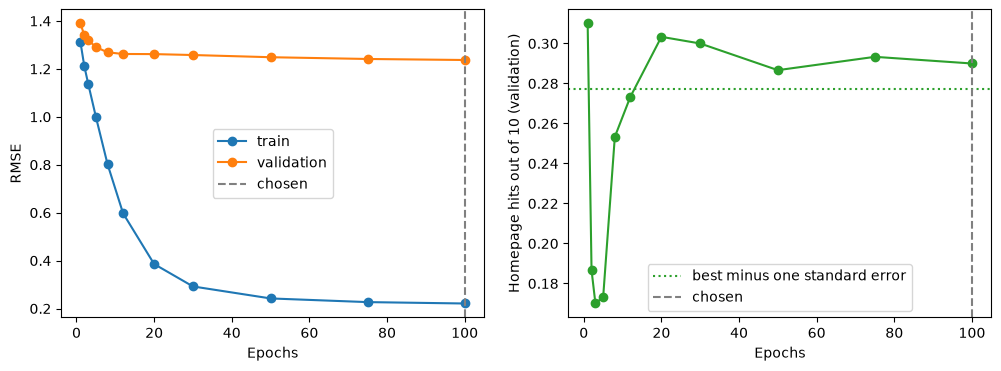

,epochs,train RMSE,validation RMSE,hits out of 10,hits standard error
0,1,1.314,1.389,0.310,0.033
1,2,1.212,1.342,0.187,0.024
2,3,1.139,1.320,0.170,0.025
3,5,0.999,1.291,0.173,0.026
4,8,0.802,1.269,0.253,0.035
5,12,0.597,1.262,0.273,0.037
6,20,0.386,1.262,0.303,0.039
7,30,0.292,1.258,0.300,0.037
8,50,0.242,1.249,0.287,0.035
9,75,0.227,1.241,0.293,0.036


In [35]:
# 75 and 100 epochs are included so the choice is not stuck at the edge of the grid
epochs_list = [1, 2, 3, 5, 8, 12, 20, 30, 50, 75, 100]
train_testset = tune_trainset.build_testset()

rows = []
for n_epochs in epochs_list:
    algo = SVD(n_factors=best_n_factors, n_epochs=n_epochs, random_state=my_seed)
    algo.fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    row = {"epochs": n_epochs,
           "train RMSE": accuracy.rmse(algo.test(train_testset), verbose=False),
           "validation RMSE": accuracy.rmse(algo.test(tune_valset), verbose=False)}
    row.update(homepage_hits(top_n, tune_valset))
    rows.append(row)
epochs_df = pd.DataFrame(rows)

# Classic early stopping uses the lowest validation RMSE. The choice here uses the
# one-standard-error rule on the homepage hits, like every other choice in this part
rmse_epochs = int(epochs_df.loc[epochs_df["validation RMSE"].idxmin(), "epochs"])
best_epochs = int(choose_setting(epochs_df, rmse_column="validation RMSE")["epochs"])
best_hits_row = epochs_df.loc[epochs_df["hits out of 10"].idxmax()]
print("Epochs with the lowest validation RMSE:", rmse_epochs)
print("Epochs with the most homepage hits:", int(best_hits_row["epochs"]))
print("Epochs chosen with the one-standard-error rule:", best_epochs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_df["epochs"], epochs_df["train RMSE"], marker="o", label="train")
axes[0].plot(epochs_df["epochs"], epochs_df["validation RMSE"], marker="o", label="validation")
axes[0].axvline(best_epochs, color="grey", linestyle="--", label="chosen")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("RMSE")
axes[0].legend()
axes[1].plot(epochs_df["epochs"], epochs_df["hits out of 10"], marker="o", color="tab:green")
axes[1].axhline(best_hits_row["hits out of 10"] - best_hits_row["hits standard error"], color="tab:green",
                linestyle=":", label="best minus one standard error")
axes[1].axvline(best_epochs, color="grey", linestyle="--", label="chosen")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Homepage hits out of 10 (validation)")
axes[1].legend()
plt.show()

epochs_df[["epochs", "train RMSE", "validation RMSE", "hits out of 10", "hits standard error"]].round(3)


**More training keeps improving the ratings, while the homepage hits stop changing after about 20 epochs.** The train RMSE falls from 1.314 after one epoch to 0.221 after 100, and the validation RMSE falls too, from 1.389 to 1.237. Within this range the model does not overfit in the classic sense, where the validation error starts to rise again and training should stop [14]. The gap between train and validation is large, but extra epochs still improve the predictions on unseen ratings.

The homepage hits behave differently. They are highest after a single epoch (0.310), drop to 0.170 after three epochs and recover to about 0.29 from 20 epochs on. In one epoch the anime with many ratings get the most updates, so the ranking favors famous, well-liked anime, much like the popularity models in Part 2. As the factors learn, the ranking becomes more personal, first worse and then better. The dotted line in the plot shows that every setting from 20 epochs on is within one standard error of the best.

The one-standard-error rule from 3.1 therefore decides by validation RMSE, which gives 100 epochs. Choosing the single highest number of hits would have given 1 epoch, and an earlier run of this notebook did exactly that. On test, that model had a coverage of 3.3% and a personalization of 0.700, against 16.8% and 0.927 now, for the same number of hits within noise. This is the kind of noise the rule protects against.

100 is the end of the grid, and the validation RMSE is still falling there. The gain is small and getting smaller: 0.009 from 30 to 50 epochs, 0.008 from 50 to 75 and 0.004 from 75 to 100. Every extra epoch adds training time, so 100 is kept as a practical stopping point. A longer grid could lower the RMSE by a few thousandths, which would not change any conclusion.

## 3.5 What the latent factors learn

To see what matrix factorization learns, an SVD with only 2 factors is trained, so that every anime becomes a point in a plane. The factors are then compared with the genres, which the model never saw. Only anime with at least 200 ratings are used, since the factors of rarely rated anime are not reliable.

In [36]:
svd_2d = SVD(n_factors=2, n_epochs=20, random_state=my_seed)
svd_2d.fit(trainset)

item_factors = pd.DataFrame(svd_2d.qi, columns=["dim 1", "dim 2"],
                            index=[trainset.to_raw_iid(i) for i in range(trainset.n_items)])
n_ratings = ratings_per_anime_df["count"].reindex(item_factors.index)

# Only anime with enough ratings, as the factors of rarely rated anime are not reliable
popular_factors = item_factors[n_ratings >= 200]
genres_popular = genres_df.reindex(popular_factors.index).fillna(0)
genre_corr = pd.DataFrame({dim: genres_popular.corrwith(popular_factors[dim]) for dim in popular_factors.columns}).dropna()

print("Anime in the plot:", len(popular_factors))
for dim in genre_corr.columns:
    ordered = genre_corr[dim].sort_values()
    print(dim, "- most negative genres:", list(ordered.index[:3]), " most positive genres:", list(ordered.index[-3:]))

Anime in the plot: 1168
dim 1 - most negative genres: ['Drama', 'Psychological', 'Mystery']  most positive genres: ['Harem', 'Ecchi', 'Comedy']
dim 2 - most negative genres: ['Harem', 'Ecchi', 'Romance']  most positive genres: ['Drama', 'Psychological', 'Dementia']


In [37]:
print(genre_corr.loc[["Drama", "Psychological", "Mystery", "Harem", "Ecchi", "Comedy", "Romance"]].round(2))
print("Correlation between the two factors:", round(popular_factors["dim 1"].corr(popular_factors["dim 2"]), 2))

               dim 1  dim 2
Drama          -0.28   0.17
Psychological  -0.25   0.18
Mystery        -0.22   0.10
Harem           0.24  -0.36
Ecchi           0.30  -0.36
Comedy          0.31  -0.01
Romance        -0.02  -0.22
Correlation between the two factors: -0.24


### Latent factor plot

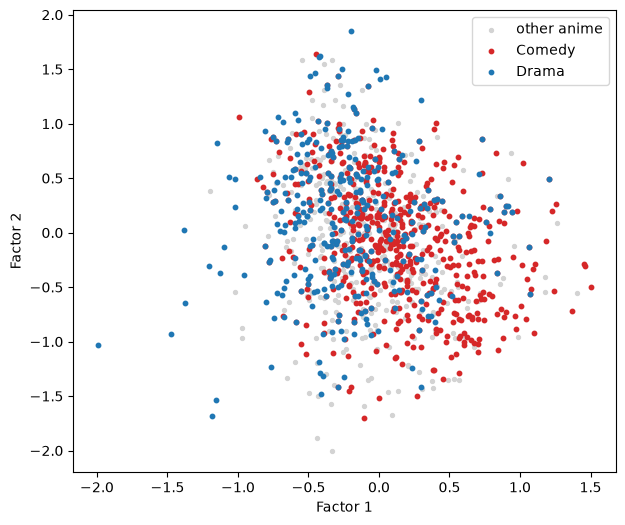

dim 1 low end:  ['School Days (6.28)', 'Elfen Lied (7.85)', 'Hoshi no Koe (7.58)', 'Tenshi Kinryouku (6.45)', 'Re:Zero kara Hajimeru Isekai Seikatsu (8.39)']
dim 1 high end: ['Kiss x Sis (TV) (6.99)', 'Aki-Sora: Yume no Naka (6.12)', 'Naruto: Dai Katsugeki!! Yuki Hime Shinobu Houjou Dattebayo! Special: Konoha Annual Sports Festival (7.00)', 'Naruto (7.56)', 'Dragon Ball GT (6.67)']
dim 2 low end:  ['Sword Art Online (7.77)', 'Diabolik Lovers (5.27)', 'Isekai wa Smartphone to Tomo ni. (6.46)', 'Tokyo Ghoul √A (7.22)', 'Seiken Tsukai no World Break (6.98)']
dim 2 high end: ['Mononoke (8.27)', 'Neon Genesis Evangelion: The End of Evangelion (8.37)', 'Serial Experiments Lain (7.87)', 'Yojouhan Shinwa Taikei (8.38)', 'Texhnolyze (7.63)']


In [38]:
genre_a = genre_corr["dim 1"].idxmax()
genre_b = genre_corr["dim 1"].idxmin()

plt.figure(figsize=(7, 6))
plt.scatter(popular_factors["dim 1"], popular_factors["dim 2"], s=8, color="lightgrey", label="other anime")
for genre, color in [(genre_a, "tab:red"), (genre_b, "tab:blue")]:
    in_genre = genres_popular[genre] == 1
    plt.scatter(popular_factors.loc[in_genre, "dim 1"], popular_factors.loc[in_genre, "dim 2"], s=10, color=color, label=genre)
plt.xlabel("Factor 1")
plt.ylabel("Factor 2")
plt.legend()
plt.show()

# The anime at the two ends of each factor, with their mean score in the training data
for dim in ["dim 1", "dim 2"]:
    ordered = popular_factors[dim].sort_values()
    print(dim, "low end: ", [f"{titles[i]} ({ratings_per_anime_df.loc[i, 'mean']:.2f})" for i in ordered.index[:5]])
    print(dim, "high end:", [f"{titles[i]} ({ratings_per_anime_df.loc[i, 'mean']:.2f})" for i in ordered.index[-5:]])

**Without ever seeing a genre, the two factors separate serious from light anime and acclaimed from mainstream anime.** Factor 1 runs from serious to light. Drama (−0.28), Psychological (−0.25) and Mystery (−0.22) correlate negatively with it, and Comedy (0.31), Ecchi (0.30) and Harem (0.24) positively. The anime at its ends agree. The low end has dark, violent or tragic stories such as School Days, Elfen Lied and Re:Zero. The high end has ecchi comedies such as Kiss x Sis and long action series such as Naruto and Dragon Ball GT. In the plot, Comedy anime lean to the right and Drama anime to the left.

Factor 2 looks like the blockbuster against arthouse axis in the course example [18, slide 29]. Its low end has mainstream titles with low or average scores, such as Diabolik Lovers (mean 5.27), Isekai wa Smartphone to Tomo ni. (6.46) and Sword Art Online (7.77). Its high end has acclaimed, experimental anime such as The End of Evangelion (8.37), Serial Experiments Lain (7.87) and Yojouhan Shinwa Taikei (8.38). Harem and Ecchi (both −0.36) and Romance (−0.22) pull toward the mainstream end, Drama and Psychological toward the other. Each anime also has its own bias, which already captures how well it is liked overall [1, pp. 106-107], so the factor does not measure quality as such. It separates the users who rate the acclaimed titles highly from the users who rate the mainstream ones highly.

The warrant is how matrix factorization works. Each factor groups anime that the same users rate in a similar way [1, pp. 94-95]. The model was never given the genres, so the genre pattern comes from the ratings alone. This is why collaborative filtering can personalize without any metadata.

The counterarguments limit how far this reading goes. The correlations are moderate, at most 0.36 in absolute value, so the genres explain only part of each factor. The two factors are also correlated (−0.24), so they are not two separate tastes. The sign of a factor is arbitrary: multiplying the user and the anime factors by −1 gives the same predictions [1, p. 94], so only the contrast between the two ends has meaning. Finally, 2 factors are used here only to make a plot. The tuned SVD has many more, and those cannot be read one by one.

## 3.6 NMF

In [39]:
nmf_tuning = pd.DataFrame([
    dict({"n_factors": n_factors}, **validate(NMF(n_factors=n_factors, random_state=my_seed)))
    for n_factors in [1, 15, 100]
])
print(nmf_tuning.round(3).to_string(index=False))
best_nmf_factors = int(choose_setting(nmf_tuning)["n_factors"])
print("Best n_factors:", best_nmf_factors)

 n_factors  RMSE  NDCG@10  MAP@10  hits out of 10  hits standard error  users with at least 1 hit %
         1 4.517    0.948   0.805           0.000                0.000                        0.000
        15 2.155    0.943   0.787           0.017                0.007                        1.667
       100 2.668    0.911   0.670           0.017                0.009                        1.333
Best n_factors: 15


**NMF is the weakest model on every metric that matters for the homepage.** Its validation RMSE is 2.155 at best, against about 1.24 for SVD, and it finds almost no relevant anime (0.017 hits out of 10). Surprise's NMF has no global mean or bias terms by default [19], so it has to rebuild every rating from non-negative factors. Most ratings in this data are high (the global mean is 7.56), so much of the factors' capacity goes into reproducing the general level of the ratings instead of the differences between users. One factor is worst (RMSE 4.517 and no hits), and 100 factors overfit (NDCG 0.911 and MAP 0.670, against 0.943 and 0.787 for 15). 15 factors, the Surprise default, and 100 factors tie on hits within one standard error, and 15 is chosen for its lower RMSE.

The usual argument for NMF is that non-negative factors are easier to interpret than those of SVD [1, p. 94]. Here that does not make up for its weak predictions, so NMF is not used in the following parts.

## 3.7 Final comparison

In [40]:
cf_models = {
    "User KNN": KNNBaseline(k=int(best_user["k"]), min_k=min(int(best_user["k"]), 5), verbose=False,
                            sim_options={"name": best_user["similarity"], "user_based": True, "min_support": int(best_user["min_support"])}),
    "Item KNN": KNNBaseline(k=int(best_item["k"]), min_k=min(int(best_item["k"]), 5), verbose=False,
                            sim_options={"name": best_item["similarity"], "user_based": False, "min_support": int(best_item["min_support"])}),
    "SVD": SVD(n_factors=best_n_factors, n_epochs=best_epochs, random_state=my_seed),
    "NMF": NMF(n_factors=best_nmf_factors, random_state=my_seed),
}

results_cf = {name: evaluate_model(algo) for name, algo in cf_models.items()}
results_part3_df = pd.concat([results_part2_df, pd.DataFrame(results_cf).T])
results_part3_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.812,0.042,0.007,4.1,83.13,0.998,0.192
Popular,1.552,1.184,0.932,0.784,0.509,0.912,0.000,0.000,0.0,0.33,0.077,0.141
Bayesian popular,1.586,1.208,0.931,0.780,0.507,0.910,0.875,0.039,49.2,1.31,0.407,0.267
Most rated,5.268,4.915,0.898,0.676,0.448,0.865,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,0.865,1.634,0.054,69.6,3.84,0.791,0.316
User KNN,1.215,0.905,0.943,0.817,0.529,0.926,0.353,0.024,24.8,5.68,0.790,0.266
Item KNN,1.195,0.888,0.946,0.827,0.534,0.931,0.424,0.026,28.2,9.70,0.763,0.267
SVD,1.222,0.912,0.943,0.816,0.527,0.927,0.673,0.034,41.0,16.78,0.927,0.255
NMF,2.150,1.883,0.926,0.762,0.496,0.903,0.040,0.006,3.9,4.57,0.554,0.164


**On ratings collaborative filtering wins, on the homepage the popularity models still win.** SVD and the two KNN models predict ratings much better than any non-personalized model: RMSE 1.195 for item KNN, 1.215 for user KNN and 1.222 for SVD, against 1.552 for popular. They also order each user's test items best (NDCG@10 for users with 20 or more test items: 0.926 to 0.931, against 0.912). On the homepage the order is reversed. SVD finds 0.673 relevant anime per 10, item KNN 0.424 and user KNN 0.353, against 1.449 for most rated and 1.634 for demographic.

The reason is what each measure asks. RMSE and NDCG only look at anime the user has already watched and ask how much the user liked them. A homepage hit also needs the user to have chosen to watch the anime, and that choice depends heavily on popularity. The test ratings are not missing at random: users rate what they chose to watch, and they choose famous anime more often [1, pp. 250-251]. A model that recommends the most watched anime is rewarded for predicting the choice, not the taste. Collaborative filtering predicts the taste, so its top 10 holds more varied and less famous anime, which a user may well like but has less often watched, and so rated, yet. Offline evaluation cannot tell these two cases apart [6, p. 97].

SVD is the most useful CF model for the business. It has more hits than the two KNN models and reaches 41.0% of users. It also shows by far the widest catalog of all models except random, 16.8% against 1.7% for most rated and 3.8% for demographic, with the highest personalization (0.927). The KNN models predict ratings slightly better, but item KNN shows only 9.7% of the catalog and finds fewer relevant anime. NMF is not competitive on any metric.

## 3.8 Stability of the final models with 5-fold cross-validation

The table above comes from one split. Cross-validation repeats the training and testing on 5 different splits of all ratings and reports the mean and the standard deviation of the error across them [5]. A small standard deviation means the error does not depend on which ratings happen to be in the test set. Only RMSE and MAE are cross-validated: the homepage hits would need the whole catalogue to be ranked five times for every model, and their reliability is already shown by the standard error in the table above.

In [41]:
cv_rows = {}
for name, algo in cf_models.items():
    cv = cross_validate(algo, data, measures=["RMSE", "MAE"], cv=KFold(n_splits=5, random_state=my_seed), verbose=False)
    cv_rows[name] = {"RMSE mean": cv["test_rmse"].mean(), "RMSE std": cv["test_rmse"].std(),
                     "MAE mean": cv["test_mae"].mean(), "MAE std": cv["test_mae"].std()}

pd.DataFrame(cv_rows).T.round(3)

,RMSE mean,RMSE std,MAE mean,MAE std
User KNN,1.218,0.002,0.908,0.002
Item KNN,1.199,0.002,0.891,0.002
SVD,1.225,0.002,0.915,0.002
NMF,2.152,0.002,1.885,0.002


**The ranking on ratings does not depend on the split.** Over 5 folds the mean RMSE is 1.199 for item KNN, 1.218 for user KNN, 1.225 for SVD and 2.152 for NMF, each with a standard deviation of 0.002. The means are close to the single-split results in 3.7 (1.195, 1.215, 1.222 and 2.150), so that split was neither lucky nor unlucky. The smallest gap, 0.007 between user KNN and SVD, is still more than three times the standard deviation, so even that order is unlikely to change with another split. The spread is small because every fold tests on about 195,000 ratings, so a few unusual users barely move the average.

Cross-validation here covers only RMSE and MAE. For the homepage hits the standard errors in 3.7 play the same role. The gap between SVD (0.673, standard error 0.034) and most rated (1.449, standard error 0.050) is far larger than either, so the main conclusion of this part does not depend on the split either.

## 3.9 Conclusion of Part 3

**SVD is the collaborative filtering model carried forward, as the personal component of the hybrid.**

| Model | Strength | Weakness | Role |
|---|---|---|---|
| User KNN | Accurate ratings (RMSE 1.215) | Fewest hits of SVD and the two KNN models, 5.7% coverage | Not used further |
| Item KNN | Most accurate ratings (RMSE 1.195) | 0.424 hits, 9.7% coverage | Not used further |
| SVD | Most hits of the CF models, widest catalog (16.8%), most personalized | Fewer hits than most rated and demographic | Personal component of the hybrid in Part 5 |
| NMF | Interpretable factors | Weak on every metric | Rejected |

Choosing SVD over item KNN trades a little rating accuracy (1.222 against 1.195) for 59% more hits and 73% more of the catalog, which is the better trade for a homepage. No CF model beats most rated on the homepage, so collaborative filtering alone would not be the right homepage for this platform. The counterargument is the bias of the offline test explained in 3.7, which favors popular anime and may understate what personal recommendations are worth to real users. The answer is not to choose one or the other. Part 5 combines SVD's reach across the catalog with the hits of the popularity models.

# Part 4. Content-based

Content-based recommenders use the anime metadata instead of the ratings of other users [1, p. 139]. This part first compares ways to represent an anime as a vector: numerical features, categorical features, Bag of Words, TF-IDF, lemmatized TF-IDF, Sentence-BERT and named entities [8]. Each representation gives a similarity between every pair of anime (4.2 to 4.9). These similarities are then turned into recommendations for users (4.10), the settings are chosen on the validation split (4.11) and the result is evaluated with the Part 1 metrics (4.12). The data is `anime_df` from Part 1.

## 4.1 Prepare the anime catalog

In [42]:
import re
from collections import Counter
from itertools import combinations

import nltk
from nltk.stem import WordNetLemmatizer
from scipy.sparse import hstack, csr_matrix
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer, OneHotEncoder
from surprise import PredictionImpossible
from transformers import pipeline

# Matrix products on some macOS setups raise false floating point warnings ("divide by zero", "overflow").
# They are switched off here, and the similarity matrices are checked for NaN and infinite values below.
old_error_settings = np.seterr(divide="ignore", over="ignore", invalid="ignore")

/Users/estellearnander/sem5/RE/recsys_group_project/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1122 02:19:13.278000 1398 venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [43]:
# The catalogue from Part 1. The ratings and users are not needed here
anime = anime_df.copy().reset_index(drop=True)
print("Anime:", anime.shape)
display(anime.head())

Anime: (6668, 15)


,anime_id,title,type,source,episodes,rating,score,scored_by,popularity,members,studio,genre,duration_min,aired_from_year,synopsis
0,11013,Inu x Boku SS,TV,Manga,12,PG-13 - Teens 13 or older,7.63,139250,231,283882,David Production,"Comedy, Supernatural, Romance, Shounen",24.0,2012.0,chiyo Shirakiin is the sheltered daughter of a...
1,2104,Seto no Hanayome,TV,Manga,26,PG-13 - Teens 13 or older,7.89,91206,366,204003,Gonzo,"Comedy, Parody, Romance, School, Shounen",24.0,2007.0,"During his summer vacation, middle school stud..."
2,5262,Shugo Chara!! Doki,TV,Manga,51,PG - Children,7.55,37129,1173,70127,Satelight,"Comedy, Magic, School, Shoujo",24.0,2008.0,Now Utau has left Easter and restarted her sin...
3,721,Princess Tutu,TV,Original,38,PG-13 - Teens 13 or older,8.21,36501,916,93312,Hal Film Maker,"Comedy, Drama, Magic, Romance, Fantasy",16.0,2002.0,"In a fairy tale come to life, the clumsy, swee..."
4,12365,Bakuman. 3rd Season,TV,Manga,25,PG-13 - Teens 13 or older,8.67,107767,426,182765,J.C.Staff,"Comedy, Drama, Romance, Shounen",24.0,2012.0,"Onto their third serialization, manga duo Mori..."


In [44]:
print(anime.columns.tolist())
print(anime.dtypes)
missing = anime.isna().sum()
display(pd.DataFrame({"Missing": missing, "Percent": (missing / len(anime) * 100).round(2)}).sort_values("Missing", ascending=False))
expected_columns = ["anime_id", "title", "type", "genre", "episodes", "synopsis"]
print("Required columns present:", all(c in anime.columns for c in expected_columns))
print("Duplicate anime IDs:", anime["anime_id"].duplicated().sum())
print("Duplicate titles:", anime["title"].duplicated().sum())

['anime_id', 'title', 'type', 'source', 'episodes', 'rating', 'score', 'scored_by', 'popularity', 'members', 'studio', 'genre', 'duration_min', 'aired_from_year', 'synopsis']
anime_id             int64
title                  str
type                   str
source                 str
episodes             int64
rating                 str
score              float64
scored_by            int64
popularity           int64
members              int64
studio                 str
genre                  str
duration_min       float64
aired_from_year    float64
synopsis               str
dtype: object


,Missing,Percent
synopsis,345,5.17
rating,82,1.23
genre,4,0.06
anime_id,0,0.00
title,0,0.00
type,0,0.00
source,0,0.00
episodes,0,0.00
score,0,0.00
scored_by,0,0.00


Required columns present: True
Duplicate anime IDs: 0
Duplicate titles: 0


Average synopsis length: 83.64457108578284
Median synopsis length: 75.0
Empty synopses: 345
Short synopses (under 30 words): 1807


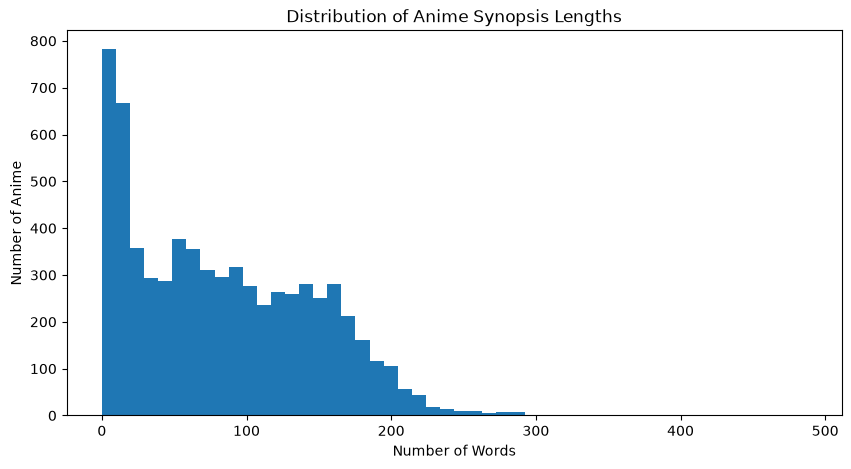

In [45]:
anime["synopsis_length"] = ( anime["synopsis"] .fillna("")  .str.split() .str.len())
print("Average synopsis length:", anime["synopsis_length"].mean())
print("Median synopsis length:",anime["synopsis_length"].median())
print("Empty synopses:",(anime["synopsis_length"] == 0).sum())
print("Short synopses (under 30 words):",(anime["synopsis_length"] < 30).sum())

plt.figure(figsize=(10, 5))
plt.hist(
    anime["synopsis_length"],bins=50)
plt.title("Distribution of Anime Synopsis Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Anime")

plt.show()

In [46]:
anime_clean = anime.copy().reset_index(drop=True)
print("Original dataset:", anime.shape)
print("Working dataset:", anime_clean.shape)

Original dataset: (6668, 16)
Working dataset: (6668, 16)


In [47]:

anime_clean["synopsis"] = anime_clean["synopsis"].fillna("")
anime_clean["genre"] = anime_clean["genre"].fillna("")
anime_clean["studio"] = anime_clean["studio"].fillna("")

print(anime_clean[["synopsis", "genre", "studio"]].isnull().sum())

synopsis    0
genre       0
studio      0
dtype: int64


In [48]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

for col in ["title", "genre", "synopsis"]:
    anime_clean[col + "_clean"] = anime_clean[col].apply(clean_text)
anime_clean["content"] = anime_clean[["title_clean", "genre_clean", "synopsis_clean"]].agg(" ".join, axis=1)
display(anime_clean[["title", "genre", "content"]].head())

,title,genre,content
0,Inu x Boku SS,"Comedy, Supernatural, Romance, Shounen",inu x boku ss comedy supernatural romance shou...
1,Seto no Hanayome,"Comedy, Parody, Romance, School, Shounen",seto no hanayome comedy parody romance school ...
2,Shugo Chara!! Doki,"Comedy, Magic, School, Shoujo",shugo chara doki comedy magic school shoujo no...
3,Princess Tutu,"Comedy, Drama, Magic, Romance, Fantasy",princess tutu comedy drama magic romance fanta...
4,Bakuman. 3rd Season,"Comedy, Drama, Romance, Shounen",bakuman 3rd season comedy drama romance shoune...


**Most anime have a usable synopsis, but a large minority have very little text.** 345 synopses are missing (5.17%), as are 4 genres (0.06%) and 82 content ratings (1.23%). Missing text fields are filled with empty strings, so no anime is removed from the catalog. A synopsis has 83.6 words on average and 75 words at the median, but 1,807 synopses have fewer than 30 words. The text is lowercased, punctuation is removed and the spaces are normalized, and title, genre and synopsis are joined into one `content` field. The original title and synopsis are kept for display and for named entity recognition, which needs capital letters.

The consequence is that for more than a quarter of the catalog (the 1,807 short synopses, which include the 345 missing ones) the text representations depend mostly on the title and the genres. Content-based recommendations for these anime rest on much less information than for anime with a full synopsis.

## 4.2 Numerical similarity

In [49]:
num_columns = ["episodes", "duration_min", "aired_from_year"]
anime_num = anime_clean[num_columns].apply(pd.to_numeric, errors="coerce")
display(anime_num.describe())
print("Missing values:\n", anime_num.isna().sum())

,episodes,duration_min,aired_from_year
count,6668.000000,6668.000000,6668.000000
mean,14.276395,28.442167,2006.915267
std,40.906929,25.365980,10.381425
min,0.000000,0.000000,1942.000000
25%,1.000000,17.000000,2003.000000
50%,6.000000,24.000000,2010.000000
75%,13.000000,27.000000,2015.000000
max,1818.000000,163.000000,2018.000000


Missing values:
 episodes           0
duration_min       0
aired_from_year    0
dtype: int64


In [50]:
anime_num = anime_num.fillna(anime_num.median())
num_distance = euclidean_distances(anime_num)
scaler = StandardScaler()
anime_num_scaled = scaler.fit_transform(anime_num)
num_distance_scaled = euclidean_distances(anime_num_scaled)
print("Raw:", num_distance.shape, "Scaled:", num_distance_scaled.shape)

Raw: (6668, 6668) Scaled: (6668, 6668)


**The numerical features are on very different scales.** Episodes range from 0 to 1,818, minutes per episode from 0 to 163 and the start year from 1942 to 2018. Without standardization, the number of episodes decides almost every distance. A value of 0 for episodes or minutes most likely means unknown rather than zero (see 4.11).

Both matrices hold distances, so a smaller value means two anime are closer. This is the opposite of the cosine similarities used from 4.3 on, where a larger value means more similar.

In [51]:
def title_index(title):
    matches = anime_clean.index[anime_clean["title"].str.casefold() == title.casefold()]
    if len(matches) == 0:
        raise ValueError(f"Anime not found: {title}")
    return int(matches[0])

def recommend_from_matrix(title, matrix, top_n=10, distance=False, columns=None):
    idx = title_index(title)
    scores = pd.Series(matrix[idx]).drop(idx)
    scores = scores.nsmallest(top_n) if distance else scores.nlargest(top_n)
    columns = columns or ["title", "genre"]
    result = anime_clean.iloc[scores.index][columns].copy()
    result["distance" if distance else "similarity"] = scores.to_numpy().round(4)
    return result.reset_index(drop=True)

raw = recommend_from_matrix("Death Note", num_distance, distance=True, columns=["title", *num_columns])
scaled = recommend_from_matrix("Death Note", num_distance_scaled, distance=True, columns=["title", *num_columns])
display(pd.DataFrame({"Without normalization": raw["title"], "Raw distance": raw["distance"], "With normalization": scaled["title"], "Scaled distance": scaled["distance"]}))

# The two distance matrices are only needed for this example, so they are removed to save memory
del num_distance, num_distance_scaled

,Without normalization,Raw distance,With normalization,Scaled distance
0,Gallery Fake,2.2361,Otogi Juushi Akazukin,0.0628
1,Otogi Juushi Akazukin,2.2361,Saiunkoku Monogatari,0.0928
2,Yuki no Joou (TV),2.4495,Gallery Fake,0.1245
3,Saiunkoku Monogatari,2.8284,Yuki no Joou (TV),0.1269
4,Saiunkoku Monogatari 2nd Season,3.0000,Saiunkoku Monogatari 2nd Season,0.1337
5,Kyou kara Maou! 3rd Series,3.0000,Kyou kara Maou! 3rd Series,0.2026
6,Agatha Christie no Meitantei Poirot to Marple,3.4641,Agatha Christie no Meitantei Poirot to Marple,0.2138
7,Mermaid Melody Pichi Pichi Pitch Pure,3.4641,Mermaid Melody Pichi Pichi Pitch Pure,0.2138
8,Hanasakeru Seishounen,3.7417,Nana,0.2445
9,Element Hunters,3.7417,Tengen Toppa Gurren Lagann,0.2657


**Standardization changes the ranking, but neither list is a good recommendation.** The raw and standardized top 10 for Death Note differ in order and in two titles (Hanasakeru Seishounen and Element Hunters against Nana and Tengen Toppa Gurren Lagann). Without standardization the number of episodes dominates, as explained above. But even the standardized list holds anime such as Otogi Juushi Akazukin and Saiunkoku Monogatari, which share the format and age of Death Note but nothing of its story. The numerical features describe the format of an anime, not its content, so on their own they are not a content-based recommender. They are used in 4.11 only as a small addition to the text and genres.

## 4.3 Categorical similarity

In [52]:
cat_columns = ["genre", "type", "source", "studio"]
anime_cat = anime_clean[cat_columns].copy()
for col in cat_columns:
    print(col, "unique values:", anime_cat[col].nunique())

genres = anime_cat["genre"].fillna("").astype(str).str.split(", ")
mlb = MultiLabelBinarizer()
genre_matrix = csr_matrix(mlb.fit_transform(genres))
encoder = OneHotEncoder(handle_unknown="ignore")
other_matrix = encoder.fit_transform(anime_cat[["type", "source", "studio"]])
cat_matrix = hstack([genre_matrix, other_matrix]).tocsr()
cat_similarity = cosine_similarity(cat_matrix)
print("Categorical matrix:", cat_matrix.shape)
print("Number of genres:", len(mlb.classes_))
display(recommend_from_matrix("Death Note", cat_similarity, columns=["title", *cat_columns]))

genre unique values: 3204
type unique values: 6
source unique values: 15
studio unique values: 711
Categorical matrix: (6668, 776)
Number of genres: 44


,title,genre,type,source,studio,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",Special,Manga,Madhouse,0.8250
1,Mirai Nikki (TV),"Action, Psychological, Supernatural, Thriller,...",TV,Manga,Asread,0.7778
2,Monster,"Drama, Horror, Mystery, Police, Psychological,...",TV,Manga,Madhouse,0.7379
3,Mousou Dairinin,"Mystery, Dementia, Police, Psychological, Supe...",TV,Original,Madhouse,0.7379
4,Majin Tantei Nougami Neuro,"Mystery, Comedy, Demons, Supernatural, Shounen",TV,Manga,Madhouse,0.7071
5,Mouryou no Hako,"Mystery, Psychological, Supernatural, Thriller...",TV,Novel,Madhouse,0.7071
6,Top Secret: The Revelation,"Sci-Fi, Mystery, Police, Psychological, Shoujo",TV,Manga,Madhouse,0.7071
7,Higurashi no Naku Koro ni Kai,"Mystery, Psychological, Supernatural, Thriller",TV,Visual novel,Studio Deen,0.6299
8,Touhai Densetsu Akagi: Yami ni Maiorita Tensai,"Game, Psychological, Thriller, Seinen",TV,Manga,Madhouse,0.6299
9,Gyakkyou Burai Kaiji: Hakairoku-hen,"Game, Psychological, Thriller, Seinen",TV,Manga,Madhouse,0.6299


**Genres, type, source and studio find anime with a similar profile, and also show the main weakness of content-based recommendations.** There are 44 genres, and each anime can have several, so they are encoded as one indicator per genre. Type, source and studio are encoded separately, which gives 776 features for 6,668 anime. Every indicator counts equally in the cosine similarity.

For Death Note the list is far more relevant than the numerical one. Mirai Nikki (TV) (0.7778), Monster (0.7379) and Mousou Dairinin (0.7379) share psychological, mystery or supernatural genres. Eight of the top 10 also come from the same studio, Madhouse, and a shared studio raises the score even when the stories differ.

The first recommendation is Death Note: Rewrite (0.8250), a special that retells the series. This is the main weakness of content-based recommendations, which Aggarwal calls overspecialization: they find anime very similar to what the user already knows, here often sequels, specials and recaps of the same series [1, pp. 161-162]. Such recommendations are relevant but obvious, and they add little discovery, since the user would often have found them anyway [1, p. 233].

## 4.4 Bag of Words

In [53]:
bow_vectorizer = CountVectorizer(stop_words="english", max_features=10000)
bow_matrix = bow_vectorizer.fit_transform(anime_clean["content"])
bow_similarity = cosine_similarity(bow_matrix)

print("BoW matrix shape:", bow_matrix.shape)
display(recommend_from_matrix("Death Note", bow_similarity))

BoW matrix shape: (6668, 10000)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.4168
1,Soul Eater,"Action, Fantasy, Comedy, Supernatural, Shounen",0.3144
2,Shinigami no Ballad.,"Drama, Fantasy, Psychological, Supernatural",0.2682
3,Dia Horizon (Kabu),"Action, Adventure, Magic, Fantasy",0.2540
4,Kite Liberator,"Action, Sci-Fi, Drama",0.2498
5,Death Parade,"Game, Mystery, Psychological, Drama, Thriller",0.2462
6,Soushisouai Note The Animation,Hentai,0.2146
7,Persona 3 the Movie 4: Winter of Rebirth,"Action, Supernatural, Fantasy",0.2078
8,Da Yu Hai Tang,"Adventure, Drama, Romance, Supernatural",0.2058
9,YAT Anshin! Uchuu Ryokou 2,"Adventure, Comedy, Sci-Fi, Shounen",0.2058


## 4.5 TF-IDF

In [54]:
tfidf_vectorizer = TfidfVectorizer(stop_words="english", max_features=10000)
tfidf_matrix = tfidf_vectorizer.fit_transform(anime_clean["content"])
tfidf_similarity = cosine_similarity(tfidf_matrix)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
display(recommend_from_matrix("Death Note", tfidf_similarity))

TF-IDF matrix shape: (6668, 10000)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.3687
1,Soushisouai Note The Animation,Hentai,0.2976
2,YAT Anshin! Uchuu Ryokou 2,"Adventure, Comedy, Sci-Fi, Shounen",0.2235
3,Shinigami no Ballad.,"Drama, Fantasy, Psychological, Supernatural",0.2181
4,Soul Eater,"Action, Fantasy, Comedy, Supernatural, Shounen",0.2148
5,Kite Liberator,"Action, Sci-Fi, Drama",0.1731
6,Dia Horizon (Kabu),"Action, Adventure, Magic, Fantasy",0.1673
7,Yami no Matsuei,"Comedy, Drama, Fantasy, Horror, Magic, Shoujo,...",0.1640
8,Death Parade,"Game, Mystery, Psychological, Drama, Thriller",0.1473
9,Bleach: Memories in the Rain,"Action, Adventure, Supernatural, Drama, Shounen",0.1446


In [55]:
bow_top10 = recommend_from_matrix("Death Note", bow_similarity)
tfidf_top10 = recommend_from_matrix("Death Note", tfidf_similarity)

comparison = pd.merge(
    bow_top10[["title", "similarity"]],
    tfidf_top10[["title", "similarity"]],
    on="title",
    how="outer",
    suffixes=("_bow", "_tfidf"))

comparison.columns = ["Anime", "Bag of Words", "TF-IDF"]
comparison = comparison.sort_values(
    by="Bag of Words",
    ascending=False,
    na_position="last")

display(comparison.round(4))

,Anime,Bag of Words,TF-IDF
2,Death Note: Rewrite,0.4168,0.3687
8,Soul Eater,0.3144,0.2148
7,Shinigami no Ballad.,0.2682,0.2181
4,Dia Horizon (Kabu),0.2540,0.1673
5,Kite Liberator,0.2498,0.1731
3,Death Parade,0.2462,0.1473
9,Soushisouai Note The Animation,0.2146,0.2976
6,Persona 3 the Movie 4: Winter of Rebirth,0.2078,NaN
1,Da Yu Hai Tang,0.2058,NaN
10,YAT Anshin! Uchuu Ryokou 2,0.2058,0.2235


**TF-IDF weighs words by how rare they are, which changes the ranking but also exposes the limit of word overlap.** Both vectorizers produce a 6,668 × 10,000 matrix. Bag of Words counts the words, while TF-IDF lowers the weight of words that appear in many descriptions [8]. Both put Death Note: Rewrite first (0.4168 and 0.3687).

TF-IDF ranks Soushisouai Note The Animation second (0.2976), against seventh for Bag of Words (0.2146). It shares the rare word "note" with Death Note but nothing else, and it is an adult anime. The similarity matrices include every anime, but the homepage never shows adult anime, because of the business rule in 1.6, so this match cannot reach a user. It is still a useful warning: a rare shared word can create a strong match between two unrelated anime.

## 4.6 Lemmatized TF-IDF

In [56]:
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    return " ".join(lemmatizer.lemmatize(word) for word in text.split())

anime_clean["synopsis_lem"] = anime_clean["synopsis_clean"].apply(lemmatize_text)
anime_clean["content_lem"] = anime_clean[["title_clean", "genre_clean", "synopsis_lem"]].agg(" ".join, axis=1)
tfidf_lem_vectorizer = TfidfVectorizer(stop_words="english", max_features=10000)
tfidf_lem_matrix = tfidf_lem_vectorizer.fit_transform(anime_clean["content_lem"])
tfidf_lem_similarity = cosine_similarity(tfidf_lem_matrix)
print("Lemmatized TF-IDF:", tfidf_lem_matrix.shape)
display(recommend_from_matrix("Death Note", tfidf_lem_similarity))

Lemmatized TF-IDF: (6668, 10000)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.3488
1,Soushisouai Note The Animation,Hentai,0.2863
2,Shinigami no Ballad.,"Drama, Fantasy, Psychological, Supernatural",0.2391
3,YAT Anshin! Uchuu Ryokou 2,"Adventure, Comedy, Sci-Fi, Shounen",0.2268
4,Soul Eater,"Action, Fantasy, Comedy, Supernatural, Shounen",0.1887
5,Yami no Matsuei,"Comedy, Drama, Fantasy, Horror, Magic, Shoujo,...",0.1790
6,Kite Liberator,"Action, Sci-Fi, Drama",0.1649
7,Dia Horizon (Kabu),"Action, Adventure, Magic, Fantasy",0.1596
8,Burn Up Scramble,"Action, Comedy, Drama, Ecchi, Police, Sci-Fi, ...",0.1583
9,Wild 7,"Action, Police, Drama, Shounen",0.1437


**Lemmatization barely changes the result.** Only the synopsis is lemmatized, with the WordNet lemmatizer, which treats every word as a noun. The title and the genre labels are left as they are. Reducing words to their base form merges variants such as "notes" and "note", which can change the similarities [8].

For Death Note, lemmatized TF-IDF still ranks Death Note: Rewrite first (0.3488) and Soushisouai Note The Animation second (0.2863). Its top 10 shares 8.7 titles on average with plain TF-IDF over the three example anime in 4.8. Lemmatization does not fix the word-overlap problem, because the misleading word is in the title, which is not lemmatized.

## 4.7 Sentence-BERT

In [57]:
model = SentenceTransformer("all-MiniLM-L6-v2")
bert_embeddings = model.encode(anime_clean["content"].tolist(), batch_size=32, show_progress_bar=True, convert_to_numpy=True)
bert_similarity = cosine_similarity(bert_embeddings)
print("Embeddings:", bert_embeddings.shape, "Similarity:", bert_similarity.shape)
display(recommend_from_matrix("Death Note", bert_similarity))

# The model is not needed after the embeddings are computed, so it is removed to save memory
del model

Batches: 100%|██████████| 209/209 [00:12<00:00, 16.97it/s]

Embeddings: (6668, 384) Similarity: (6668, 6668)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.6631
1,Yami no Matsuei,"Comedy, Drama, Fantasy, Horror, Magic, Shoujo,...",0.6184
2,Majin Tantei Nougami Neuro,"Mystery, Comedy, Demons, Supernatural, Shounen",0.5847
3,Yakushiji Ryouko no Kaiki Jikenbo,"Mystery, Police, Supernatural",0.5759
4,Kara no Kyoukai 7: Satsujin Kousatsu (Kou),"Action, Mystery, Supernatural, Romance, Thriller",0.5747
5,Angel Cop,"Action, Sci-Fi, Police",0.5692
6,Shinrei Tantei Yakumo,"Horror, Mystery, Shoujo, Supernatural",0.5691
7,UN-GO,"Mystery, Supernatural",0.5572
8,Yami Shibai,"Dementia, Horror, Demons, Supernatural",0.5568
9,ChäoS;HEAd,"Harem, Mystery, Psychological, Sci-Fi, Superna...",0.5533


**Sentence-BERT finds anime with a similar theme instead of shared words.** The all-MiniLM-L6-v2 model turns every `content` text into a vector of 384 numbers that represents its meaning [8]. For Death Note it ranks Death Note: Rewrite first (0.6631), followed by Yami no Matsuei (0.6184) and Majin Tantei Nougami Neuro (0.5847), detective and supernatural stories that do not share the title words. Its scores are not comparable with those of Bag of Words or TF-IDF, since each method has its own scale.

Whether a more meaningful similarity also gives better recommendations is a separate question. It is tested on the validation split in 4.11, not judged from this example.

## 4.8 Comparison of the text representations

In [58]:
methods = {"BoW": bow_similarity, "TF-IDF": tfidf_similarity, "Lemmatized TF-IDF": tfidf_lem_similarity, "BERT": bert_similarity}
comparison = pd.DataFrame()
for name, matrix in methods.items():
    result = recommend_from_matrix("Death Note", matrix)
    comparison[name] = result["title"]
    comparison[name + " score"] = result["similarity"]
comparison.index = range(1, len(comparison) + 1)
display(comparison)

,BoW,BoW score,TF-IDF,TF-IDF score,Lemmatized TF-IDF,Lemmatized TF-IDF score,BERT,BERT score
1,Death Note: Rewrite,0.4168,Death Note: Rewrite,0.3687,Death Note: Rewrite,0.3488,Death Note: Rewrite,0.6631
2,Soul Eater,0.3144,Soushisouai Note The Animation,0.2976,Soushisouai Note The Animation,0.2863,Yami no Matsuei,0.6184
3,Shinigami no Ballad.,0.2682,YAT Anshin! Uchuu Ryokou 2,0.2235,Shinigami no Ballad.,0.2391,Majin Tantei Nougami Neuro,0.5847
4,Dia Horizon (Kabu),0.2540,Shinigami no Ballad.,0.2181,YAT Anshin! Uchuu Ryokou 2,0.2268,Yakushiji Ryouko no Kaiki Jikenbo,0.5759
5,Kite Liberator,0.2498,Soul Eater,0.2148,Soul Eater,0.1887,Kara no Kyoukai 7: Satsujin Kousatsu (Kou),0.5747
6,Death Parade,0.2462,Kite Liberator,0.1731,Yami no Matsuei,0.1790,Angel Cop,0.5692
7,Soushisouai Note The Animation,0.2146,Dia Horizon (Kabu),0.1673,Kite Liberator,0.1649,Shinrei Tantei Yakumo,0.5691
8,Persona 3 the Movie 4: Winter of Rebirth,0.2078,Yami no Matsuei,0.1640,Dia Horizon (Kabu),0.1596,UN-GO,0.5572
9,Da Yu Hai Tang,0.2058,Death Parade,0.1473,Burn Up Scramble,0.1583,Yami Shibai,0.5568
10,YAT Anshin! Uchuu Ryokou 2,0.2058,Bleach: Memories in the Rain,0.1446,Wild 7,0.1437,ChäoS;HEAd,0.5533


**The four text representations agree on the obvious sequel and differ after it.** All four put Death Note: Rewrite first. After that, the three word-based methods share most of their lists, while Sentence-BERT finds different anime. Agreement on one sequel says nothing about which method is better for users, and the raw scores cannot be compared across methods. 4.11 makes the choice on the validation split instead.

## 4.9 Named entity recognition (exploratory)

Named entity recognition finds the names of people, places and organizations in a synopsis, so that two anime with the same characters or settings could be matched. The model is `dslim/bert-base-NER` from Hugging Face, which was trained on general English text. It can misread Japanese names and split them into fragments.

In [59]:
ner = pipeline("ner", model="dslim/bert-base-NER", aggregation_strategy="simple")
text = anime_clean.loc[title_index("Death Note"), "synopsis"]
display(pd.DataFrame(ner(text[:1500]))[["word", "entity_group", "score"]])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7559.63it/s]
[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,word,entity_group,score
0,Death Note,MISC,0.895890
1,R,PER,0.997150
2,##yu,PER,0.995996
3,##k,PER,0.832990
4,Death Note,MISC,0.940506
5,Light Yagami,PER,0.854753
6,Death Note,MISC,0.912459
7,Death Note,MISC,0.939820
8,Light,PER,0.998398
9,Light,PER,0.998350


**The model finds the main entities but splits Japanese names into fragments.** In the Death Note synopsis it recognizes Death Note and Light Yagami, but it splits Ryuk into the fragments R, ##yu and ##k. A general English model is not trained on Japanese names, so the extracted entities have to be cleaned before they can be used.

In [60]:
texts = anime_clean["synopsis"].fillna("").astype(str).tolist()

texts = [
    ner.tokenizer.decode(
        ner.tokenizer.encode(
            text,
            truncation=True,
            max_length=512
        ),
        skip_special_tokens=True
    )
    for text in texts]

ner_results = ner(texts, batch_size=16)

anime_clean["NER"] = [
    [
        (e["word"], e["entity_group"], round(float(e["score"]), 3))
        for e in entities
    ]
    for entities in ner_results]

display(anime_clean[["title", "synopsis", "NER"]].head(10))

,title,synopsis,NER
0,Inu x Boku SS,chiyo Shirakiin is the sheltered daughter of a...,"[(ch, PER, 0.603), (Shirak, PER, 0.76), (R, PE..."
1,Seto no Hanayome,"During his summer vacation, middle school stud...","[(Nagasumi Michishi, PER, 0.791), (Seto Inland..."
2,Shugo Chara!! Doki,Now Utau has left Easter and restarted her sin...,"[(U, PER, 0.998), (##u, PER, 0.653), (Easter, ..."
3,Princess Tutu,"In a fairy tale come to life, the clumsy, swee...","[(Ah, PER, 0.998), (Japanese, MISC, 0.996), (A..."
4,Bakuman. 3rd Season,"Onto their third serialization, manga duo Mori...","[(On, ORG, 0.606), (Mo, PER, 0.998), (##rita, ..."
5,Yume-iro Pâtissière,"side from her deep passion for eating cakes, t...","[(I, PER, 0.999), (##chi, PER, 0.9), (##go Ama..."
6,Ultra Maniac,Fantasies and miracles never interested Ayu Ta...,"[(A, PER, 0.999), (##yu Tateishi, PER, 0.978),..."
7,Shakugan no Shana II (Second),Denizens from the Crimson Realm continue to in...,"[(Crimson Realm, LOC, 0.736), (Misaki City, LO..."
8,Nodame Cantabile: Paris-hen,"Shinichi Chiaki conquers his fear of flying, a...","[(Shin, PER, 1.0), (##ichi Chiaki, PER, 0.974)..."
9,Ouran Koukou Host Club,Haruhi Fujioka is a bright scholarship candida...,"[(Ha, PER, 0.999), (##ru, PER, 0.702), (Fujiok..."


In [61]:
generic_entities = {
    "japanese", "japan", "english",
    "earth", "world", "light"}

def clean_entities(entities):
    cleaned = set()
    for name, label, score in entities:
        name = name.strip()
        normalized = name.casefold()
        if score < 0.85:
            continue
        if len(name) < 3:
            continue
        if "##" in name:
            continue
        if normalized in generic_entities:
            continue
        cleaned.add((normalized, label))
    return sorted(cleaned)

anime_clean["NER_clean"] = anime_clean["NER"].apply(clean_entities)
display(anime_clean[["title", "NER", "NER_clean"]].head(10))
entity_types = Counter()
entity_frequency = Counter()

for entities in anime_clean["NER_clean"]:
    entity_types.update(label for name, label in entities)
    entity_frequency.update(entities)

print("Entity types:", entity_types)
print("Anime with entities:", anime_clean["NER_clean"].apply(bool).sum())
print("Anime without entities:", anime_clean["NER_clean"].apply(bool).eq(False).sum())

display(pd.DataFrame(
    entity_frequency.most_common(20),
    columns=["Entity", "Anime Count"]))

,title,NER,NER_clean
0,Inu x Boku SS,"[(ch, PER, 0.603), (Shirak, PER, 0.76), (R, PE...","[(maison de ayakashi, LOC), (miketsuka, PER), ..."
1,Seto no Hanayome,"[(Nagasumi Michishi, PER, 0.791), (Seto Inland...","[(mio sun beach, LOC), (seto inland sea, LOC),..."
2,Shugo Chara!! Doki,"[(U, PER, 0.998), (##u, PER, 0.653), (Easter, ...","[(easter, PER), (guardians, ORG), (lulu, PER),..."
3,Princess Tutu,"[(Ah, PER, 0.998), (Japanese, MISC, 0.996), (A...",[]
4,Bakuman. 3rd Season,"[(On, ORG, 0.606), (Mo, PER, 0.998), (##rita, ...","[(shounen jack, MISC)]"
5,Yume-iro Pâtissière,"[(I, PER, 0.999), (##chi, PER, 0.9), (##go Ama...","[(henri, PER), (henri lucas, PER), (st. marie ..."
6,Ultra Maniac,"[(A, PER, 0.999), (##yu Tateishi, PER, 0.978),...","[(holy stones, MISC), (magic kingdom, LOC), (n..."
7,Shakugan no Shana II (Second),"[(Crimson Realm, LOC, 0.736), (Misaki City, LO...","[(midnight lost child, MISC), (misaki city, LO..."
8,Nodame Cantabile: Paris-hen,"[(Shin, PER, 1.0), (##ichi Chiaki, PER, 0.974)...","[(charles auclair, PER), (chi, PER), (conserva..."
9,Ouran Koukou Host Club,"[(Ha, PER, 0.999), (##ru, PER, 0.702), (Fujiok...","[(fujioka, PER), (honey, PER), (host club, ORG..."


Entity types: Counter({'PER': 6436, 'MISC': 3652, 'ORG': 2772, 'LOC': 1978})
Anime with entities: 5140
Anime without entities: 1528


,Entity,Anime Count
0,"(tokyo, LOC)",196
1,"(blu, MISC)",162
2,"(shi, PER)",136
3,"(chi, PER)",128
4,"(shin, PER)",122
5,"(mal news, ORG)",65
6,"(ann, ORG)",62
7,"(shu, PER)",57
8,"(crunchyroll, ORG)",57
9,"(sato, PER)",51


In [62]:
def recommend_ner(anime_title, top_n=10, max_frequency=10):
    matches = anime_clean.index[anime_clean["title"] == anime_title]
    if len(matches) == 0:
        print("Anime not found.")
        return pd.DataFrame()
    idx = matches[0]
    target = {
        entity
        for entity in anime_clean.loc[idx, "NER_clean"]
        if entity_frequency[entity] <= max_frequency}
    results = []
    for i, row in anime_clean.iterrows():
        if i == idx:
            continue
        shared = target.intersection(row["NER_clean"])
        if shared:
            results.append({
                "title": row["title"],
                "genre": row["genre"],
                "shared_entities": len(shared),
                "entities": sorted(shared)})
    columns = ["title", "genre", "shared_entities", "entities"]

    return (
        pd.DataFrame(results, columns=columns)
        .sort_values("shared_entities", ascending=False)
        .head(top_n)
        .reset_index(drop=True))

display(recommend_ner("Death Note"))
ner_top10 = recommend_ner("Death Note")
bert_top10 = recommend_from_matrix("Death Note", bert_similarity)

comparison_ner = pd.DataFrame({
    "NER": ner_top10["title"].reindex(range(10)),
    "NER Shared Entities": ner_top10["shared_entities"].reindex(range(10)),
    "BERT": bert_top10["title"].reindex(range(10)),
    "BERT Similarity": bert_top10["similarity"].reindex(range(10))})
comparison_ner.index = range(1, 11)
display(comparison_ner)

# The NER model is not needed after this section, so it is removed to save memory
del ner

,title,genre,shared_entities,entities


,NER,NER Shared Entities,BERT,BERT Similarity
1,NaN,NaN,Death Note: Rewrite,0.6631
2,NaN,NaN,Yami no Matsuei,0.6184
3,NaN,NaN,Majin Tantei Nougami Neuro,0.5847
4,NaN,NaN,Yakushiji Ryouko no Kaiki Jikenbo,0.5759
5,NaN,NaN,Kara no Kyoukai 7: Satsujin Kousatsu (Kou),0.5747
6,NaN,NaN,Angel Cop,0.5692
7,NaN,NaN,Shinrei Tantei Yakumo,0.5691
8,NaN,NaN,UN-GO,0.5572
9,NaN,NaN,Yami Shibai,0.5568
10,NaN,NaN,ChäoS;HEAd,0.5533


### Named entities against Sentence-BERT

**Named entities do not work as a recommender here.** After cleaning, the entity-based method finds no recommendations for Death Note at all, while Sentence-BERT returns a full list. The entities are too noisy, with names split into fragments such as shi, chi and shin, and two anime rarely share the same named characters unless they belong to the same franchise, which the title already reveals. The two scores are also not comparable: the entity method counts shared entities, while Sentence-BERT gives a cosine similarity.

Named entities therefore stay an exploration and are not used in the following sections. Which of the other representations is used is decided on the validation split in 4.11, not by these examples.

In [63]:

models = {
    "BoW": bow_similarity,
    "TF-IDF": tfidf_similarity,
    "Lemmatized TF-IDF": tfidf_lem_similarity,
    "Sentence-BERT": bert_similarity}

test_anime = [
    "Death Note",
    "Naruto",
    "Shingeki no Kyojin",
    "Fullmetal Alchemist: Brotherhood",
    "One Punch Man"]

test_anime = [
    title for title in test_anime
    if title in anime_clean["title"].values]

print("Models:", list(models))
print("Test anime:", test_anime)

Models: ['BoW', 'TF-IDF', 'Lemmatized TF-IDF', 'Sentence-BERT']
Test anime: ['Death Note', 'Naruto', 'Shingeki no Kyojin', 'Fullmetal Alchemist: Brotherhood', 'One Punch Man']


In [64]:
def compare_recommendations(title, top_n=10):
    comparison = pd.DataFrame()
    for name, matrix in models.items():
        recs = recommend_from_matrix(title, matrix, top_n=top_n)
        comparison[name] = [
            f"{anime} ({score:.4f})"
            for anime, score in zip(recs["title"], recs["similarity"])]
    comparison.index = range(1, top_n + 1)
    return comparison

display(compare_recommendations("Death Note"))

,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Death Note: Rewrite (0.4168),Death Note: Rewrite (0.3687),Death Note: Rewrite (0.3488),Death Note: Rewrite (0.6631)
2,Soul Eater (0.3144),Soushisouai Note The Animation (0.2976),Soushisouai Note The Animation (0.2863),Yami no Matsuei (0.6184)
3,Shinigami no Ballad. (0.2682),YAT Anshin! Uchuu Ryokou 2 (0.2235),Shinigami no Ballad. (0.2391),Majin Tantei Nougami Neuro (0.5847)
4,Dia Horizon (Kabu) (0.2540),Shinigami no Ballad. (0.2181),YAT Anshin! Uchuu Ryokou 2 (0.2268),Yakushiji Ryouko no Kaiki Jikenbo (0.5759)
5,Kite Liberator (0.2498),Soul Eater (0.2148),Soul Eater (0.1887),Kara no Kyoukai 7: Satsujin Kousatsu (Kou) (0....
6,Death Parade (0.2462),Kite Liberator (0.1731),Yami no Matsuei (0.1790),Angel Cop (0.5692)
7,Soushisouai Note The Animation (0.2146),Dia Horizon (Kabu) (0.1673),Kite Liberator (0.1649),Shinrei Tantei Yakumo (0.5691)
8,Persona 3 the Movie 4: Winter of Rebirth (0.2078),Yami no Matsuei (0.1640),Dia Horizon (Kabu) (0.1596),UN-GO (0.5572)
9,Da Yu Hai Tang (0.2058),Death Parade (0.1473),Burn Up Scramble (0.1583),Yami Shibai (0.5568)
10,YAT Anshin! Uchuu Ryokou 2 (0.2058),Bleach: Memories in the Rain (0.1446),Wild 7 (0.1437),ChäoS;HEAd (0.5533)


In [65]:
for title in test_anime[:3]:
    print("\n", title)
    display(compare_recommendations(title))


 Death Note


,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Death Note: Rewrite (0.4168),Death Note: Rewrite (0.3687),Death Note: Rewrite (0.3488),Death Note: Rewrite (0.6631)
2,Soul Eater (0.3144),Soushisouai Note The Animation (0.2976),Soushisouai Note The Animation (0.2863),Yami no Matsuei (0.6184)
3,Shinigami no Ballad. (0.2682),YAT Anshin! Uchuu Ryokou 2 (0.2235),Shinigami no Ballad. (0.2391),Majin Tantei Nougami Neuro (0.5847)
4,Dia Horizon (Kabu) (0.2540),Shinigami no Ballad. (0.2181),YAT Anshin! Uchuu Ryokou 2 (0.2268),Yakushiji Ryouko no Kaiki Jikenbo (0.5759)
5,Kite Liberator (0.2498),Soul Eater (0.2148),Soul Eater (0.1887),Kara no Kyoukai 7: Satsujin Kousatsu (Kou) (0....
6,Death Parade (0.2462),Kite Liberator (0.1731),Yami no Matsuei (0.1790),Angel Cop (0.5692)
7,Soushisouai Note The Animation (0.2146),Dia Horizon (Kabu) (0.1673),Kite Liberator (0.1649),Shinrei Tantei Yakumo (0.5691)
8,Persona 3 the Movie 4: Winter of Rebirth (0.2078),Yami no Matsuei (0.1640),Dia Horizon (Kabu) (0.1596),UN-GO (0.5572)
9,Da Yu Hai Tang (0.2058),Death Parade (0.1473),Burn Up Scramble (0.1583),Yami Shibai (0.5568)
10,YAT Anshin! Uchuu Ryokou 2 (0.2058),Bleach: Memories in the Rain (0.1446),Wild 7 (0.1437),ChäoS;HEAd (0.5533)



 Naruto


,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Boruto: Naruto Next Generations (0.4750),Naruto: Shippuuden (0.4816),Naruto: Shippuuden (0.4833),Naruto: Shippuuden (0.8113)
2,Naruto: Shippuuden (0.4653),Naruto: Shippuuden Movie 6 - Road to Ninja (0....,Naruto: Shippuuden Movie 6 - Road to Ninja (0....,Boruto: Naruto the Movie (0.7152)
3,Naruto: Honoo no Chuunin Shiken! Naruto vs. Ko...,Boruto: Naruto Next Generations (0.4348),Boruto: Naruto Next Generations (0.4354),Boruto: Naruto Next Generations (0.7122)
4,Naruto: Shippuuden Movie 5 - Blood Prison (0.4...,Boruto: Naruto the Movie - Naruto ga Hokage ni...,Boruto: Naruto the Movie - Naruto ga Hokage ni...,Naruto: Shippuuden Movie 6 - Road to Ninja (0....
5,Boruto: Naruto the Movie - Naruto ga Hokage ni...,Naruto: Shippuuden Movie 4 - The Lost Tower (0...,Naruto: Shippuuden Movie 4 - The Lost Tower (0...,Naruto: Shippuuden Movie 2 - Kizuna (0.6857)
6,Naruto: Shippuuden Movie 4 - The Lost Tower (0...,Naruto: Shippuuden Movie 5 - Blood Prison (0.3...,Naruto: Takigakure no Shitou - Ore ga Eiyuu Da...,The Last: Naruto the Movie (0.6606)
7,Naruto: Takigakure no Shitou - Ore ga Eiyuu Da...,Boruto: Naruto the Movie (0.3750),Boruto: Naruto the Movie (0.3820),Naruto: Shippuuden Movie 4 - The Lost Tower (0...
8,Naruto: Shippuuden Movie 6 - Road to Ninja (0....,Naruto: Honoo no Chuunin Shiken! Naruto vs. Ko...,Naruto: Shippuuden Movie 5 - Blood Prison (0.3...,Naruto SD: Rock Lee no Seishun Full-Power Nind...
9,Boruto: Naruto the Movie (0.3803),Naruto: Takigakure no Shitou - Ore ga Eiyuu Da...,Naruto: Honoo no Chuunin Shiken! Naruto vs. Ko...,Naruto Movie 2: Dai Gekitotsu! Maboroshi no Ch...
10,Naruto Soyokazeden Movie: Naruto to Mashin to ...,Naruto: Dai Katsugeki!! Yuki Hime Shinobu Houj...,Naruto: The Cross Roads (0.3556),Naruto Movie 3: Dai Koufun! Mikazuki Jima no A...



 Shingeki no Kyojin


,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Shingeki no Kyojin Season 2 (0.3734),Shingeki no Kyojin Season 2 (0.4124),Shingeki no Kyojin Season 2 (0.5688),Shingeki no Kyojin Season 2 (0.7368)
2,Shingeki no Kyojin: Ano Hi Kara (0.2560),Shingeki! Kyojin Chuugakkou (0.2917),Shingeki! Kyojin Chuugakkou (0.3750),Shingeki! Kyojin Chuugakkou (0.6048)
3,Shingeki no Kyojin Movie 1: Guren no Yumiya (0...,Shingeki no Kyojin: Ano Hi Kara (0.2378),Shingeki no Kyojin OVA (0.2447),Shingeki no Kyojin OVA (0.5661)
4,Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa (...,Shingeki no Kyojin OVA (0.2130),Shingeki no Kyojin: Ano Hi Kara (0.2281),Mobile Suit Zeta Gundam (0.5606)
5,Shingeki no Kyojin OVA (0.2111),Shingeki no Kyojin Movie 1: Guren no Yumiya (0...,Mobile Suit Zeta Gundam (0.2247),Soukyuu no Fafner: Dead Aggressor (0.5562)
6,Shingeki no Kyojin: Kuinaki Sentaku (0.2061),Shingeki no Kyojin Picture Drama (0.2050),Shingeki no Kyojin Picture Drama (0.2243),Tokyo Ghoul:re (0.5464)
7,Shingeki! Kyojin Chuugakkou (0.2045),Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa (...,Shingeki no Kyojin Movie 1: Guren no Yumiya (0...,Gate Keepers 21 (0.5461)
8,Nejimaki Seirei Senki: Tenkyou no Alderamin (0...,Shingeki no Kyojin: Kuinaki Sentaku (0.1969),Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa (...,Cardfight!! Vanguard: Legion Mate-hen (0.5459)
9,Vie Durant (0.1646),Mobile Suit Zeta Gundam (0.1508),Shingeki no Kyojin: Kuinaki Sentaku (0.1855),Shin Angyo Onshi (0.5439)
10,Shingeki no Kyojin Picture Drama (0.1642),Vie Durant (0.1340),Kiitarou Shounen no Youkai Enikki (0.1420),Utawarerumono: Itsuwari no Kamen (0.5436)


In [66]:
# How many of the top 10 two models share, for each test anime and each pair of models
overlap_rows = []
for title in test_anime[:3]:
    top10 = {name: set(recommend_from_matrix(title, matrix, top_n=10)["title"]) for name, matrix in models.items()}
    for model_1, model_2 in combinations(models, 2):
        shared = len(top10[model_1] & top10[model_2])
        overlap_rows.append({"Anime": title, "Model 1": model_1, "Model 2": model_2,
                             "Shared@10": shared, "Overlap@10": shared / 10})
overlap_df = pd.DataFrame(overlap_rows)

average_overlap = (
    overlap_df.groupby(["Model 1", "Model 2"])
    [["Shared@10", "Overlap@10"]]
    .mean()
    .reset_index())
display(average_overlap.round(4))

,Model 1,Model 2,Shared@10,Overlap@10
0,BoW,Lemmatized TF-IDF,8.0000,0.8000
1,BoW,Sentence-BERT,3.0000,0.3000
2,BoW,TF-IDF,8.6667,0.8667
3,Lemmatized TF-IDF,Sentence-BERT,3.6667,0.3667
4,TF-IDF,Lemmatized TF-IDF,8.6667,0.8667
5,TF-IDF,Sentence-BERT,3.6667,0.3667


**On three well-known anime, the word-based methods stay inside the franchise, while Sentence-BERT looks further.** For Death Note, Naruto and Shingeki no Kyojin, every method puts the direct sequel or retelling first (Death Note: Rewrite, Naruto: Shippuuden and Shingeki no Kyojin Season 2). For Naruto, all four lists consist almost entirely of Naruto and Boruto series and movies. For Shingeki no Kyojin, the word-based methods fill most of the list with its OVA, movies and spin-offs, while Sentence-BERT also recommends anime outside the franchise, such as Soukyuu no Fafner: Dead Aggressor and Tokyo Ghoul:re.

The overlap table puts numbers on this. Bag of Words, TF-IDF and lemmatized TF-IDF share 8.0 to 8.7 of their top 10 titles, while Sentence-BERT shares only 3.0 to 3.7 with any of them. The word-based methods are close variants of each other; Sentence-BERT is a different view of the catalog. These examples confirm the weakness found in 4.3: a content-based list is dominated by sequels, specials and recaps of the anime it starts from.

## 4.10 From similarities to recommendations

The similarities above only say which anime resemble each other. To fill a user's homepage they have to be turned into a score for every anime the user has not rated. The score of an anime is the user's average rating plus the weighted average of how much the user liked the `k` most similar anime they rated, above or below their own average. The weights are the content similarities. This is the same prediction as item-based KNN [2, p. 205], but the similarity comes from the metadata instead of from the ratings of other users [1, pp. 139-140]. `k` and the representation are chosen in the next section.

In [67]:
class MyContentBasedAlgorithm(AlgoBase):
    def __init__(self, similarity, k=20):
        AlgoBase.__init__(self)
        self.similarity = similarity  # anime x anime, in the row order of anime_clean
        self.k = k

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        # Row of each surprise item in the similarity matrix
        row_of_anime = pd.Series(anime_clean.index, index=anime_clean["anime_id"])
        self.row_of_item = row_of_anime.reindex([trainset.to_raw_iid(i) for i in trainset.all_items()]).to_numpy()

        # For every user: the rows of the anime they rated and how far each rating is from their own average
        self.user_mean, self.user_rows, self.user_deviation = {}, {}, {}
        for u, user_ratings in trainset.ur.items():
            items = np.array([i for i, _ in user_ratings])
            scores = np.array([r for _, r in user_ratings])
            self.user_mean[u] = scores.mean()
            self.user_rows[u] = self.row_of_item[items]
            self.user_deviation[u] = scores - scores.mean()
        return self

    def estimate(self, u, i):
        if not (self.trainset.knows_user(u) and self.trainset.knows_item(i)):
            raise PredictionImpossible("User or anime unknown")
        sims = self.similarity[self.row_of_item[i], self.user_rows[u]]
        k = min(self.k, len(sims))
        nearest = np.argpartition(-sims, k - 1)[:k]  # the k rated anime most similar to anime i
        weights = np.clip(sims[nearest], 0, None)
        if weights.sum() == 0:
            return self.user_mean[u]
        return self.user_mean[u] + (weights * self.user_deviation[u][nearest]).sum() / weights.sum()

## 4.11 Choosing the settings on the validation split

The settings are chosen by how many liked anime they put on the homepage, because that is what the platform shows. The similarity score of an example's top match cannot be used for this. A higher similarity does not mean a better recommendation, and one example says nothing about other users. The test set is not used here. The settings are scored on the validation split from 1.3 (`tune_trainset` and `tune_valset`), for the 300 users in `val_users`. Four choices are made in order: the text representation, `k`, the weight between text and categorical features and the weight of the numerical features.

One difference with Part 3: each setting here is simply the one with the most validation hits, not the one-standard-error rule from 3.1. Several choices are within one standard error of the next best, so by that rule they would count as ties. The chosen settings are therefore as good as the alternatives within noise, but not proven better. The interpretations below say where this applies.

In [68]:
def validate_cb(similarity, k=20):
    algo = MyContentBasedAlgorithm(similarity, k=k).fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    row = homepage_hits(top_n, tune_valset)
    row["intra-list similarity"] = recmetrics.intra_list_similarity(list(top_n.values()), genres_df)
    return row

### Text representation

The candidates are the representations from above, plus two common variants of TF-IDF. Bigrams add pairs of words as features, so that two-word names such as "death note" count as one term. Sublinear term frequency uses the logarithm of the word count, so that a word repeated many times in one synopsis does not dominate it. Named entities are left out, as explained in 4.9.

In [69]:
text_similarities = {
    "BoW": bow_similarity,
    "TF-IDF": tfidf_similarity,
    "TF-IDF, bigrams": cosine_similarity(TfidfVectorizer(stop_words="english", max_features=10000, ngram_range=(1, 2)).fit_transform(anime_clean["content"])),
    "TF-IDF, sublinear tf": cosine_similarity(TfidfVectorizer(stop_words="english", max_features=10000, sublinear_tf=True).fit_transform(anime_clean["content"])),
    "Lemmatized TF-IDF": tfidf_lem_similarity,
    "Sentence-BERT": bert_similarity,
}

text_tuning = pd.DataFrame({name: validate_cb(similarity) for name, similarity in text_similarities.items()}).T
best_text = text_tuning["hits out of 10"].idxmax()
print("Best text representation:", best_text)
text_tuning.round(3)

Best text representation: TF-IDF


,hits out of 10,hits standard error,users with at least 1 hit %,intra-list similarity
BoW,0.120,0.022,10.333,0.308
TF-IDF,0.193,0.028,15.667,0.283
"TF-IDF, bigrams",0.163,0.024,14.667,0.289
"TF-IDF, sublinear tf",0.180,0.026,15.000,0.280
Lemmatized TF-IDF,0.183,0.027,15.333,0.275
Sentence-BERT,0.087,0.018,7.667,0.293


**TF-IDF gives the most homepage hits and Sentence-BERT the fewest.** On validation TF-IDF finds 0.193 relevant anime per 10, against 0.183 for lemmatized TF-IDF, 0.180 for sublinear tf, 0.163 for bigrams, 0.120 for Bag of Words and 0.087 for Sentence-BERT. Weighting rare words helps: TF-IDF beats raw word counts by 0.073 hits, about two combined standard errors. Sentence-BERT does worst, although its example in 4.7 looked the most meaningful. A likely reason is that a user who likes an anime often likes anime with the same names, places and franchise words, which word-based methods catch and a theme-based embedding spreads out. Content-based methods are known to favor such obvious matches [1, pp. 161-162].

The three TF-IDF variants are within one standard error of each other (standard error 0.028), so on this data they are equally good, and plain TF-IDF is also the simplest.

### Number of similar anime (k)

In [70]:
k_tuning = pd.DataFrame({k: validate_cb(text_similarities[best_text], k=k) for k in [5, 20, 100]}).T
k_tuning.index.name = "k"
best_k = int(k_tuning["hits out of 10"].idxmax())
print("Best k:", best_k)
k_tuning.round(3)

Best k: 20


,hits out of 10,hits standard error,users with at least 1 hit %,intra-list similarity
k,,,,
5,0.127,0.024,10.000,0.262
20,0.193,0.028,15.667,0.283
100,0.150,0.026,11.667,0.267


**20 similar anime work best, but the optimum is not sharp.** With k = 5 the score rests on few rated anime and is noisy (0.127 hits); with k = 100 it averages over many anime that are barely similar (0.150). k = 20 gives 0.193. The gaps are below two combined standard errors, but both extremes are worse, as for the number of neighbors of the KNN models in 3.2.

### Weight between text and categorical features

The two similarities are combined as `weight × text similarity + (1 - weight) × categorical similarity`. A weight of 1 uses only the text and 0 only genre, type, source and studio.

The two similarities are on very different scales. Two anime share few exact words, so most TF-IDF similarities are close to 0, while two anime often share a genre or a type, so categorical similarities are much larger. Added as they are, even a small categorical weight would decide the ranking alone. Each similarity is therefore divided by its own 99th percentile first, so that a very similar pair scores about 1 in both. This does not change the ranking of either similarity on its own, because the content-based score is a weighted average and dividing all weights by the same number cancels out.

In [71]:
def scaled(similarity):
    # Divide by the 99th percentile, estimated on 500 random rows to save memory
    rng = np.random.default_rng(my_seed)
    sample = similarity[rng.choice(len(similarity), size=500, replace=False)]
    return similarity / np.percentile(sample, 99)


text_scaled = scaled(text_similarities[best_text])
cat_scaled = scaled(cat_similarity)

weight_tuning = pd.DataFrame({
    weight: validate_cb(weight * text_scaled + (1 - weight) * cat_scaled, k=best_k)
    for weight in [0, 0.25, 0.5, 0.75, 0.9, 1]
}).T
weight_tuning.index.name = "weight of the text"
best_weight = weight_tuning["hits out of 10"].idxmax()
print("Best weight:", best_weight)

text_cat_similarity = best_weight * text_scaled + (1 - best_weight) * cat_scaled

# The other text representations are no longer needed after this choice, so the dictionary is removed to save memory.
# Its BoW, TF-IDF and Sentence-BERT matrices are kept under their own names for 4.12
del text_similarities

weight_tuning.round(3)

Best weight: 0.9


,hits out of 10,hits standard error,users with at least 1 hit %,intra-list similarity
weight of the text,,,,
0.00,0.043,0.013,4.000,0.432
0.25,0.087,0.016,8.667,0.380
0.50,0.133,0.022,12.000,0.339
0.75,0.183,0.026,15.667,0.301
0.90,0.193,0.028,15.667,0.287
1.00,0.193,0.028,15.667,0.283


**The text matters much more than the genres.** With only categorical features the model finds 0.043 hits, and every step toward the text adds hits, up to 0.193 at a text weight of 0.9 and 1. The lists also become more diverse as the text weight grows (intra-list similarity from 0.432 to 0.283), since genres alone fill a list with anime of the same genres. The weights 0.9 and 1 tie exactly. The code keeps the first of the tied values, 0.9, which keeps a little genre information in the similarity.

### Weight of the numerical features

The numerical features describe the format and age of an anime: the number of episodes, the minutes per episode and the start year. Three choices prepare them:

1. A 0 for episodes or minutes means unknown, not zero. Of the 133 anime with 0 episodes, 76 started in 2017 or 2018, so most were probably still airing when the data was collected. These values are treated as missing and filled with the median.
2. The number of episodes is very skewed: the median is 6 and the maximum is 1,818. It is log-transformed, so that a few very long series do not decide every distance.
3. The features are standardized, as in the normalized version above. The distance is turned into a similarity with 1 / (1 + distance), so that larger means more similar, as for text and genres, and scaled like the other two.

The numerical similarity is then added to the combination of text and genres with a small weight. A weight of 1 uses only the numerical features.

In [72]:
num_features = anime_clean[["episodes", "duration_min", "aired_from_year"]].astype(float)
num_features[["episodes", "duration_min"]] = num_features[["episodes", "duration_min"]].replace(0, np.nan)
num_features = num_features.fillna(num_features.median())
num_features["episodes"] = np.log1p(num_features["episodes"])
num_similarity = scaled(1 / (1 + euclidean_distances(StandardScaler().fit_transform(num_features))))

num_tuning = pd.DataFrame({
    weight: validate_cb((1 - weight) * text_cat_similarity + weight * num_similarity, k=best_k)
    for weight in [0, 0.1, 0.2, 0.3, 1]
}).T
num_tuning.index.name = "weight of the numerical features"
best_num_weight = num_tuning["hits out of 10"].idxmax()
print("Best weight of the numerical features:", best_num_weight)

# The similarity used by the final content-based model, here and in Part 5
cb_similarity = (1 - best_num_weight) * text_cat_similarity + best_num_weight * num_similarity
num_tuning.round(3)

Best weight of the numerical features: 0.1


,hits out of 10,hits standard error,users with at least 1 hit %,intra-list similarity
weight of the numerical features,,,,
0.0,0.193,0.028,15.667,0.287
0.1,0.213,0.029,18.000,0.290
0.2,0.197,0.028,16.000,0.302
0.3,0.160,0.024,14.333,0.304
1.0,0.043,0.015,3.333,0.269


**A small weight of the numerical features gives the most hits, but the gain is within noise.** At a weight of 0.1 the model finds 0.213 hits, against 0.193 without numerical features, while a weight of 1 drops to 0.043, because the format and age of an anime alone say little about its content (see 4.2). The gain of 0.020 is less than one standard error (0.029), so the numerical features neither clearly help nor hurt. By the rule from 3.1 the simpler choice without them would have been equally good.

In [73]:
# The floating point warnings are switched off (see the imports), so check that no similarity has NaN or infinite values
similarities = {"categorical": cat_similarity, "BoW": bow_similarity, "TF-IDF": tfidf_similarity,
                "lemmatized TF-IDF": tfidf_lem_similarity, "Sentence-BERT": bert_similarity,
                "numerical": num_similarity, "final content-based": cb_similarity}
for name, matrix in similarities.items():
    assert np.isfinite(matrix).all(), f"{name} similarity has NaN or infinite values"
print("All similarity matrices are finite")

All similarity matrices are finite


## 4.12 Evaluation with the Part 1 metrics

Each representation is evaluated on the test set with `evaluate_model()` from 1.4, using the `k` chosen above, so the results are directly comparable with the other parts. The last row is the combination chosen on the validation split. Random, most rated and SVD are taken from the Part 3 table.

In [74]:
cb_models = {
    "CB categorical": MyContentBasedAlgorithm(cat_similarity, k=best_k),
    "CB BoW": MyContentBasedAlgorithm(bow_similarity, k=best_k),
    "CB TF-IDF": MyContentBasedAlgorithm(tfidf_similarity, k=best_k),
    "CB lemmatized TF-IDF": MyContentBasedAlgorithm(tfidf_lem_similarity, k=best_k),
    "CB Sentence-BERT": MyContentBasedAlgorithm(bert_similarity, k=best_k),
    "CB tuned": MyContentBasedAlgorithm(cb_similarity, k=best_k),
}

results_cb = {name: evaluate_model(algo) for name, algo in cb_models.items()}
results_part4_df = pd.concat([results_part3_df.loc[["Random", "Most rated", "SVD"]], pd.DataFrame(results_cb).T])
results_part4_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.812,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,5.268,4.915,0.898,0.676,0.448,0.865,1.449,0.050,65.5,1.72,0.615,0.329
SVD,1.222,0.912,0.943,0.816,0.527,0.927,0.673,0.034,41.0,16.78,0.927,0.255
CB categorical,1.386,1.046,0.905,0.689,0.454,0.875,0.099,0.011,8.4,52.23,0.978,0.467
CB BoW,1.391,1.051,0.909,0.698,0.460,0.881,0.314,0.022,21.3,49.96,0.981,0.313
CB TF-IDF,1.373,1.030,0.916,0.718,0.469,0.891,0.489,0.028,30.6,43.77,0.982,0.282
CB lemmatized TF-IDF,1.373,1.031,0.915,0.718,0.468,0.890,0.463,0.028,27.9,44.81,0.983,0.282
CB Sentence-BERT,1.414,1.071,0.899,0.669,0.444,0.866,0.143,0.014,11.3,64.42,0.996,0.300
CB tuned,1.365,1.025,0.918,0.725,0.473,0.893,0.494,0.027,32.2,54.00,0.988,0.304


**The tuned content-based model has the most hits of the content-based models and by far the widest catalog of all models except random.** On the test set CB tuned finds 0.494 relevant anime per 10 and reaches 32.2% of users, ahead of TF-IDF alone (0.489), lemmatized TF-IDF (0.463), Bag of Words (0.314), Sentence-BERT (0.143) and the categorical features (0.099). This is the same order as on validation, so the choices of 4.11 hold on the test set. It shows 54.0% of the catalog, against 16.8% for SVD and 1.7% for most rated, and almost every user gets a different list (personalization 0.988).

On hits it is still below SVD (0.673) and far below most rated (1.449). The reason is the overspecialization found in 4.3: the most similar anime are often sequels, specials and recaps of what the user already knows, as the example in 4.13 shows. Few of these become hits, and a recap of a series the user has already seen adds little. The value of the content-based model lies elsewhere. It reaches the long tail of the catalog and needs no ratings from other users. In principle it could even recommend an anime that nobody has rated yet [1, p. 162], although the implementation here only scores anime in the training data. It also adds a signal that SVD and popularity do not have, and Part 5 tests whether that signal helps in combination.

Its RMSE (1.365) is worse than that of SVD (1.222) but far better than random (2.341), so it does predict ratings, only less precisely.

## 4.13 Example: one user's homepage

The top 10 of the best content-based model for one of the evaluation users, next to the anime this user rated highest in the training data. A ✓ means the user rated the anime 8 or more in the test set.

In [75]:
best_cb = "CB tuned"  # the combination chosen on the validation split in 4.11
algo = cb_models[best_cb].fit(trainset)
example_user = users[0]

liked_in_test = {iid for uid, iid, r in testset if uid == example_user and r >= relevant_score}
top_10 = top_n_unseen(algo, trainset, [example_user], solve_ties=True)[example_user]
user_ratings = [(trainset.to_raw_iid(i), r) for i, r in trainset.ur[trainset.to_inner_uid(example_user)]]
favourites = [iid for iid, r in sorted(user_ratings, key=lambda x: x[1], reverse=True)[:10]]

print("Best content-based model:", best_cb)
pd.DataFrame({"rated highest in training": [titles[i] for i in favourites],
              f"top 10 of {best_cb}": [titles[i] + (" ✓" if i in liked_in_test else "") for i in top_10]})

Best content-based model: CB tuned


,rated highest in training,top 10 of CB tuned
0,Code Geass: Hangyaku no Lelouch,Amagi Brilliant Park: Wakuwaku Mini Theater - ...
1,Mitsudomoe,Amagi Brilliant Park: Nonbirishiteiru Hima ga ...
2,Mondaiji-tachi ga Isekai kara Kuru Sou Desu yo?,Peace Maker Kurogane
3,Amagi Brilliant Park,Gintama: Dai Hanseikai
4,Gintama',Duel Masters VSR
5,Yu☆Gi☆Oh! Duel Monsters,3-gatsu no Lion Recap
6,Gintama,Samurai Spirits 2: Asura Zanmaden
7,Eureka Seven,Strike Witches 2
8,Bokusatsu Tenshi Dokuro-chan,Katekyo Hitman Reborn! Special
9,Death Note,Rurouni Kenshin Special


**The example shows the overspecialization.** This user rated Amagi Brilliant Park, Gintama and Yu☆Gi☆Oh! Duel Monsters highly, and the top 10 follows them closely: two Amagi Brilliant Park specials, Gintama: Dai Hanseikai, another card game series (Duel Masters VSR), a recap of 3-gatsu no Lion and two specials of other series. None of the ten is a hit for this user. An item-based content model ranks the closest matches of a user's favorites first, and specials and recaps are the closest matches of all. A homepage built on content alone would need a filter for them, or other models next to it, which is what Part 5 does.

## 4.14 Conclusion of Part 4

**Content-based recommendations reach the most of the catalog but find few relevant anime on their own, so they are used as a component of the hybrid.**

| Representation | Strength | Weakness | Role |
|---|---|---|---|
| Numerical | Simple | Describes format, not content | Small weight (0.1) in the tuned similarity |
| Categorical | Finds anime with the same profile | Ranks by genre and studio, fewest hits (0.099) | Weight 0.1 next to the text |
| Bag of Words | Simple | Common words dominate | Not used |
| TF-IDF | Most hits of the text representations | A rare shared word can mislead (4.5) | Text part of the tuned similarity |
| Lemmatized TF-IDF | Merges word forms | No gain over TF-IDF | Not used |
| Sentence-BERT | Finds similar themes | Fewest hits of the text representations | Not used |
| Named entities | Matches characters and places | Too noisy | Not used |

The tuned similarity is 90% a combination of TF-IDF (weight 0.9) and categorical features (weight 0.1) and 10% numerical features. It gives the best content-based model: 0.494 hits and 54.0% coverage on the test set. Its weakness is overspecialization: it recommends specials, recaps and sequels of anime the user already knows [1, pp. 161-162, 233]. Several settings were chosen by the highest validation hits where the alternatives were within one standard error, so they are as good as the alternatives, not proven better. The counterargument to dropping content-based altogether is that it covers the catalog and needs no ratings from other users. Its role is therefore the content component of the hybrid in Part 5, where the other components can push the obvious recommendations down.

# Part 5. Hybrid

Each model so far has one strength and one clear weakness. Most rated and demographic know which anime many users watch but cannot tell what a single user likes. SVD learns each user's taste but gets fewer homepage hits than the popularity models. Content-based finds anime close to what the user liked, including sequels, but cannot tell a good anime from a bad one [2, p. 336]. A hybrid combines models so that one covers the weakness of another [1, pp. 201-202; 12, p. 20].

Three kinds of hybrid are built here:

1. **Weighted (5.2).** The score of an anime is a weighted sum of the scores of the components [1, p. 206]. The weights are chosen on the validation split.
2. **Mixed (5.3).** The recommendations of different components are shown side by side on the homepage [1, pp. 220-221].
3. **Switching (5.5).** A user gets a different model depending on how much history they have [1, pp. 211-212; 12, slide 21]. The switch points come from the cold-start experiment in 5.4.

## 5.1 Components

The components are the best model of each earlier part that the system can use for every user: most rated and demographic from Part 2, SVD with the settings from Part 3 and the content-based model with the similarity, `k` and weights from Part 4. Demographic is included because it got the most homepage hits of all non-personalized models in 2.4.

The components do not score on the same scale. SVD and content-based predict ratings, mostly between 6 and 9. Most rated and demographic give 1 + 9 × (ratings of the anime / ratings of the most rated anime), which is close to 1 for almost every anime. Adding these scores directly would let the component with the widest spread decide the ranking whatever its weight, the same problem as mixing similarities on different scales in Part 4. Each component's scores for a user are therefore min-max scaled to the range 0 to 1 over all showable anime before they are weighted. A weight of 0.5 then means that the component decides half of the ranking.

Surprise clips every prediction to the rating scale, so a combined score between 0 and 1 would become 1 for every anime and the ranking would be lost. The hybrid therefore returns 1 + 9 × the combined score. This keeps the order of the anime, but the result is not a predicted rating, so RMSE and MAE are not reported for the hybrids.

In [76]:
from scipy.stats import rankdata


# cb_similarity is the content-based similarity chosen in Part 4
def make_components():
    # New, unfitted models every time, so that fitting on one trainset never affects another
    return {
        "Most rated": MyMostRatedAlgorithm(),
        "Demographic": MyDemographicAlgorithm(user_group),
        "SVD": SVD(n_factors=best_n_factors, n_epochs=best_epochs, random_state=my_seed),
        "Content-based": MyContentBasedAlgorithm(cb_similarity, k=best_k),
    }


def scaled_user_scores(components, trainset, uid):
    # One row per component with the scores of user uid (raw id) for every showable anime,
    # min-max scaled to 0 to 1 so that the components can be added with weights.
    # predict() also works for a new user that a model does not know: it then gives the model's fallback
    raw_items = np.array([trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime])
    matrix = np.array([[algo.predict(uid, iid).est for iid in raw_items] for algo in components.values()])
    low = matrix.min(axis=1, keepdims=True)
    high = matrix.max(axis=1, keepdims=True)
    # A component that gives every anime the same score adds nothing to the ranking
    matrix = (matrix - low) / np.where(high > low, high - low, 1)
    return raw_items, matrix


def seen_by(trainset, uid):
    # Raw ids of the anime a user rated in the trainset, empty for a user the trainset does not know
    try:
        u = trainset.to_inner_uid(uid)
    except ValueError:
        return set()
    return {trainset.to_raw_iid(i) for i, _ in trainset.ur[u]}


def raw_user_id(trainset, u):
    # Surprise calls a user it does not know "UKN__" followed by the raw id
    return trainset.to_raw_uid(u) if trainset.knows_user(u) else int(str(u).replace("UKN__", ""))

## 5.2 Weighted hybrid

Choosing the weights means ranking the whole catalog for every user once per combination of weights. To keep this fast, each component scores every anime once per user, and the combinations only add those scores up. The weights go from 0 to 1 in steps of 0.1 and always sum to 1, which gives 286 combinations of the four components. They are compared on the validation split from 1.3 with the same 300 users as in Parts 3 and 4.

The combination is chosen with the one-standard-error rule from 3.1. A hybrid has no RMSE, since its scores are not ratings, so the tie-break between combinations within one standard error of the best is the catalog coverage on the validation users instead. This follows the goal set in 2.6: the hybrid should beat the popularity models while showing more of the catalog.

In [77]:
def component_scores(components, trainset, users):
    # For every user: the unseen anime and one row of scaled scores per component
    scores = {}
    for uid in users:
        raw_items, matrix = scaled_user_scores(components, trainset, uid)
        unseen = ~np.isin(raw_items, list(seen_by(trainset, uid)))
        scores[uid] = (raw_items[unseen], matrix[:, unseen])
    return scores


def top_n_weighted(scores, weights, n=10):
    top_n = {}
    for uid, (raw_ids, matrix) in scores.items():
        combined = np.array(weights) @ matrix
        top_n[uid] = list(raw_ids[np.argsort(-combined, kind="stable")[:n]])
    return top_n


def coverage(top_n, trainset):
    # Share of the showable catalog that appears in at least one top 10
    n_showable = sum(trainset.to_raw_iid(i) not in adult_anime for i in trainset.all_items())
    return 100 * len({iid for items in top_n.values() for iid in items}) / n_showable

In [78]:
components = make_components()
for algo in components.values():
    algo.fit(tune_trainset)
val_scores = component_scores(components, tune_trainset, val_users)
component_names = list(components)

steps = np.round(np.arange(0, 1.01, 0.1), 1)
rows = []
for w_most_rated in steps:
    for w_demographic in steps:
        for w_svd in steps:
            w_cb = round(1 - w_most_rated - w_demographic - w_svd, 1)
            if w_cb < 0:
                continue
            weights = [w_most_rated, w_demographic, w_svd, w_cb]
            top_n = top_n_weighted(val_scores, weights)
            row = dict(zip(component_names, weights))
            row.update(homepage_hits(top_n, tune_valset))
            row["coverage %"] = coverage(top_n, tune_trainset)
            rows.append(row)
hybrid_tuning = pd.DataFrame(rows)

# One-standard-error rule from 3.1, with coverage as the tie-break since a hybrid has no RMSE
best_row = hybrid_tuning.loc[hybrid_tuning["hits out of 10"].idxmax()]
close = hybrid_tuning[hybrid_tuning["hits out of 10"] >= best_row["hits out of 10"] - best_row["hits standard error"]]
chosen = close.loc[close["coverage %"].idxmax()]
best_weights = chosen[component_names].tolist()
print("Combinations within one standard error of the best:", len(close))
print("Chosen weights:", dict(zip(component_names, best_weights)))
print()
print(pd.DataFrame({"most hits": best_row, "chosen": chosen}).T[["hits out of 10", "hits standard error", "coverage %"]].round(3))
hybrid_tuning.sort_values("hits out of 10", ascending=False).head(10).round(3)

Combinations within one standard error of the best: 29
Chosen weights: {'Most rated': 0.0, 'Demographic': 0.2, 'SVD': 0.3, 'Content-based': 0.5}

           hits out of 10  hits standard error  coverage %
most hits           0.860                0.063       3.508
chosen              0.817                0.061       8.832


,Most rated,Demographic,SVD,Content-based,hits out of 10,hits standard error,users with at least 1 hit %,coverage %
35,0.0,0.3,0.5,0.2,0.860,0.063,50.000,3.508
34,0.0,0.3,0.4,0.3,0.853,0.062,50.333,3.917
32,0.0,0.3,0.2,0.5,0.847,0.059,52.000,5.698
33,0.0,0.3,0.3,0.4,0.843,0.061,52.000,4.541
40,0.0,0.4,0.2,0.4,0.840,0.062,51.333,3.276
95,0.1,0.3,0.2,0.4,0.837,0.061,51.000,3.027
87,0.1,0.2,0.2,0.5,0.837,0.058,52.000,5.556
41,0.0,0.4,0.3,0.3,0.830,0.061,50.667,2.849
42,0.0,0.4,0.4,0.2,0.830,0.062,50.667,2.707
26,0.0,0.2,0.5,0.3,0.823,0.061,49.000,5.983


In [79]:
# Each component alone, for comparison
hybrid_tuning[hybrid_tuning[component_names].max(axis=1) == 1].round(3)

,Most rated,Demographic,SVD,Content-based,hits out of 10,hits standard error,users with at least 1 hit %,coverage %
0,0.0,0.0,0.0,1.0,0.213,0.029,18.000,28.650
10,0.0,0.0,1.0,0.0,0.317,0.036,24.000,8.405
65,0.0,1.0,0.0,0.0,0.710,0.058,45.333,1.781
285,1.0,0.0,0.0,0.0,0.647,0.055,42.333,0.730


**The best weights combine demographic, SVD and content-based, and leave most rated out.** On validation the best combination finds 0.860 relevant anime per 10 (0.3 demographic, 0.5 SVD, 0.2 content-based), against 0.710 for demographic alone, 0.647 for most rated, 0.317 for SVD and 0.213 for content-based. Most rated has weight 0 in the best combination and at most 0.1 in the ten best. Demographic is most rated computed per group (2.3), so it already carries the same popularity signal, and a little more.

29 of the 286 combinations are within one standard error of the best, so the tie-break decides. It chooses 0.2 demographic, 0.3 SVD and 0.5 content-based, which gives up 0.043 hits on validation (0.817 against 0.860, less than one standard error) and shows 8.8% of the catalog instead of 3.5%. This is the trade the rule was designed for: the same hits within noise, with a homepage that shows two and a half times as much of the catalog.

The components complement each other the way 5.1 expected. Demographic brings the anime that many similar users watch, SVD the user's own taste and content-based the anime close to what the user liked. Each alone finds fewer relevant anime than the combination.

The weighted hybrid is written as a Surprise algorithm, so that `evaluate_model()` from 1.4 gives the same metrics as for every other model. It computes the scaled scores of a user once and keeps them, since `top_n_unseen()` asks for one anime at a time.

In [80]:
class MyWeightedHybridAlgorithm(AlgoBase):
    def __init__(self, weights):
        AlgoBase.__init__(self)
        self.weights = np.array(weights)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.components = make_components()
        for algo in self.components.values():
            algo.fit(trainset)
        # Position of every showable anime in the rows of scaled_user_scores(), shared by all users
        self.position = {trainset.to_raw_iid(i): k for k, i in enumerate(
            i for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime)}
        # user -> combined score of every showable anime, kept as a compact array to save memory
        self.user_scores = {}
        return self

    def estimate(self, u, i):
        if not self.trainset.knows_item(i):
            raise PredictionImpossible("Anime unknown")
        if u not in self.user_scores:
            _, matrix = scaled_user_scores(self.components, self.trainset, raw_user_id(self.trainset, u))
            self.user_scores[u] = (self.weights @ matrix).astype(np.float32)
        position = self.position.get(self.trainset.to_raw_iid(i))
        if position is None:
            raise PredictionImpossible("Anime not showable")
        # Back onto the 1 to 10 scale, since Surprise clips predictions to the rating scale
        return 1 + 9 * float(self.user_scores[u][position])

In [81]:
hybrid_RS = MyWeightedHybridAlgorithm(best_weights)
results_hybrid = {"Weighted hybrid": evaluate_model(hybrid_RS)}

results_part5_df = pd.concat([results_part3_df.loc[["Random", "Most rated", "Demographic", "SVD"]],
                             results_part4_df.loc[[best_cb]],
                             pd.DataFrame(results_hybrid).T])
# The hybrid scores are not ratings, so RMSE and MAE have no meaning for them
results_part5_df.loc["Weighted hybrid", ["RMSE", "MAE"]] = np.nan
results_part5_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.812,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,5.268,4.915,0.898,0.676,0.448,0.865,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,0.865,1.634,0.054,69.6,3.84,0.791,0.316
SVD,1.222,0.912,0.943,0.816,0.527,0.927,0.673,0.034,41.0,16.78,0.927,0.255
CB tuned,1.365,1.025,0.918,0.725,0.473,0.893,0.494,0.027,32.2,54.00,0.988,0.304
Weighted hybrid,NaN,NaN,0.933,0.781,0.509,0.912,1.895,0.057,74.9,18.01,0.923,0.302


**The weighted hybrid is the best model so far on the homepage, and it also shows far more of the catalog than the popularity models.** On the test set it finds 1.895 relevant anime per 10 and 74.9% of users get at least one, against 1.634 and 69.6% for demographic and 1.449 and 65.5% for most rated. The gain over demographic (0.261 hits) is about 3.3 combined standard errors, so it is not noise. Compared with today's random homepage (0.042), users find about 45 times as many relevant anime. The hybrid shows 18.0% of the catalog, against 3.8% for demographic and 1.7% for most rated, and keeps a high personalization (0.923). It is the first model that beats the popularity baselines on hits without giving up the catalog.

On the ranking of each user's test anime (NDCG@10 0.933) it sits between SVD (0.943) and content-based (0.918), as a mix of the two would. RMSE and MAE are not reported, because its scores are not ratings (5.1).

The counterargument is the bias of the offline test from 3.7: popular anime are favored, and part of the hybrid's lead comes from its demographic component. But the hybrid also beats demographic alone, so its personal components add relevant anime that the popularity models miss.

## 5.3 Mixed hybrid

The course defines a mixed hybrid as one that combines the rankings of several recommenders instead of their scores [12, slide 22]. Each component ranks the anime a user has not seen. An anime gets points for its position in each ranking (the first of n anime gets n points, the last gets 1), and the points of the four components are added up. This is a Borda count. Aggarwal uses the name for a different idea, showing the lists of several recommenders next to each other [1, pp. 220-221]. The course version is used here because it fills the same 10 slots and can be compared directly with the weighted hybrid.

The mixed hybrid gives every component the same say and has nothing to tune, which makes it the natural check on the weighted hybrid: if the weighted hybrid does better, tuning the weights was worth it. A ranking also ignores how much better one anime is than the next, so a component that is very sure about a few anime counts as much as one that is not. Anime with the same score in a component, such as the many anime that most rated gives the same count, share the average of their positions.

In [82]:
def mixed_points(matrix):
    # Borda count: in every component the anime with the highest score gets the most points,
    # and anime with the same score share the average of their positions
    return np.array([rankdata(row) for row in matrix]).sum(axis=0)


def top_n_mixed(scores, n=10):
    top_n = {}
    for uid, (raw_ids, matrix) in scores.items():
        top_n[uid] = list(raw_ids[np.argsort(-mixed_points(matrix), kind="stable")[:n]])
    return top_n


top_n = top_n_mixed(val_scores)
mixed_validation = homepage_hits(top_n, tune_valset)
mixed_validation["coverage %"] = coverage(top_n, tune_trainset)

# Comparison on the validation split with the weighted hybrid chosen in 5.2
pd.DataFrame({"Weighted hybrid": chosen, "Mixed hybrid": pd.Series(mixed_validation)}).T[
    ["hits out of 10", "hits standard error", "users with at least 1 hit %", "coverage %"]].round(3)

,hits out of 10,hits standard error,users with at least 1 hit %,coverage %
Weighted hybrid,0.817,0.061,50.667,8.832
Mixed hybrid,0.737,0.061,44.667,6.517


In [83]:
class MyMixedHybridAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.components = make_components()
        for algo in self.components.values():
            algo.fit(trainset)
        # Position of every showable anime in the rows of scaled_user_scores(), shared by all users
        self.position = {trainset.to_raw_iid(i): k for k, i in enumerate(
            i for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime)}
        # user -> Borda points of every showable anime (NaN for anime already seen), kept as a compact array
        self.user_points = {}
        return self

    def estimate(self, u, i):
        if not self.trainset.knows_item(i):
            raise PredictionImpossible("Anime unknown")
        if u not in self.user_points:
            uid = raw_user_id(self.trainset, u)
            raw_items, matrix = scaled_user_scores(self.components, self.trainset, uid)
            unseen = ~np.isin(raw_items, list(seen_by(self.trainset, uid)))
            points = np.full(len(raw_items), np.nan, dtype=np.float32)
            # Divided by the highest possible total, so the points go from 0 to 1
            points[unseen] = mixed_points(matrix[:, unseen]) / (len(matrix) * unseen.sum())
            self.user_points[u] = points
        position = self.position.get(self.trainset.to_raw_iid(i))
        if position is None or np.isnan(self.user_points[u][position]):
            raise PredictionImpossible("Anime seen or not showable")
        # Back onto the 1 to 10 scale, since Surprise clips predictions to the rating scale
        return 1 + 9 * float(self.user_points[u][position])


results_part5_df.loc["Mixed hybrid"] = pd.Series(evaluate_model(MyMixedHybridAlgorithm()))
results_part5_df.loc["Mixed hybrid", ["RMSE", "MAE"]] = np.nan
results_part5_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.812,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,5.268,4.915,0.898,0.676,0.448,0.865,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,0.865,1.634,0.054,69.6,3.84,0.791,0.316
SVD,1.222,0.912,0.943,0.816,0.527,0.927,0.673,0.034,41.0,16.78,0.927,0.255
CB tuned,1.365,1.025,0.918,0.725,0.473,0.893,0.494,0.027,32.2,54.00,0.988,0.304
Weighted hybrid,NaN,NaN,0.933,0.781,0.509,0.912,1.895,0.057,74.9,18.01,0.923,0.302
Mixed hybrid,NaN,NaN,0.937,0.798,0.516,0.919,1.564,0.053,67.7,9.77,0.944,0.293


**Tuning the weights is worth it.** The mixed hybrid, which gives every component the same say, finds 1.564 relevant anime per 10 on the test set, against 1.895 for the weighted hybrid. The gap is about 4.2 combined standard errors. It also shows less of the catalog (9.8% against 18.0%). On validation the gap was smaller (0.737 against 0.817, about one standard error), so the test set makes the difference clearer than the validation split did. The mixed hybrid does order each user's test anime slightly better (NDCG@10 0.937 against 0.933), but that ranks anime the user already watched and does not decide the homepage (2.4).

The reason is in the components. With equal votes, most rated and content-based count as much as demographic and SVD, although on their own they find fewer relevant anime (5.2). A Borda count cannot give the stronger components more weight, while the weighted hybrid learns that most rated adds nothing and that demographic and SVD should carry more of the decision.

## 5.4 Cold-start experiment

The brief asks for recommendations for every user, including new users without any history. The models so far were all evaluated on users with a history, so they do not show which model is best for a user who has just joined. This experiment simulates new users on the validation split. Every one of the 300 validation users keeps only 0, 1, 5, 10 or 20 of their ratings in the training data, as if they had just joined and rated that many anime. All their other ratings, the removed training ratings and their validation ratings, are hidden and become the test: a hit is a hidden anime that the user rated 8 or more. These hidden ratings are exactly the anime a new user would go on to watch. Leaving the removed ratings out of the test would be wrong, since a model that recommends an anime the user did watch would then be counted as missing. Because a user who keeps more ratings has fewer hidden ones, the hits fall from one history size to the next for every model. Only the models within one history size should be compared, not the history sizes with each other. The ratings a user keeps are chosen at random, once per user, so that a user with 5 ratings has the same first rating as with 1. The timestamps would give a more realistic order, but `last_updated` records the last change of an entry, not when the anime was watched.

For each history size every component is trained again, and the top 10 of every component, of the weighted hybrid from 5.2 and of the mixed hybrid from 5.3 are compared. For a user with no ratings, demographic uses the group the user gave at sign-up and SVD ranks the anime by their learned bias. Content-based needs at least one rated anime, so it is not possible at 0 ratings, and inside the hybrids it then adds nothing. This is the switching idea of the course in numbers: which model works best with little feedback, and when another model takes over [1, pp. 211-212; 12, slide 21].

In [84]:
tune_df = pd.DataFrame([(tune_trainset.to_raw_uid(u), tune_trainset.to_raw_iid(i), r) for (u, i, r) in tune_trainset.all_ratings()],
                       columns=["user_id", "anime_id", "score"])
# Every validation user gets a random order of their ratings, once. Keeping the first n of this order
# means that a history of 5 ratings contains the history of 1
shuffled_df = tune_df.sample(frac=1, random_state=my_seed)
shuffled_df["position"] = shuffled_df.groupby("user_id").cumcount()

history_sizes = [0, 1, 5, 10, 20]
val_user_set = set(val_users)
cold_start_rows = []
for n_kept in history_sizes:
    cold_df = shuffled_df[~shuffled_df["user_id"].isin(val_users) | (shuffled_df["position"] < n_kept)]
    cold_trainset = Dataset.load_from_df(cold_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    components = make_components()
    for algo in components.values():
        algo.fit(cold_trainset)

    # The test: every rating of the validation users that the models do not see
    hidden_df = shuffled_df[shuffled_df["user_id"].isin(val_users) & (shuffled_df["position"] >= n_kept)]
    cold_testset = list(hidden_df[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    cold_testset += [(uid, iid, r) for (uid, iid, r) in tune_valset if uid in val_user_set]

    top_n = defaultdict(dict)
    for uid in val_users:
        raw_items, matrix = scaled_user_scores(components, cold_trainset, uid)
        unseen = ~np.isin(raw_items, list(seen_by(cold_trainset, uid)))
        candidates, matrix = raw_items[unseen], matrix[:, unseen]
        rankings = dict(zip(component_names, matrix))
        rankings["Weighted hybrid"] = np.array(best_weights) @ matrix
        rankings["Mixed hybrid"] = mixed_points(matrix)
        for name, scores in rankings.items():
            top_n[name][uid] = list(candidates[np.argsort(-scores, kind="stable")[:10]])

    for name in top_n:
        row = {"ratings kept": n_kept, "model": name}
        if name == "Content-based" and n_kept == 0:
            row["hits out of 10"] = np.nan  # not possible without a rated anime
        else:
            row.update(homepage_hits(top_n[name], cold_testset))
            row["coverage %"] = coverage(top_n[name], cold_trainset)
        cold_start_rows.append(row)
    print("Done:", n_kept, "ratings kept")

cold_start_df = pd.DataFrame(cold_start_rows)
cold_start_df.pivot(index="model", columns="ratings kept", values="hits out of 10").round(3)

Done: 0 ratings kept
Done: 1 ratings kept
Done: 5 ratings kept
Done: 10 ratings kept
Done: 20 ratings kept


ratings kept,0,1,5,10,20
model,,,,,
Content-based,NaN,0.227,0.487,0.727,0.933
Demographic,3.487,3.460,3.313,3.137,2.857
Mixed hybrid,3.450,3.107,2.080,2.243,2.383
Most rated,2.947,2.927,2.833,2.707,2.487
SVD,1.457,1.267,1.260,1.300,1.320
Weighted hybrid,3.713,3.593,2.670,3.103,3.167


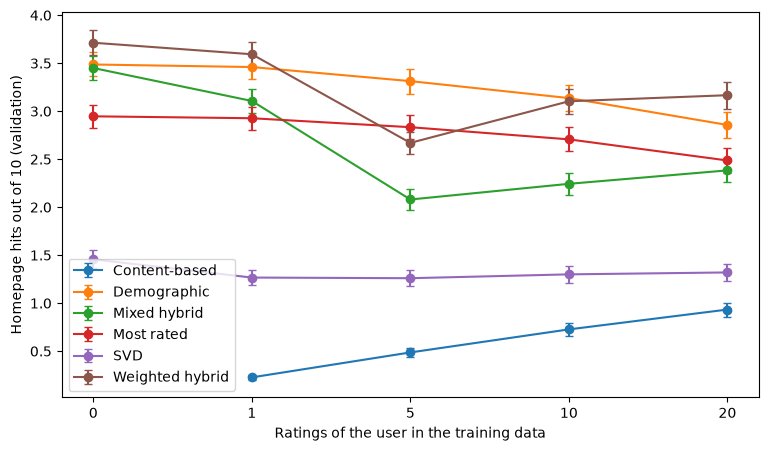

model,Content-based,Demographic,Mixed hybrid,Most rated,SVD,Weighted hybrid
ratings kept,,,,,,
0,NaN,0.125,0.129,0.122,0.093,0.133
1,0.027,0.126,0.126,0.121,0.080,0.132
5,0.049,0.129,0.107,0.122,0.084,0.114
10,0.067,0.131,0.116,0.125,0.086,0.129
20,0.073,0.134,0.120,0.126,0.090,0.142


In [85]:
hits_table = cold_start_df.pivot(index="ratings kept", columns="model", values="hits out of 10")
error_table = cold_start_df.pivot(index="ratings kept", columns="model", values="hits standard error")
x = range(len(hits_table))

plt.figure(figsize=(9, 5))
for name in hits_table.columns:
    plt.errorbar(x, hits_table[name], yerr=error_table[name], marker="o", capsize=3, label=name)
plt.xticks(x, hits_table.index)
plt.xlabel("Ratings of the user in the training data")
plt.ylabel("Homepage hits out of 10 (validation)")
plt.legend()
plt.show()

error_table.round(3)

**For a new user, demographic and the weighted hybrid are the best choices, and SVD is the worst.** With no ratings at all, the weighted hybrid finds 3.713 relevant anime per 10 and demographic 3.487, against 2.947 for most rated and 1.457 for SVD. Demographic beats most rated by 0.540 hits, about three combined standard errors, which confirms the role given to it in 2.6: the group a user gives at sign-up is worth asking for. SVD knows nothing about a new user and ranks the anime by their learned bias alone, which is a weak list. Content-based is not possible without a rated anime.

Content-based is the only model that clearly improves with more history, from 0.227 hits at 1 rating to 0.933 at 20. This explains the one irregular result in the table. The weighted hybrid drops from 3.593 hits at 1 rating to 2.670 at 5 and recovers to 3.103 at 10. With a single rating, content-based gives every anime the same score: its score is the user's mean plus how far the user's similar ratings lie above or below that mean, and with one rating there is no difference. So at 1 rating it adds nothing to the hybrid. From 2 ratings on it becomes active, but at 5 ratings it is still weak, while it carries half of the hybrid's weight, which was tuned on users with a full history. From 10 ratings on it is strong enough again. The mixed hybrid shows the same dip for the same reason. Demographic ignores the history and stays steady, so for users with around 5 ratings it is the better choice. The switching hybrid in 5.5 uses exactly this.

The hits fall from left to right for every model only because users who keep more ratings have fewer hidden ratings left to find (5.4). The standard errors are about 0.08 to 0.14, so differences of less than about 0.2 hits within one column are not reliable.

## 5.5 Switching hybrid

A switching hybrid gives each user the model that works best for the amount of history they have [1, pp. 211-212; 12, slide 21]. Users are put into buckets by their number of ratings: 0, 1 to 4, 5 to 9, 10 to 19, and 20 or more. For the first four buckets the cold-start experiment in 5.4 gives the hits of every model at the lower edge of the bucket. For 20 or more ratings the full-history comparison from 5.2 and 5.3 is used, since most users have far more than 20 ratings. In every bucket the model is chosen on validation with the one-standard-error rule from 3.1 and, as in 5.2, coverage as the tie-break. If the same model wins every bucket, the switching hybrid is simply that model. That would be a result too: switching would add complexity without a gain.

In [86]:
def choose_model(candidates_df):
    # One-standard-error rule from 3.1 with coverage as the tie-break, as in 5.2
    candidates_df = candidates_df.dropna(subset=["hits out of 10"])
    best_row = candidates_df.loc[candidates_df["hits out of 10"].idxmax()]
    close = candidates_df[candidates_df["hits out of 10"] >= best_row["hits out of 10"] - best_row["hits standard error"]]
    return close.loc[close["coverage %"].idxmax(), "model"]


# Buckets of 0, 1 to 4, 5 to 9 and 10 to 19 ratings: the cold-start experiment in 5.4
switch_rule = {n_kept: choose_model(cold_start_df[cold_start_df["ratings kept"] == n_kept]) for n_kept in [0, 1, 5, 10]}

# 20 or more ratings: the full-history comparison on the validation split from 5.2 and 5.3
full_history_df = pd.DataFrame([dict(hybrid_tuning[hybrid_tuning[name] == 1].iloc[0], model=name) for name in component_names]
                               + [dict(chosen, model="Weighted hybrid"), dict(mixed_validation, model="Mixed hybrid")])
switch_rule[20] = choose_model(full_history_df)

pd.Series(switch_rule, name="model").rename_axis("from this many ratings").to_frame()

,model
from this many ratings,
0,Weighted hybrid
1,Weighted hybrid
5,Demographic
10,Weighted hybrid
20,Weighted hybrid


In [87]:
class MySwitchingHybridAlgorithm(AlgoBase):
    def __init__(self, switch_rule):
        AlgoBase.__init__(self)
        self.switch_rule = switch_rule  # smallest number of ratings -> name of the model

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.models = make_components()
        self.models["Weighted hybrid"] = MyWeightedHybridAlgorithm(best_weights)
        self.models["Mixed hybrid"] = MyMixedHybridAlgorithm()
        for name in set(self.switch_rule.values()):  # only the models the rule uses
            self.models[name].fit(trainset)
        return self

    def model_for(self, u):
        n_ratings = len(self.trainset.ur[u]) if self.trainset.knows_user(u) else 0
        bucket = max(edge for edge in self.switch_rule if edge <= n_ratings)
        return self.models[self.switch_rule[bucket]]

    def estimate(self, u, i):
        # Every user gets the scores of one model only, so the scores of different models are never compared
        return self.model_for(u).estimate(u, i)


switching_RS = MySwitchingHybridAlgorithm(switch_rule)
results_part5_df.loc["Switching hybrid"] = pd.Series(evaluate_model(switching_RS))
results_part5_df.loc["Switching hybrid", ["RMSE", "MAE"]] = np.nan
results_part5_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.341,1.853,0.861,0.560,0.389,0.812,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,5.268,4.915,0.898,0.676,0.448,0.865,1.449,0.050,65.5,1.72,0.615,0.329
Demographic,5.128,4.737,0.898,0.675,0.447,0.865,1.634,0.054,69.6,3.84,0.791,0.316
SVD,1.222,0.912,0.943,0.816,0.527,0.927,0.673,0.034,41.0,16.78,0.927,0.255
CB tuned,1.365,1.025,0.918,0.725,0.473,0.893,0.494,0.027,32.2,54.00,0.988,0.304
Weighted hybrid,NaN,NaN,0.933,0.781,0.509,0.912,1.895,0.057,74.9,18.01,0.923,0.302
Mixed hybrid,NaN,NaN,0.937,0.798,0.516,0.919,1.564,0.053,67.7,9.77,0.944,0.293
Switching hybrid,NaN,NaN,0.933,0.781,0.509,0.912,1.892,0.057,74.9,18.01,0.923,0.302


**The switching hybrid uses the weighted hybrid for almost every user and gives the same result.** The rule from validation picks the weighted hybrid for 0, 1, 10 and 20 or more ratings, and demographic for 5 to 9 ratings, for the reason explained in 5.4. On the test set the switching hybrid finds 1.892 relevant anime per 10, against 1.895 for the weighted hybrid, with the same coverage, personalization and diversity. Every user in the test set has a history, and only a few have between 5 and 9 ratings, so the switch hardly changes anything here.

Most test users have far more than 20 ratings, so the averages above mostly show the model of the last bucket. The table below shows the homepage hits on test per history bucket. The switching hybrid uses the model of its rule in each bucket, so its hits are those of that model.

In [88]:
def hits_per_user(top_n, testset):
    relevant = defaultdict(set)
    for uid, iid, r in testset:
        if r >= relevant_score:
            relevant[uid].add(iid)
    return pd.Series({uid: len(set(items) & relevant[uid]) for uid, items in top_n.items()})


# Demographic and the weighted hybrid for comparison, plus every model the rule uses
all_models = make_components()
all_models["Weighted hybrid"] = MyWeightedHybridAlgorithm(best_weights)
all_models["Mixed hybrid"] = MyMixedHybridAlgorithm()
bucket_models = {name: all_models[name] for name in {"Demographic", "Weighted hybrid"} | set(switch_rule.values())}
user_hits_df = pd.DataFrame({name: hits_per_user(top_n_unseen(algo.fit(trainset), trainset, users, solve_ties=True), testset)
                             for name, algo in bucket_models.items()})
user_hits_df["ratings in training"] = [len(trainset.ur[trainset.to_inner_uid(uid)]) for uid in user_hits_df.index]
user_hits_df["bucket"] = [max(edge for edge in switch_rule if edge <= n) for n in user_hits_df["ratings in training"]]
user_hits_df["Switching hybrid"] = [user_hits_df.loc[uid, switch_rule[bucket]] for uid, bucket in user_hits_df["bucket"].items()]

by_bucket = user_hits_df.groupby("bucket")[["Demographic", "Weighted hybrid", "Switching hybrid"]].mean()
by_bucket["users"] = user_hits_df.groupby("bucket").size()
by_bucket.index = [f"{edge} or more ratings" for edge in by_bucket.index]
by_bucket.round(3)

,Demographic,Weighted hybrid,Switching hybrid,users
5 or more ratings,0.368,0.526,0.368,19
10 or more ratings,0.422,0.494,0.494,83
20 or more ratings,1.773,2.053,2.053,898


**The switch affects too few users to judge on the test set.** Each row is a bucket of the rule: the row "5 or more ratings" holds the users with 5 to 9 ratings, and "10 or more" those with 10 to 19. Only 19 of the 1,000 test users fall in the 5 to 9 bucket. There, demographic finds 0.368 hits against 0.526 for the weighted hybrid, the opposite of the validation result, but with 19 users the difference is far too small to be reliable. 898 users have 20 or more ratings, and for them the weighted hybrid finds 2.053 hits against 1.773 for demographic.

The switching hybrid therefore matters for new users rather than for the users in this test set. For a brand-new user the rule picks the weighted hybrid, which 5.4 found to be the best choice at 0 ratings, and 8.3 tests the final system on such users.

## 5.6 Conclusion of Part 5

**The weighted hybrid is the best homepage model, and the switching hybrid built on it serves every user.**

| Model | Strength | Weakness | Role |
|---|---|---|---|
| Weighted hybrid | Most hits (1.895), 74.9% of users, 18.0% of the catalog | Weights tuned on users with a full history | Main model |
| Mixed hybrid | Nothing to tune, slightly better ordering of known anime | Fewer hits (1.564), less coverage | Not used |
| Switching hybrid | Same result as the weighted hybrid, a model chosen for every history size | Its rule rests on a small part of the users | Final system for Part 8 |

The hybrid beats the best single model, demographic, by 0.261 hits, about 3.3 standard errors, and shows almost five times as much of the catalog. This answers the question of Part 3, why a personal model loses to popularity: on its own it does, but combined with popularity it adds relevant anime that popularity misses. The counterargument is the bias of the offline test toward popular anime (3.7). It may undervalue the personal components, but it is unlikely to make the hybrid look better than the popularity models, since those benefit from the bias at least as much.

The switching hybrid is kept as the final system because it covers every user by design. For almost everyone it is the weighted hybrid, and for a user with about 5 ratings it falls back to demographic, which 5.4 showed is more reliable while the content-based component is still weak. Part 8 tests it on new users and adds the recency boost and a bandit slot.

# Part 6. Context-aware

A context-aware recommender uses the circumstances of a recommendation, such as the time, the place or the device, besides the user and the item [20]. The only context in this data is time. `last_updated` records when a user last changed an anime on their list. There is no device, no location at the moment of watching and no usable hour in the user's time zone (see `02_eda`). Country is a user attribute rather than a context, and `02_eda` showed that users in different regions like almost the same anime.

The question of this part is therefore: **does it matter when a user visits the homepage, and can the time be used to show better anime?**

All models in this part use Surprise's default SVD rather than the tuned SVD from Part 3. The question is what the context adds to the same base model, and the check in 6.7 trains every model five more times. The context step itself works on top of any base model.

## 6.1 Context features from last_updated

In [89]:
seasons = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
           6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}

ratings_df["year"] = ratings_df["last_updated"].dt.year
ratings_df["season"] = ratings_df["last_updated"].dt.month.map(seasons)
ratings_df["weekday"] = ratings_df["last_updated"].dt.day_name()
ratings_df["weekend"] = ratings_df["last_updated"].dt.day_of_week >= 5

# Time of every rating, to look it up later for the train and test rows
rating_time = ratings_df.set_index(["user_id", "anime_id"])["last_updated"]
print("One time per user and anime:", rating_time.index.is_unique)
print("Data ends on:", ratings_df["last_updated"].max())
ratings_df[["year", "season", "weekday", "weekend"]].head()

One time per user and anime: True
Data ends on: 2018-05-22 01:51:53


,year,season,weekday,weekend
0,2007,autumn,Tuesday,False
1,2007,autumn,Tuesday,False
2,2007,autumn,Tuesday,False
3,2007,autumn,Tuesday,False
4,2007,autumn,Tuesday,False


Year, season and weekday are kept, plus a weekend flag. The hour is left out, as decided in `02_eda`.

`last_updated` is the last time the user edited the entry, not the moment the anime was watched. A user who changes an old score in 2017 moves that rating to 2017. The time context is therefore noisy, which has to be kept in mind when reading the results.

## 6.2 Which context variables matter?

The first test is whether the score changes with the context. Welch's t-test compares the mean score of each context group with the rest of the ratings without assuming equal variances. With almost a million ratings nearly any difference is significant, so the effect size, Cohen's d, is reported as well. A d below 0.2 is conventionally a small effect.

In [90]:
from scipy import stats


def cohens_d(x, y):
    return (x.mean() - y.mean()) / np.sqrt((x.var() + y.var()) / 2)


def compare(name, mask):
    x, y = ratings_df.loc[mask, "score"], ratings_df.loc[~mask, "score"]
    t, p = stats.ttest_ind(x, y, equal_var=False)
    return {"context": name, "mean in group": x.mean(), "mean rest": y.mean(), "t": t, "p-value": p, "Cohen's d": cohens_d(x, y)}


tests = [compare("weekend", ratings_df["weekend"])]
for s in ["winter", "spring", "summer", "autumn"]:
    tests.append(compare(s, ratings_df["season"] == s))
tests.append(compare("2017 or later", ratings_df["year"] >= 2017))

pd.DataFrame(tests).set_index("context").round(4)

,mean in group,mean rest,t,p-value,Cohen's d
context,,,,,
weekend,7.5808,7.5573,6.2716,0.0000,0.0137
winter,7.5267,7.5778,-12.8753,0.0000,-0.0298
spring,7.5889,7.5560,8.3626,0.0000,0.0192
summer,7.5858,7.5577,6.9792,0.0000,0.0164
autumn,7.5568,7.5670,-2.4893,0.0128,-0.0060
2017 or later,7.3793,7.5966,-43.0696,0.0000,-0.1249


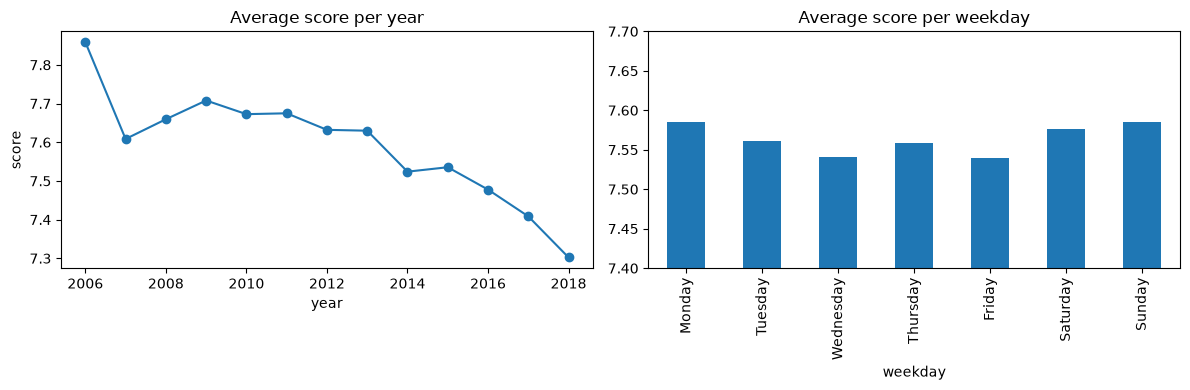

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratings_df.groupby("year")["score"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Average score per year")
axes[0].set_ylabel("score")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ratings_df.groupby("weekday")["score"].mean().reindex(order).plot(ax=axes[1], kind="bar")
axes[1].set_ylim(7.4, 7.7)
axes[1].set_title("Average score per weekday")
plt.tight_layout()
plt.show()

**The score barely depends on the weekday or the season, but it does depend on the year.** All tests are significant, mainly because of the number of ratings, so the effect sizes decide. Weekend against weekday gives d = 0.014 (7.58 against 7.56), and the seasons lie between −0.030 and 0.019. The weekday plot shows the same flat pattern. The year is different: ratings from 2017 or later average 7.38, against 7.60 before (d = −0.125). This is still a small effect by the usual threshold, but it is about four times the largest season effect and nine times the weekend effect, and it continues the downward trend found in `02_eda`.

For predicting the score, weekday and season are therefore not worth using. A counterargument is that a small effect can still matter when it applies to every rating, but a difference of a few hundredths of a point on a 10-point scale cannot change which anime come first on a homepage.

The score is not the whole story. The context can also change which anime people watch, even when their scores stay the same. The next cell measures two things per year: the share of ratings on anime that started airing at most one year earlier, and how many of the 50 most rated anime of a year were also in the top 50 of the year before.

In [92]:
aired_year = anime_df.set_index("anime_id")["aired_from_year"]
ratings_df["anime_age"] = ratings_df["year"] - ratings_df["anime_id"].map(aired_year)

new_share = ratings_df.groupby("year")["anime_age"].apply(lambda a: (a <= 1).mean() * 100)

top50 = {y: set(g["anime_id"].value_counts().head(50).index) for y, g in ratings_df.groupby("year")}
overlap_prev = {y: len(top50[y] & top50[y - 1]) for y in range(2009, 2019)}

season_top50 = {s: set(g["anime_id"].value_counts().head(50).index) for s, g in ratings_df.groupby("season")}

context_items_df = pd.DataFrame({"% ratings on anime from the last year": new_share,
                                 "top 50 shared with previous year": pd.Series(overlap_prev)}).loc[2009:2018]
print("Top 50 shared between seasons (all years together):",
      {f"{a}-{b}": len(season_top50[a] & season_top50[b]) for a, b in [("winter", "spring"), ("spring", "summer"), ("summer", "autumn"), ("autumn", "winter")]})
context_items_df.round(1)

Top 50 shared between seasons (all years together): {'winter-spring': 22, 'spring-summer': 24, 'summer-autumn': 20, 'autumn-winter': 22}


,% ratings on anime from the last year,top 50 shared with previous year
2009,27.9,35.0
2010,30.4,26.0
2011,38.1,21.0
2012,39.0,18.0
2013,42.2,18.0
2014,45.1,10.0
2015,46.4,7.0
2016,45.8,13.0
2017,45.3,9.0
2018,42.1,11.0


**Time changes what people watch much more than how they score it.** From 2014 to 2018, between 42% and 46% of each year's ratings are on anime that started airing at most one year earlier. The most rated anime also change quickly: in those years only 7 to 13 of the 50 most rated anime of a year were also in the top 50 of the year before, against 35 in 2009. Users mostly watch what is new at the time, and what is new changes every year.

The seasons also differ, since only 20 to 24 of the top 50 are shared between neighboring seasons. This is mostly the same effect, because new anime start airing every season, and the data mixes all years within each season, so the season adds little on top of the year. Aggarwal separates periodic context, such as the weekday or the season, from the trend over time [1, p. 288]. Here the trend is what matters: the useful context for the homepage is what is popular right now.

## 6.3 The context used for evaluation

The homepage is shown now. The data ends in May 2018, so "now" is defined as the last 12 months of the data, and the test ratings from that period form the context test set. The models are still trained on `trainset` from Part 1 (rule 1 in 1.6). Only the evaluation is restricted to the test ratings in the context.

In [93]:
data_end = ratings_df["last_updated"].max()
context_start = data_end - pd.Timedelta(days=365)


def add_time(df):
    df = df.copy()
    df["last_updated"] = rating_time.reindex(pd.MultiIndex.from_frame(df[["user_id", "anime_id"]])).values
    return df


test_time_df = add_time(pd.DataFrame(testset, columns=["user_id", "anime_id", "score"]))
train_time_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                      columns=["user_id", "anime_id", "score"]))

in_context = test_time_df["last_updated"] >= context_start
context_testset = list(test_time_df.loc[in_context, ["user_id", "anime_id", "score"]].itertuples(index=False, name=None))

# Homepage users: the 1,000 users from Part 1 that liked at least one anime in the context period
liked_in_context = {u for u, i, r in context_testset if r >= relevant_score}
context_users = [u for u in users if u in liked_in_context]

print("Context period:", context_start.date(), "to", data_end.date())
print("Test ratings in the context:", len(context_testset), "of", len(testset))
print("Users with test ratings in the context:", test_time_df.loc[in_context, "user_id"].nunique())
print("Homepage users (of the 1,000) with a liked anime in the context:", len(context_users))

Context period: 2017-05-22 to 2018-05-22
Test ratings in the context: 20570 of 195413
Users with test ratings in the context: 2001
Homepage users (of the 1,000) with a liked anime in the context: 337


Only about 1 in 10 test ratings falls in the last year (20,570 of 195,413). The homepage metric uses the users among the 1,000 from Part 1 who liked at least one anime in that period (337 users). Users without a liked test anime in the period would get 0 hits from every model, which would only dilute the differences.

## 6.4 Pre-filtering

Pre-filtering first removes the training ratings outside the context and then trains a normal model on the rest [1, pp. 289-290; 20, slide 14]. Here an SVD is trained only on recent ratings. A user or anime that is missing from the recent data falls back to the SVD trained on all ratings, so that long-time users who were not active recently still get recommendations. Two windows are tried, the last year and the last 3 years; using all years is the normal SVD. Aggarwal warns that the filtered data are sparser than the original, which can make the model overfit [1, pp. 289-290]. The results below test whether that happens here.

In [94]:
class MyPreFilterSVD(AlgoBase):
    def __init__(self, start):
        AlgoBase.__init__(self)
        self.start = start

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.global_svd = SVD(random_state=my_seed)
        self.global_svd.fit(trainset)

        # Keep only the training ratings from the context window
        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        recent_df = train_df[train_df["last_updated"] >= self.start]
        self.recent_trainset = Dataset.load_from_df(recent_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
        self.recent_svd = SVD(random_state=my_seed)
        self.recent_svd.fit(self.recent_trainset)
        self.recent_users = set(recent_df["user_id"])
        self.recent_items = set(recent_df["anime_id"])
        return self

    def estimate(self, u, i):
        if not (self.trainset.knows_user(u) and self.trainset.knows_item(i)):
            return self.global_svd.estimate(u, i)
        raw_u, raw_i = self.trainset.to_raw_uid(u), self.trainset.to_raw_iid(i)
        if raw_u in self.recent_users and raw_i in self.recent_items:
            return self.recent_svd.predict(raw_u, raw_i).est
        # Fall back to the model trained on all the data
        return self.global_svd.estimate(u, i)

## 6.5 Post-filtering

Post-filtering works the other way around: a normal model is trained on all ratings, and the context changes the ranking afterwards [1, pp. 289-290; 20]. 6.2 showed that time changes which anime are watched more than how they are scored, so the post-filter moves up the anime that many users rated in the context period:

score with context = SVD score + weight × context popularity

Context popularity is log(1 + number of ratings of the anime in the last year), scaled to the range 0 to 1, and a weight of 0 gives the normal SVD. Aggarwal multiplies the predicted rating by a contextual relevance weight instead [1, p. 290]. An additive boost is used here, so that the weight directly sets how far the context can move an anime up the list.

In [95]:
class MyPostFilterSVD(AlgoBase):
    def __init__(self, start, weight):
        AlgoBase.__init__(self)
        self.start = start
        self.weight = weight

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.svd = SVD(random_state=my_seed)
        self.svd.fit(trainset)

        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        counts = train_df[train_df["last_updated"] >= self.start].groupby("anime_id").size()
        popularity = np.log1p(counts) / np.log1p(counts.max())
        self.context_popularity = {trainset.to_inner_iid(a): p for a, p in popularity.items()}
        return self

    def estimate(self, u, i):
        score = self.svd.estimate(u, i) + self.weight * self.context_popularity.get(i, 0)
        # The boost can push a score above 10, and Surprise clips predictions to the rating scale, which would
        # turn the top of the list into ties. Moving the range 1 to 10 + weight back onto 1 to 10 keeps the order
        return 1 + (score - 1) * 9 / (9 + self.weight)

### A baseline for the context: most rated in the last year

The post-filter mixes two things: the user's taste from the SVD and the recent popularity of each anime. To see whether the taste adds anything, the post-filter is also compared with recent popularity alone. This baseline ranks the anime by their number of ratings in the context period, like most rated from Part 2 but counted only over the last year. If the post-filter does not beat it, the gain comes from recency and not from personalization.

In [96]:
class MyRecentMostRatedAlgorithm(AlgoBase):
    def __init__(self, start):
        AlgoBase.__init__(self)
        self.start = start

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        counts = train_df[train_df["last_updated"] >= self.start].groupby("anime_id").size()
        self.recent_count = {trainset.to_inner_iid(a): n for a, n in counts.items()}
        self.max_count = counts.max()
        return self

    def estimate(self, u, i):
        # Number of ratings in the context period, moved onto the 1 to 10 scale as in MyMostRatedAlgorithm
        return 1 + 9 * self.recent_count.get(i, 0) / self.max_count

### Choosing the weight

The weight is chosen on the validation split from 1.3, never on the test set. Very small, middle and very large values are tried and judged by the homepage hits on the validation ratings from the context period, with the one-standard-error rule from 3.1.

In [97]:
# Same validation split as in Part 3

val_time_df = add_time(pd.DataFrame(tune_valset, columns=["user_id", "anime_id", "score"]))
context_valset = list(val_time_df.loc[val_time_df["last_updated"] >= context_start, ["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
val_liked = {u for u, i, r in context_valset if r >= relevant_score}
val_context_users = [u for u in eval_users(tune_trainset, n=1000) if u in val_liked]
print("Validation users with a liked anime in the context:", len(val_context_users))

tuning_rows = []
for weight in [0, 0.5, 1, 3, 10]:
    algo = MyPostFilterSVD(context_start, weight)
    algo.fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_context_users, solve_ties=True)
    row = {"weight": weight}
    row.update(homepage_hits(top_n, context_valset))
    row["RMSE"] = accuracy_metrics(algo.test(context_valset))["RMSE"]
    tuning_rows.append(row)

weight_tuning_df = pd.DataFrame(tuning_rows).set_index("weight")
# One-standard-error rule from 3.1: ties within one standard error go to the lower validation RMSE
best_post_weight = choose_setting(weight_tuning_df.reset_index())["weight"]
print("Best weight:", best_post_weight)
weight_tuning_df.round(3)

Validation users with a liked anime in the context: 274
Best weight: 10.0


,hits out of 10,hits standard error,users with at least 1 hit %,RMSE
weight,,,,
0.0,0.124,0.023,10.584,1.251
0.5,0.157,0.025,13.504,1.247
1.0,0.208,0.029,17.883,1.253
3.0,0.350,0.034,30.657,1.338
10.0,0.478,0.044,37.226,1.694


**The more weight the context gets, the more homepage hits on validation, up to the largest weight tried.** The plain SVD (weight 0) finds 0.124 relevant anime per 10 among the validation ratings from the last year, a weight of 1 finds 0.208, 3 finds 0.350 and 10 finds 0.478. No other weight is within one standard error of 10, so the rule picks 10, the end of the grid. RMSE gets worse as the weight grows (from 1.251 to 1.694), since the boost is added to the predicted score on purpose. The post-filter is a ranking model, not a rating predictor, so the homepage hits decide.

At a weight of 10 the boost is as large as the whole rating scale, so recent popularity decides most of the ranking and the SVD mainly orders anime of similar recent popularity. The validation hits keep rising because the users in the context period mostly rated recent anime (6.2). Whether this is still personalization or mostly recency is what the baseline below tests.

## 6.6 Results on the context test set

The same metrics as in the other parts (rules 3 and 4 in 1.6), but on the test ratings from the last year. Random (the current homepage), most rated (the baseline from Part 2) and most rated in the last year are included for comparison.

In [98]:
part6_models = {
    "Random": MyRandomAlgorithm(),
    "Most rated": MyMostRatedAlgorithm(),
    "Most rated, last year": MyRecentMostRatedAlgorithm(context_start),
    "SVD (no context)": SVD(random_state=my_seed),
    "Pre-filter SVD, 1 year": MyPreFilterSVD(context_start),
    "Pre-filter SVD, 3 years": MyPreFilterSVD(data_end - pd.Timedelta(days=3 * 365)),
    f"Post-filter SVD, weight {best_post_weight}": MyPostFilterSVD(context_start, best_post_weight),
}

part6_results = defaultdict(dict)
part6_top_n = {}
for name, algo in part6_models.items():
    algo.fit(trainset)
    predictions = algo.test(context_testset)
    part6_results[name].update(accuracy_metrics(predictions))
    part6_results[name].update(test_ranking_metrics(predictions))
    part6_results[name]["NDCG@10 (20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    top_n = top_n_unseen(algo, trainset, context_users, solve_ties=(name != "Random"))
    part6_top_n[name] = top_n
    part6_results[name].update(homepage_hits(top_n, context_testset))

results_part6_df = pd.DataFrame(part6_results).T
results_part6_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,users,NDCG@10 (20+ test items),hits out of 10,hits standard error,users with at least 1 hit %
Random,2.402,1.891,0.924,0.700,0.671,2001.0,0.810,0.003,0.003,0.297
Most rated,5.412,5.075,0.944,0.767,0.732,2001.0,0.857,0.240,0.035,16.617
"Most rated, last year",5.608,5.255,0.943,0.767,0.733,2001.0,0.851,0.730,0.055,48.368
SVD (no context),1.229,0.910,0.969,0.857,0.813,2001.0,0.923,0.234,0.031,18.398
"Pre-filter SVD, 1 year",1.266,0.947,0.965,0.846,0.804,2001.0,0.911,0.231,0.029,18.398
"Pre-filter SVD, 3 years",1.235,0.916,0.968,0.858,0.814,2001.0,0.917,0.231,0.031,18.398
"Post-filter SVD, weight 10.0",1.649,1.308,0.959,0.820,0.780,2001.0,0.897,0.795,0.056,51.335


**For users who visit now, the post-filter finds over three times as many relevant anime as the SVD without context, but most of that gain is recency.** It finds 0.795 relevant anime per 10 and 51.3% of the context users get at least one, against 0.234 and 18.4% for the SVD without context. Random, today's homepage, finds 0.003.

The baseline answers what the gain is made of. Most rated in the last year, which ignores the user completely, finds 0.730 hits and reaches 48.4% of the users. The post-filter beats it by only 0.065 hits, less than one combined standard error (0.078). On this test set the personal part of the post-filter adds little that recent popularity alone does not. All-time most rated finds 0.240, so what matters is popularity now, not popularity in general, which confirms 6.2: users mostly watch what is new.

**Pre-filtering does not help.** Training the SVD only on the last year gives 0.231 hits and a worse RMSE (1.266 against 1.229), and 3 years is almost the same as the normal SVD. This is the sparsity problem Aggarwal warns about [1, pp. 289-290]: the last year holds only about a tenth of the training ratings, so the model learns the users' tastes less well. The post-filter keeps all the data for the taste and uses the context only to reorder the list.

The ranking metrics on each user's test anime (NDCG, MAP, MAR) barely differ between the SVD models, since they only reorder anime the user already rated (2.4). The RMSE of the post-filter (1.649) is worse because the boost changes the scores on purpose.

### Coverage, personalization and diversity

As rule 5 in 1.6 requires, these use `full_trainset` and the 1,000 users from Part 1. They are computed for the SVD without context, the post-filter and recent popularity alone, since the question is what the context does to the lists. The median start year of the shown anime measures how recent the lists are.

In [99]:
part6_beyond = {}
for name in ["SVD (no context)", f"Post-filter SVD, weight {best_post_weight}", "Most rated, last year"]:
    algo = part6_models[name]
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=True)
    part6_beyond[name] = beyond_accuracy_metrics(top_n, full_trainset)
    # how new are the anime we show? (year the anime started airing)
    shown = [i for items in top_n.values() for i in items]
    part6_beyond[name]["median aired year of shown anime"] = aired_year.reindex(shown).median()

pd.DataFrame(part6_beyond).T.round(3)

,coverage %,personalization,intra-list similarity,median aired year of shown anime
SVD (no context),14.00,0.911,0.268,2012.0
"Post-filter SVD, weight 10.0",2.47,0.481,0.289,2017.0
"Most rated, last year",1.09,0.240,0.306,2017.0


**The recency gain costs most of the catalog and most of the personalization.** With the post-filter the median start year of the shown anime moves from 2012 to 2017, but coverage falls from 14.0% to 2.5% and personalization from 0.911 to 0.481: many users now get largely the same recent anime. Recent popularity alone goes further in the same direction (1.1% coverage, personalization 0.240). With a weight of 10 the post-filtered homepage is much closer to a chart of what is popular now than to the personal SVD list.

For the business this is a real trade-off. Users who visit now find more relevant anime, but the homepage promotes a small part of the catalog, which works against the goal set in 2.6 of showing more of it. The weight is the lever between the two, and 10 is the setting the offline test prefers, not necessarily the right one for the platform.

## 6.7 Cross-validation through time

The random split lets the models learn from the future (see 1.3), which matters for a part about time. Cross-validation through time (CVTT) uses the folds from Part 1: every model is trained on the past and tested on the next period [5]. In each fold, "now" is the last 12 months of the training fold. For speed, the homepage metric uses 300 random users per fold. RMSE is not reported for recent popularity, since its scores are counts, not ratings.

In [100]:
cvtt_rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    fold_trainset = Dataset.load_from_df(train_fold[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    fold_testset = list(test_fold[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    fold_now = train_fold["last_updated"].max() - pd.Timedelta(days=365)

    # Homepage users: known in training and liked something in the test fold
    liked = set(test_fold.loc[test_fold["score"] >= relevant_score, "user_id"]) & set(train_fold["user_id"])
    rng = np.random.default_rng(my_seed)
    fold_users = list(rng.choice(sorted(liked), size=min(300, len(liked)), replace=False))

    for name, algo in {"SVD (no context)": SVD(random_state=my_seed),
                       "Pre-filter SVD, 1 year": MyPreFilterSVD(fold_now),
                       "Most rated, last year": MyRecentMostRatedAlgorithm(fold_now),
                       f"Post-filter SVD, weight {best_post_weight}": MyPostFilterSVD(fold_now, best_post_weight)}.items():
        algo.fit(fold_trainset)
        predictions = algo.test(fold_testset)
        # The scores of recent popularity are counts, not ratings, so it has no RMSE
        row = {"fold": fold, "model": name,
               "RMSE": np.nan if name == "Most rated, last year" else accuracy_metrics(predictions)["RMSE"]}
        row.update(homepage_hits(top_n_unseen(algo, fold_trainset, fold_users, solve_ties=True), fold_testset))
        cvtt_rows.append(row)

cvtt_df = pd.DataFrame(cvtt_rows)
cvtt_df.pivot(index="fold", columns="model", values="hits out of 10").round(3)

model,"Most rated, last year","Post-filter SVD, weight 10.0","Pre-filter SVD, 1 year",SVD (no context)
fold,,,,
1,1.093,1.217,0.867,0.817
2,1.100,1.360,0.730,0.760
3,0.997,1.290,0.693,0.687
4,0.870,1.077,0.567,0.563
5,1.053,1.660,0.917,0.963


In [101]:
cvtt_df.pivot(index="fold", columns="model", values="RMSE").round(3)

model,"Most rated, last year","Post-filter SVD, weight 10.0","Pre-filter SVD, 1 year",SVD (no context)
fold,,,,
1,NaN,2.534,1.541,1.541
2,NaN,2.526,1.497,1.494
3,NaN,2.554,1.526,1.518
4,NaN,2.551,1.484,1.475
5,NaN,2.512,1.498,1.494


**Cross-validation through time confirms the gain and shows that it is more than recency.** In every one of the 5 folds the post-filter finds the most homepage hits: between 1.077 and 1.660 per 10, against 0.870 to 1.100 for most rated in the last year and 0.563 to 0.963 for the SVD without context. On the random split the post-filter and recent popularity were within noise; here the post-filter wins in all 5 folds, by 0.12 to 0.61 hits. Each fold is a separate test period, so a gain that appears every time is unlikely to be chance, and the personal part of the post-filter does seem to add something on top of recency. The pre-filter is again about the same as the normal SVD.

The hits are higher than on the random split because here the test fold holds all future ratings of a user instead of 20% of them. RMSE is again worse for the post-filter (about 2.5 against 1.5) for the reason given in 6.6.

## 6.8 Example: one user's homepage

The top 10 of one context user with the normal SVD and with the post-filter. A ✓ means the user rated the anime 8 or more in the test set.

In [102]:
liked_test = defaultdict(set)
for u, i, r in context_testset:
    if r >= relevant_score:
        liked_test[u].add(i)

post_name = f"Post-filter SVD, weight {best_post_weight}"
# Pick the user where the post-filter gains the most hits
gain = {u: len(set(part6_top_n[post_name][u]) & liked_test[u]) - len(set(part6_top_n["SVD (no context)"][u]) & liked_test[u]) for u in context_users}
context_example_user = max(gain, key=gain.get)

def show(items):
    return [titles[i] + (" ✓" if i in liked_test[context_example_user] else "") for i in items]

pd.DataFrame({"SVD (no context)": show(part6_top_n["SVD (no context)"][context_example_user]),
              "Post-filter": show(part6_top_n[post_name][context_example_user])}, index=range(1, 11))

,SVD (no context),Post-filter
1,Shinsekai yori,Shingeki no Kyojin Season 2 ✓
2,Shouwa Genroku Rakugo Shinjuu: Sukeroku Futata...,Tsuki ga Kirei ✓
3,Steins;Gate,Steins;Gate
4,Steins;Gate 0,No Game No Life: Zero ✓
5,Ginga Eiyuu Densetsu: Arata Naru Tatakai no Ov...,Sora yori mo Tooi Basho ✓
6,Toradora! ✓,Dragon Ball Super
7,Uchuu Senkan Yamato 2199,Yuru Camp△
8,Kyousou Giga (TV),Overlord II ✓
9,Majo no Takkyuubin,Re:Zero kara Hajimeru Isekai Seikatsu ✓
10,Kill la Kill Specials,Houseki no Kuni (TV)


**The post-filter turns a list of older classics into a list of current anime.** Without context, this user gets mostly older anime, such as Majo no Takkyuubin, Shinsekai yori and Uchuu Senkan Yamato 2199, and one of the ten (Toradora!) is a hit. With the post-filter, the list is mostly anime from 2017 and 2018, such as Shingeki no Kyojin Season 2, Tsuki ga Kirei, Sora yori mo Tooi Basho and Overlord II, and six of the ten are hits. Steins;Gate stays in both lists, so the user's taste is still present.

This user was chosen as the one where the post-filter gains the most, so it is a best case and not a typical user. It shows clearly what the context does, while the averages above show how large the effect is in general.

## 6.9 Conclusion of Part 6

**Time is the one context in this data that matters, and it matters through what users watch, not through how they score.**

| Method | Strength | Weakness | Role |
|---|---|---|---|
| Weekday and season | Easy to use | Effects on the score are negligible (d below 0.03) | Not used |
| Pre-filtering | Simple, uses only recent behavior | Too little data, no gain | Not used |
| Post-filtering | Most hits for users who visit now, wins in all 5 CVTT folds | Coverage 2.5%, personalization 0.481 | Recency boost on the final system in Part 8 |
| Most rated in the last year | Almost as many hits with no personalization | The same list for everyone | Baseline |

For users who visit now, the post-filter finds 0.795 relevant anime per 10 against 0.234 for the same SVD without context, and against 0.003 for today's random homepage. Most of this gain is recency: recent popularity alone gets 0.730 on the random split. Cross-validation through time shows that the personal part still adds something, since the post-filter beats recent popularity in every fold. The method needs no new data, only the dates the platform already stores.

There are three limits. `last_updated` is the last edit of an entry, not the moment of watching. The context test set holds only about 1 in 10 test ratings. And the chosen weight of 10 sits at the end of the grid, where recency decides most of the ranking and the homepage shows only 2.5% of the catalog. The offline test rewards recency without limit, because the users of the last year mostly rated recent anime, so the right weight for the platform has to come from an online test. The boost is applied on top of the final system in Part 8.

# Part 7. Bandits

Every model so far is trained once on past ratings and then only exploits what it learned. Anime that few users have rated rarely reach the homepage, so they never collect the feedback that could prove them good. This is the explore-exploit trade-off. A multi-armed bandit treats each anime as an arm and learns while it recommends, giving uncertain anime some exposure [15, 16].

This part uses Thompson sampling, as in Session 22. Each anime gets a Beta distribution of its probability of being liked. To fill the homepage, the bandit draws one value from each distribution and shows the 10 highest draws. A well-known anime has a narrow distribution, so its draws are stable. An anime with little feedback has a wide distribution, so it sometimes draws a high value and gets explored.

## 7.1 A Beta distribution per anime

The reward is whether the user liked the anime, a score of 8 or more, which is the relevance used in every part. The successes (alpha) of an anime are its ratings of 8 or more in the training data and the failures (beta) are its other ratings. Both start with a prior of 1, because the Beta distribution needs values above 0 and every anime should start from the same belief [16]. Adult anime are left out, as in rule 8.

The implicit label from 1.2 would be the other natural reward: 1 if the user completed or is watching the anime. It has more data, since it also covers interactions without a score, but it rewards attention rather than enjoyment, as a user can finish an anime they did not like. Every other part judges the homepage by liked anime, so the bandit uses the same reward, which keeps its results comparable with the other models.

In [103]:
import seaborn as sns

In [104]:
train_ratings_df = pd.DataFrame([(trainset.to_raw_iid(i), r) for (_, i, r) in trainset.all_ratings()], columns=["anime_id", "score"])
train_ratings_df["liked"] = (train_ratings_df["score"] >= relevant_score).astype(int)

beta_df = train_ratings_df.pivot_table(index="anime_id", columns="liked", aggfunc="size").fillna(0).astype(int)
beta_df = beta_df[[1, 0]]  # successes first, then failures, as the Beta distribution expects
beta_df = beta_df[~beta_df.index.isin(adult_anime)]
beta_df += 1
beta_df["num_ratings"] = beta_df[1] + beta_df[0] - 2
beta_df.insert(0, "title", titles.reindex(beta_df.index).values)
beta_df.sort_values("num_ratings", ascending=False).head()

liked,title,1,0,num_ratings
anime_id,,,,
1535,Death Note,2268,440,2706
1575,Code Geass: Hangyaku no Lelouch,1809,317,2124
11757,Sword Art Online,1354,749,2101
20,Naruto,1114,967,2079
16498,Shingeki no Kyojin,1650,372,2020


**The famous anime have narrow distributions and differ clearly in how often they are liked.** Death Note was rated by 2,706 users in the training data and liked by 2,267 of them (84%), Sword Art Online was rated by 2,101 users and liked by 64% and Naruto by 54% of its 2,079 raters (the columns 1 and 0 include the prior of 1). With thousands of ratings their Beta distributions are very narrow, so their draws hardly change from one homepage to the next: for them the bandit exploits what it knows. An anime with only a few ratings has a wide distribution and its draws vary from low to high, which is where the exploration comes from.

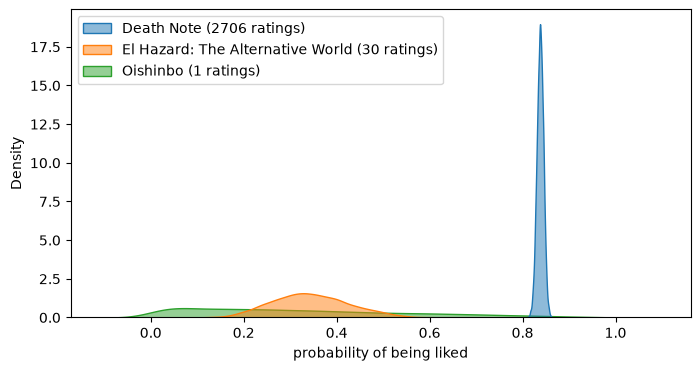

In [105]:
def plot_beta(items):
    dict_data = {}
    for name, (alpha, beta) in items.items():
        dict_data[name] = np.random.beta(alpha, beta, size=10000)
    plt.subplots(figsize=(8, 4))
    sns.kdeplot(data=pd.DataFrame(dict_data), alpha=.5, fill=True)
    plt.xlabel("probability of being liked")
    plt.show()


# A famous anime, an anime with a few dozen ratings and one with a single rating
examples = [beta_df["num_ratings"].idxmax(),
            beta_df[beta_df["num_ratings"] == 30].index[0],
            beta_df[beta_df["num_ratings"] == 1].index[0]]
plot_beta({f"{beta_df.loc[a, 'title']} ({beta_df.loc[a, 'num_ratings']} ratings)": (beta_df.loc[a, 1], beta_df.loc[a, 0])
           for a in examples})

## 7.2 Homepage slots: famous anime against new anime

The S22 notebook shows that the prior decides how much the bandit explores. Here the 20 anime with the most ratings compete with 50 anime that have at most 3 ratings. The bandit draws from all 70 distributions 10,000 times and each time puts the 10 highest draws on the homepage. The table shows how many of the 10 slots go to famous and to new anime on average. Extra failures in the prior make the bandit trust new anime less: with 2 extra failures, a new anime starts as if it had been shown twice without being liked. S22 adds 20, but there a success is a purchase, which is rare. Here 56% of the ratings are 8 or more, so a much smaller prior already has a strong effect.

In [106]:
def compute_probability(beta_df, n_sample=10_000, n=10):
    # Share of the draws in which each anime is among the n highest, i.e. shown on the homepage
    alphas = beta_df[1].to_numpy()
    betas = beta_df[0].to_numpy()
    shown = Counter()
    for _ in range(n_sample):
        rewards = np.random.beta(alphas, betas)
        for position in np.argpartition(-rewards, n - 1)[:n]:
            shown[beta_df.index[position]] += 1
    return pd.Series(shown).reindex(beta_df.index).fillna(0) / n_sample * 100


famous = beta_df.sort_values("num_ratings", ascending=False).head(20)
new = beta_df[beta_df["num_ratings"] <= 3].sample(50, random_state=my_seed)
competition_df = pd.concat([famous, new])

rows = {}
for extra_failures in [0, 1, 2, 5, 20]:
    prior_df = competition_df.copy()
    prior_df[0] += extra_failures
    probability = compute_probability(prior_df)
    # Probabilities are per anime, so their sum over a group is the expected number of the 10 slots, times 10
    rows[extra_failures] = {"slots for famous anime": probability[famous.index].sum() / 100,
                            "slots for new anime": probability[new.index].sum() / 100}

selection_df = pd.DataFrame(rows).T
selection_df.index.name = "extra failures in the prior"
selection_df.round(2)

,slots for famous anime,slots for new anime
extra failures in the prior,,
0,6.13,3.87
1,8.62,1.38
2,9.53,0.47
5,9.99,0.01
20,10.00,0.00


**The prior directly sets how much of the homepage goes to exploration.** Without extra failures, anime with at most 3 ratings take 3.87 of the 10 slots on average, although the famous anime have thousands of ratings: a new anime with one or two liked ratings draws a high value often. One extra failure lowers this to 1.38 slots, 2 to 0.47 and 5 to 0.01, and 20 shuts new anime out completely. Choosing the prior is therefore also a business decision: how many homepage slots the platform is willing to risk on anime it knows little about [16].

## 7.3 Bandit homepage with the Part 1 metrics

The bandit is written as a Surprise algorithm, so that it is evaluated like every other model. `estimate()` returns a new draw from the anime's Beta distribution, so each user sees a different homepage, and the same user would see a different one on the next visit. Anime without ratings in the training data get the prior.

The prior is chosen on the validation split from 1.3, before the test set is used. Every prior from 7.2 except 20, which never shows a new anime, is run for the 300 validation users. The choice follows the one-standard-error rule from 3.1, and as in 5.2 the tie-break is coverage: among the priors that give the same hits within noise, the one that shows more of the catalog explores more, which is the purpose of a bandit.

The rule has a known limit. An offline test can only reward anime that a user already watched and rated, so it can never reward the bandit for showing an anime the user did not know yet, which is exactly what exploration is for. Offline evaluation is biased toward what users already found [6, p. 97]. The validation hits are therefore expected to rise as the prior explores less, and the rule will lean toward the prior that explores least. The chosen prior is best read as the least exploration the historical data can justify, not as the right amount. The right amount can only be measured online, with real users, and Part 8 limits the risk in the meantime by giving the bandit only part of the homepage.

In [107]:
class MyThompsonSamplingAlgorithm(AlgoBase):
    def __init__(self, extra_failures=0):
        AlgoBase.__init__(self)
        self.extra_failures = extra_failures

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.successes, self.failures = defaultdict(int), defaultdict(int)
        for _, i, r in trainset.all_ratings():
            if r >= relevant_score:
                self.successes[i] += 1
            else:
                self.failures[i] += 1
        return self

    def estimate(self, u, i):
        # Prior of 1 success and 1 + extra_failures failures, plus the feedback of the anime
        draw = np.random.beta(1 + self.successes[i], 1 + self.extra_failures + self.failures[i])
        # Surprise clips predictions to the 1 to 10 scale, so the draw is moved onto it. The order stays the same
        return 1 + 9 * draw

In [108]:
bandit_rows = []
for extra_failures in [0, 1, 2, 5]:
    # The draws are random, so the seed is set again for every prior to make the results reproducible
    np.random.seed(my_seed)
    algo = MyThompsonSamplingAlgorithm(extra_failures=extra_failures).fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_users)
    row = {"extra failures": extra_failures}
    row.update(homepage_hits(top_n, tune_valset))
    row["coverage %"] = coverage(top_n, tune_trainset)
    bandit_rows.append(row)
bandit_tuning_df = pd.DataFrame(bandit_rows)

# One-standard-error rule from 3.1, with coverage as the tie-break as in 5.2
best_row = bandit_tuning_df.loc[bandit_tuning_df["hits out of 10"].idxmax()]
close = bandit_tuning_df[bandit_tuning_df["hits out of 10"] >= best_row["hits out of 10"] - best_row["hits standard error"]]
chosen_failures = int(close.loc[close["coverage %"].idxmax(), "extra failures"])
print("Extra failures in the prior:", chosen_failures)
bandit_tuning_df.round(3)

Extra failures in the prior: 5


,extra failures,hits out of 10,hits standard error,users with at least 1 hit %,coverage %
0,0,0.010,0.006,1.000,6.054
1,1,0.107,0.019,10.000,4.736
2,2,0.157,0.025,13.000,2.404
3,5,0.190,0.028,15.333,0.944


**As expected, the offline hits rise with every step toward less exploration, and the rule picks the end of the grid.** On validation, the bandit finds 0.010 relevant anime per 10 with no extra failures, 0.107 with 1, 0.157 with 2 and 0.190 with 5. No other prior is within one standard error of 5, so the rule picks 5, the prior that explores least. Coverage moves the other way, from 6.1% to 0.9%: the less the bandit explores, the fewer different anime it shows. This is the bias described in 7.3, now in numbers.

In [109]:
# Only the prior chosen on the validation split is evaluated on the test set
bandit_models = {f"Thompson sampling, {chosen_failures} extra failures": MyThompsonSamplingAlgorithm(extra_failures=chosen_failures)}

# The draws are random, so the seed is set again to make the results reproducible
np.random.seed(my_seed)
results_bandit = {}
for name, algo in bandit_models.items():
    results_bandit[name] = evaluate_model(algo)
    results_bandit[name].pop("RMSE")
    results_bandit[name].pop("MAE")

results_part7_df = pd.concat([results_part5_df.loc[["Random", "Most rated"]], pd.DataFrame(results_bandit).T])
results_part7_df.drop(columns=["RMSE", "MAE"]).round(3)

,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,0.861,0.560,0.389,0.812,0.042,0.007,4.1,83.13,0.998,0.192
Most rated,0.898,0.676,0.448,0.865,1.449,0.050,65.5,1.72,0.615,0.329
"Thompson sampling, 5 extra failures",0.931,0.783,0.508,0.910,0.460,0.027,30.3,1.38,0.550,0.278


RMSE and MAE are left out for the bandit. Its scores are random draws of the probability of being liked, not predicted ratings, so a rating error means nothing for it. The ranking metrics only use the order of the scores, so they still apply.

**As a full homepage, the bandit finds far fewer relevant anime than the popularity models.** With 5 extra failures it finds 0.460 relevant anime per 10 on the test set and reaches 30.3% of users, against 1.449 and 65.5% for most rated and 0.042 for random. Its coverage (1.4%) and personalization (0.550) are close to those of most rated. With a strong prior it ranks the anime mainly by their share of liked ratings among many ratings, a quality ranking with some random variation, and Part 2 showed that ranking by quality finds fewer relevant anime than ranking by popularity.

The offline test cannot measure what the bandit is for: learning from feedback that comes in after the training data was collected (7.4) [6, p. 97]. As the whole homepage it would cost too many hits, so Part 8 gives it a single slot.

## 7.4 Learning over time

In production the Beta distributions are updated with every new rating, so the bandit adapts as new anime come out [16]. This is simulated with `last_updated`. Every month from January 2017, the distributions are rebuilt from the ratings given until then, and the probability that Made in Abyss is among the 10 anime shown is computed against the same 20 famous anime, with the prior chosen in 7.3. Made in Abyss started airing in July 2017 and quickly became one of the best rated anime of that year.

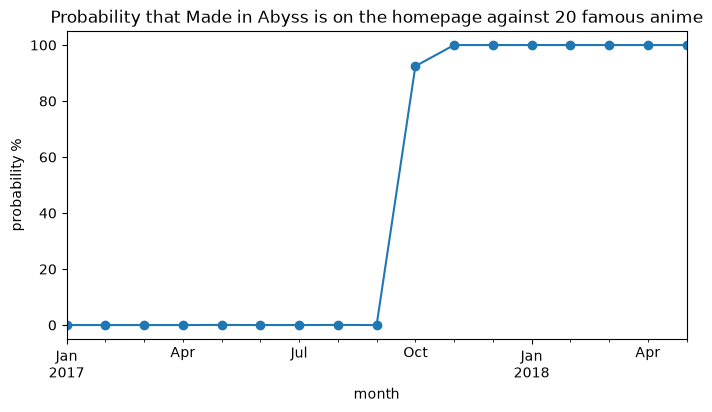

month,2017-01-01,2017-02-01,2017-03-01,2017-04-01,2017-05-01,2017-06-01,2017-07-01,2017-08-01,2017-09-01,2017-10-01,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01
probability %,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,92.4,100.0,100.0,100.0,100.0,100.0,100.0,100.0
ratings so far,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,11.0,133.0,326.0,386.0,428.0,481.0,511.0,549.0,571.0


In [110]:
made_in_abyss = 34599
extra_failures = chosen_failures  # the prior chosen on the validation split in 7.3
dates = pd.date_range("2017-01-01", "2018-05-01", freq="MS")

probability_over_time = []
for date in dates:
    ratings_until_date = ratings_df[(ratings_df["last_updated"] < date) & ~ratings_df["anime_id"].isin(adult_anime)]
    liked = (ratings_until_date["score"] >= relevant_score).astype(int)
    beta_until_date = ratings_until_date.assign(liked=liked).pivot_table(index="anime_id", columns="liked", aggfunc="size").fillna(0)
    beta_until_date = beta_until_date.reindex(list(famous.index) + [made_in_abyss], fill_value=0)[[1, 0]] + 1
    beta_until_date[0] += extra_failures
    probability = compute_probability(beta_until_date, n_sample=2_000)
    probability_over_time.append({"month": date, "probability %": probability[made_in_abyss],
                                  "ratings so far": int(beta_until_date.loc[made_in_abyss, [1, 0]].sum() - 2 - extra_failures)})

over_time_df = pd.DataFrame(probability_over_time).set_index("month")
over_time_df["probability %"].plot(marker="o", figsize=(8, 4), title="Probability that Made in Abyss is on the homepage against 20 famous anime")
plt.ylabel("probability %")
plt.show()
over_time_df.round(1).T

**Once Made in Abyss collects feedback, the bandit puts it on the homepage within a few months.** Until July 2017 it has no ratings, and with the prior of 5 extra failures its probability of being shown is 0. In August it has 5 ratings and in September 11, still not enough. In October, with 133 ratings, it is among the 10 anime shown in 92.4% of the draws, and from November, with 326 ratings, in all of them, against the 20 most famous anime of the platform. Made in Abyss is one of the best rated anime of 2017 in this data, with a mean of 8.85 in the training data, the third highest of the 154 anime from 2017 with at least 50 ratings. This is the behavior a platform wants: a new anime that users like reaches the homepage as soon as the evidence is there, without anyone deciding it by hand.

The counterargument is the prior. With 5 extra failures the bandit only showed Made in Abyss once it had between 11 and 133 ratings, which is slow for an anime that users liked from the start. A prior that explores more would have shown it earlier, at the cost of also showing more new anime that users do not like. This is the price of the conservative prior chosen on offline data, and the reason the exploration level should be set in an online test.

## 7.5 Conclusion of Part 7

**The bandit learns from new feedback, but offline it cannot show its value, so it is chosen to explore very little and gets only one slot on the homepage.**

| Model | Strength | Weakness | Role |
|---|---|---|---|
| Thompson sampling, 5 extra failures | Puts a well-liked new anime on the homepage within a few months (7.4) | 0.460 hits on the test set, 1.4% coverage | One slot of the final homepage in Part 8 |
| Thompson sampling, fewer extra failures | Explores more and gives new anime a chance sooner | Even fewer hits offline | To be tested online |

The bandit is the only model in this project that keeps learning after it is trained. Every other model would need to be retrained to notice a new anime, and the popularity models would only show it once it had more ratings than the anime already at the top. The offline test, however, can only reward anime that users already rated, so it always prefers the prior that explores least (7.3). The chosen prior is therefore the least exploration the historical data can justify. The right amount of exploration, and the value of the anime it discovers, can only be measured with real users. Part 8 tests the bandit as one slot of the homepage, which limits the cost of exploring while new anime still get a chance.

# Part 8. Final system and business value

The final system is the switching hybrid from 5.5. It is the only model built to serve every user, including new users without ratings, and each of its parts was chosen on the validation split: the weights in 5.2, the switch points in 5.5. If the same model wins every history bucket, the switching hybrid is that model. This part first checks that the choice does not depend on the split (8.1), then adds the recency boost from Part 6 and a bandit slot from Part 7 and tests what each costs and adds (8.2), tests the system on new users (8.3) and puts everything in one table with its business value (8.4).

## 8.1 Robustness check of the final system

Every comparison so far uses the random split from 1.3. That split lets models learn from ratings given after the test ratings, and it can leave a user with few test ratings by chance (1.3). The final system and the baselines are therefore tested again in two other ways, with the homepage hits from Part 1. If the order of the models stays the same, the final choice does not depend on how the data was split.

1. **Per-user split.** Every user has 20% of their own ratings in the test set [5, p. 28].
2. **CVTT.** Each fold trains on the past and tests on the period after it [5, p. 27]. As in Part 6, the homepage users of a fold are 300 random users who have training history and liked at least one anime in the test period.

In [111]:
def final_candidates():
    # New, unfitted models every time
    return {
        "Random": MyRandomAlgorithm(),
        "Most rated": MyMostRatedAlgorithm(),
        "Demographic": MyDemographicAlgorithm(user_group),
        "SVD": SVD(n_factors=best_n_factors, n_epochs=best_epochs, random_state=my_seed),
        "Final system": MySwitchingHybridAlgorithm(switch_rule),
    }


per_user_users = eval_users(trainset_per_user)
per_user_rows = {}
for name, algo in final_candidates().items():
    algo.fit(trainset_per_user)
    top_n = top_n_unseen(algo, trainset_per_user, per_user_users, solve_ties=(name != "Random"))
    per_user_rows[name] = homepage_hits(top_n, testset_per_user)

pd.DataFrame(per_user_rows).T.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %
Random,0.046,0.007,4.4
Most rated,1.433,0.048,65.3
Demographic,1.625,0.053,70.0
SVD,0.664,0.033,40.4
Final system,1.926,0.057,75.8


**On the per-user split the final system is again the best model, with almost the same numbers as on the random split.** It finds 1.926 relevant anime per 10 and reaches 75.8% of users, against 1.625 and 70.0% for demographic, 1.433 for most rated, 0.664 for SVD and 0.046 for random. The order of the models is the same as in 5.5, and the gain over demographic (0.301 hits) is about 3.9 combined standard errors. A split that gives every user 20% of their own ratings as the test does not change the conclusion.

In [112]:
cvtt_final_rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    fold_trainset = Dataset.load_from_df(train_fold[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    fold_testset = list(test_fold[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))

    # Homepage users: known in training and liked something in the test fold
    liked = set(test_fold.loc[test_fold["score"] >= relevant_score, "user_id"]) & set(train_fold["user_id"])
    rng = np.random.default_rng(my_seed)
    fold_users = list(rng.choice(sorted(liked), size=min(300, len(liked)), replace=False))

    for name, algo in final_candidates().items():
        algo.fit(fold_trainset)
        top_n = top_n_unseen(algo, fold_trainset, fold_users, solve_ties=(name != "Random"))
        row = {"fold": fold, "model": name}
        row.update(homepage_hits(top_n, fold_testset))
        cvtt_final_rows.append(row)

cvtt_final_df = pd.DataFrame(cvtt_final_rows)
cvtt_final_df.pivot(index="fold", columns="model", values="hits out of 10").round(3)

model,Demographic,Final system,Most rated,Random,SVD
fold,,,,,
1,0.997,1.170,0.900,0.107,0.760
2,0.823,1.003,0.790,0.080,0.750
3,0.773,0.973,0.667,0.053,0.673
4,0.630,0.770,0.540,0.057,0.507
5,0.907,1.047,0.777,0.057,0.947


**Trained only on the past, the final system is still the best model in every period.** In all 5 folds it finds the most relevant anime, between 0.770 and 1.170 per 10, ahead of demographic (0.630 to 0.997) by 0.14 to 0.20 hits every time, and far ahead of random (0.053 to 0.107). The level of the hits differs from fold to fold, as the test periods differ, but the order of the models never changes. This is the most realistic test in the project, since every model has to predict a future it has not seen, and the final system wins it every time.

## 8.2 Recency boost and bandit slot

Two additions from earlier parts are tested on top of the final system.

**Recency boost.** Part 6 showed that users mostly watch what is new, and that the post-filter, which moves up anime that many users rated in the last year, helps users who visit now. The same boost is added to the final system: score + weight × context popularity, with the context popularity from 6.5. The weight is chosen on the validation ratings from the context period (6.5) with the one-standard-error rule from 3.1 and, as in 5.2, coverage as the tie-break. It is then tested on the context test set from 6.3.

The scores of the final system are computed once per user and the boost is added afterwards, so every weight is compared on exactly the same scores. The boosted scores are ranked directly and never go through Surprise's `predict()`, which would clip them to 10 and turn the top of the list into ties.

In [113]:
def recent_popularity(trainset, start):
    # Context popularity from 6.5 for every anime (raw id), scaled from 0 to 1
    train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                     columns=["user_id", "anime_id", "score"]))
    counts = train_df[train_df["last_updated"] >= start].groupby("anime_id").size()
    return np.log1p(counts) / np.log1p(counts.max())


def scores_for_users(algo, trainset, users):
    # Score of every unseen, showable anime for each user, computed once so that every weight reuses it.
    # predict() also works for users the trainset does not know
    showable = np.array([trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime])
    scores = {}
    for uid in users:
        items = showable[~np.isin(showable, list(seen_by(trainset, uid)))]
        scores[uid] = (items, np.array([algo.predict(uid, iid).est for iid in items]))
    return scores


def top_n_boosted(scores, popularity, weight, n=10):
    top_n = {}
    for uid, (items, base) in scores.items():
        boosted = base + weight * popularity.reindex(items).fillna(0).to_numpy()
        top_n[uid] = list(items[np.argsort(-boosted, kind="stable")[:n]])
    return top_n


# Weight of the recency boost on the validation split (context users and ratings from 6.5)
final_RS = MySwitchingHybridAlgorithm(switch_rule).fit(tune_trainset)
val_final_scores = scores_for_users(final_RS, tune_trainset, val_context_users)
val_popularity = recent_popularity(tune_trainset, context_start)

recency_rows = []
for weight in [0, 0.5, 1, 3, 10]:  # the same values as in 6.5
    top_n = top_n_boosted(val_final_scores, val_popularity, weight)
    row = {"weight": weight}
    row.update(homepage_hits(top_n, context_valset))
    row["coverage %"] = coverage(top_n, tune_trainset)
    recency_rows.append(row)
recency_df = pd.DataFrame(recency_rows)

# One-standard-error rule from 3.1, with coverage as the tie-break as in 5.2
best_row = recency_df.loc[recency_df["hits out of 10"].idxmax()]
close = recency_df[recency_df["hits out of 10"] >= best_row["hits out of 10"] - best_row["hits standard error"]]
recency_weight = close.loc[close["coverage %"].idxmax(), "weight"]
print("Weight of the recency boost:", recency_weight)
recency_df.round(3)

Weight of the recency boost: 10.0


,weight,hits out of 10,hits standard error,users with at least 1 hit %,coverage %
0,0.0,0.223,0.033,17.153,8.636
1,0.5,0.241,0.034,18.248,7.301
2,1.0,0.274,0.036,21.168,6.197
3,3.0,0.365,0.037,29.927,4.131
4,10.0,0.485,0.046,37.226,1.585


**As in Part 6, the validation hits rise with every step of the recency weight, and the rule picks the end of the grid.** For the validation users with a liked anime in the last year, the final system finds 0.223 relevant anime per 10 without the boost and 0.485 with a weight of 10. Coverage falls from 8.6% to 1.6% on the way. No other weight is within one standard error of 10, so the rule chooses it. The reason is the same as in 6.5: the users of the last year mostly rated recent anime, so the offline test rewards recency without limit.

In [114]:
# The final system on the test set: scores for the 1,000 homepage users from Part 1, computed once
final_RS = MySwitchingHybridAlgorithm(switch_rule).fit(trainset)
final_scores = scores_for_users(final_RS, trainset, users)
test_popularity = recent_popularity(trainset, context_start)

# Users who visit now: the context users and context test ratings from 6.3
context_scores = {uid: final_scores[uid] for uid in context_users}
recency_test = {
    "Final system": homepage_hits(top_n_boosted(context_scores, test_popularity, 0), context_testset),
    f"Final system, recency boost {recency_weight}": homepage_hits(top_n_boosted(context_scores, test_popularity, recency_weight), context_testset),
}
pd.DataFrame(recency_test).T.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %
Final system,0.427,0.052,26.113
"Final system, recency boost 10.0",0.828,0.057,52.819


**For users who visit now, the recency boost doubles the relevant anime on the homepage.** On the context test set from 6.3, the final system finds 0.427 relevant anime per 10 without the boost and 0.828 with it, and the share of users with at least one rises from 26.1% to 52.8%. With the boost the final system also finds more than the post-filtered SVD from Part 6 (0.795) and recent popularity alone (0.730) on the same users, although those differences are within about one standard error.

**Bandit slot.** Part 7 showed that the offline test can never reward exploration, so the bandit is not trusted with the whole homepage. Instead it fills one of the 10 places: the final system, with its recency boost, chooses the first 9 anime, and the 10th is the highest Thompson sampling draw among the other anime the user has not seen, with the prior chosen in 7.3. The cost is measured in homepage hits and the gain in catalog coverage and in the share of users who are shown an anime with fewer than 20 ratings, which is the kind of anime exploration is meant to give a chance. Coverage here is computed for the same 1,000 test users, so it compares the two rows with each other and not with the coverage in the other tables, which uses `full_trainset` (rule 5 in 1.6).

In [115]:
bandit_RS = MyThompsonSamplingAlgorithm(extra_failures=chosen_failures).fit(trainset)
ratings_per_anime = {trainset.to_raw_iid(i): len(item_ratings) for i, item_ratings in trainset.ir.items()}

final_top_n = top_n_boosted(final_scores, test_popularity, recency_weight)
np.random.seed(my_seed)  # the draws are random
slot_top_n = {}
for uid, (items, _) in final_scores.items():
    first_nine = final_top_n[uid][:9]
    candidates = [iid for iid in items if iid not in first_nine]
    draws = np.array([bandit_RS.predict(uid, iid).est for iid in candidates])
    slot_top_n[uid] = first_nine + [candidates[int(np.argmax(draws))]]

slot_rows = {}
for name, top_n in {"Final system": final_top_n, "Final system with a bandit slot": slot_top_n}.items():
    slot_rows[name] = homepage_hits(top_n, testset)
    slot_rows[name]["coverage %"] = coverage(top_n, trainset)
    slot_rows[name]["users shown an anime with fewer than 20 ratings %"] = 100 * np.mean(
        [any(ratings_per_anime.get(iid, 0) < 20 for iid in items) for items in top_n.values()])
pd.DataFrame(slot_rows).T.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,users shown an anime with fewer than 20 ratings %
Final system,0.827,0.040,44.0,2.123,0.0
Final system with a bandit slot,0.812,0.039,43.6,2.282,0.0


**With the prior chosen in 7.3, the bandit slot costs almost nothing and also explores almost nothing.** Giving the 10th place to the bandit lowers the hits from 0.827 to 0.812 per 10, a loss of 0.015 that is well within noise, and raises the coverage only from 2.1% to 2.3%. No user is shown an anime with fewer than 20 ratings, with or without the slot. With 5 extra failures in the prior, the bandit's top draw among the remaining anime is almost always another well-known anime, as 7.2 predicted (0.01 slots for new anime). The slot is safe, but with this prior it does not do its job. This is the consequence of the offline bias from 7.3: the data can only justify a prior that hardly explores, so the exploration level has to be raised and tested with real users.

These numbers also show the cost of the recency boost over a user's whole history. Both rows use the boost with a weight of 10, and they find about 0.83 relevant anime per 10 on the full test set, against 1.892 for the final system without the boost (5.5). The test set covers ratings from every year, and a boost that strong turns the homepage into a list of recent anime. For users visiting now this is what they want (the context test above). For anyone looking for an older anime it is not. The weight of 10 is the offline optimum for users of the last year, not a setting to use without testing.

## 8.3 New users

The brief asks for a system that works for every user, including users without any history. 5.4 tested this on the validation split; here the final system is tested on the 1,000 homepage users from Part 1 in the same way. All their training ratings are removed, so the models have never seen them, and every rating they have, the removed training ratings and their test ratings, becomes the test. Demographic still knows the group they gave at sign-up, so the final system can use it for them. The recency boost from 8.2 is left out for every model here, because the test covers the whole history of these users and not only the last year. With the boost, the final system would be penalized for showing recent anime to users whose test ratings are mostly older.

In [116]:
user_set = set(users)
train_all_df = pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                            columns=["user_id", "anime_id", "score"])
new_user_trainset = Dataset.load_from_df(train_all_df[~train_all_df["user_id"].isin(user_set)], reader).build_full_trainset()
# The test: every rating of these users, the removed training ratings and their test ratings
new_user_testset = list(train_all_df[train_all_df["user_id"].isin(user_set)].itertuples(index=False, name=None))
new_user_testset += [(uid, iid, r) for (uid, iid, r) in testset if uid in user_set]

new_user_rows = {}
for name, algo in {"Random": MyRandomAlgorithm(), "Most rated": MyMostRatedAlgorithm(),
                   "Final system": MySwitchingHybridAlgorithm(switch_rule)}.items():
    algo.fit(new_user_trainset)
    # No recency boost: the test covers the users' whole history, not only the last year
    top_n = top_n_boosted(scores_for_users(algo, new_user_trainset, users), test_popularity, 0)
    new_user_rows[name] = homepage_hits(top_n, new_user_testset)
new_users_df = pd.DataFrame(new_user_rows).T
new_users_df.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %
Random,1.049,0.038,59.2
Most rated,3.768,0.077,93.1
Final system,4.451,0.084,94.1


**The final system also works best for users with no history at all.** With every rating of these 1,000 users hidden, it finds 4.451 relevant anime per 10 and 94.1% of them get at least one, against 3.768 and 93.1% for most rated and 1.049 for random. The gain over most rated (0.683 hits) is about 6 combined standard errors. For a new user the final system uses the weighted hybrid (5.5), which relies on the demographic group from sign-up and on how well liked each anime is overall (the anime biases of SVD), since the personal components know nothing about the user yet. The hits are much higher than in 5.5 because the test now holds every rating of these users, not just 20% of them, so only the models within this table should be compared. This confirms on the test set what 5.4 found on validation, and it meets the brief's requirement that the system work for every user.

## 8.4 Final comparison and business value

One table with every model evaluated on the test set with the Part 1 metrics, from Part 2 to Part 7, and the final system. The last columns show the homepage hits against today's random homepage and, for the models tested in 8.3, the hits for new users.

In [117]:
columns = ["hits out of 10", "hits standard error", "users with at least 1 hit %", "coverage %", "personalization", "intra-list similarity"]
final_table = pd.concat([results_part5_df[columns], results_part7_df.drop(index=["Random", "Most rated"])[columns]])
final_table = final_table.rename(index={"Switching hybrid": "Final system"})
final_table["hits against random"] = final_table["hits out of 10"] / final_table.loc["Random", "hits out of 10"]
final_table["hits out of 10, new users"] = new_users_df["hits out of 10"]
final_table.round(3)

,hits out of 10,hits standard error,users with at least 1 hit %,coverage %,personalization,intra-list similarity,hits against random,"hits out of 10, new users"
Random,0.042,0.007,4.1,83.13,0.998,0.192,1.000,1.049
Most rated,1.449,0.050,65.5,1.72,0.615,0.329,34.500,3.768
Demographic,1.634,0.054,69.6,3.84,0.791,0.316,38.905,NaN
SVD,0.673,0.034,41.0,16.78,0.927,0.255,16.024,NaN
CB tuned,0.494,0.027,32.2,54.00,0.988,0.304,11.762,NaN
Weighted hybrid,1.895,0.057,74.9,18.01,0.923,0.302,45.119,NaN
Mixed hybrid,1.564,0.053,67.7,9.77,0.944,0.293,37.238,NaN
Final system,1.892,0.057,74.9,18.01,0.923,0.302,45.048,4.451
"Thompson sampling, 5 extra failures",0.460,0.027,30.3,1.38,0.550,0.278,10.952,NaN


**The final system has the most homepage hits of every model while keeping a broad, personal catalog.** It finds 1.892 relevant anime per 10, 45 times as many as today's random homepage, and 74.9% of users find at least one, against 4.1% today. Only random and content-based show more of the catalog, and both find far fewer relevant anime. Among the models that find many relevant anime, the final system shows by far the most of the catalog: 18.0% against 3.8% for demographic and 1.7% for most rated. It does so with a high personalization (0.923), so users get their own homepage rather than a shared chart. It is also the best model for new users. The final system and the weighted hybrid are identical on these metrics, because the switch only affects the few users with 5 to 9 ratings (5.5).

### Business value

**What the CEO gets.** Today the homepage shows 10 anime at random, and 4.1% of users find something there they go on to like. With the final system, 74.9% of users do, and the homepage holds 1.9 anime they will like instead of 0.04, about 45 times as many. Against the simplest alternative, a chart of the most watched anime, the final system finds 31% more relevant anime (1.892 against 1.449), reaches 9 percentage points more users (74.9% against 65.5%) and shows ten times as much of the catalog (18.0% against 1.7%). For a brand-new user it finds 4.2 times as many relevant anime as random and 18% more than the chart (8.3). These are the numbers for the presentation, in the brief's own words: users find something relevant on the homepage far more often than with the random display.

**Why this matters for the business.**

- **Engagement.** A homepage that holds something the user likes is the first step to a viewing session. The offline test can only count anime that users went on to rate highly, so it measures relevance, not views. The link from relevance to sessions and retention is the hypothesis the A/B test below has to confirm.
- **Catalog value.** A streaming platform pays for its whole catalog. A popularity chart promotes 1.7% of it; the final system promotes 18%, so far more of the licensed anime reaches viewers.
- **New users.** New users see a relevant homepage from their first visit, based on the gender and age they choose to share at sign-up, and the homepage improves as they rate anime. The first visits are when a new user decides whether to stay.
- **No new data needed.** Everything runs on what the platform already stores: ratings, sign-up details, dates and the anime catalog.

**What the offline numbers cannot show.** The test data only contains anime that users chose to watch, so it favors popular anime and cannot reward showing a user something new (3.7, 7.3). The real effect of the system, especially of the personal components and of exploration, can only be measured with real users. Two settings in particular are offline optima that should not be used without testing: the recency weight of 10, which helps users who visit now but more than halves the relevant anime for everyone else (8.2), and the bandit prior of 5, which explores almost nothing (8.2).

**Recommended next step: an A/B test.** Users are split at random between today's random homepage (control) and the final system (treatment). The success measures are the share of sessions that start an anime from the homepage, the viewing time per user and the 30-day retention of new users, with the share of the catalog that is watched as a secondary measure. Further arms test a moderate recency weight (for example 1 or 3 instead of 10) and a bandit slot with a prior that explores more (0 or 1 extra failures), since these are the settings the offline data could not decide.

## 8.5 Conclusion

**The final system is a switching hybrid that gives every user a relevant, personal homepage, and it beats today's random homepage and every single model on every test in this project.**

| Part of the system | What it does | Evidence |
|---|---|---|
| Weighted hybrid (0.2 demographic, 0.3 SVD, 0.5 content-based) | The homepage for almost every user | 1.892 hits on the random split, 1.926 on the per-user split, best in all 5 CVTT folds |
| Demographic for users with 5 to 9 ratings | Bridges the gap until the content-based component has enough history | 5.4 |
| Weighted hybrid for new users | A relevant homepage from the first visit | 4.451 hits against 3.768 for most rated (8.3) |
| Recency boost | Moves up the anime that are popular now | Doubles the hits for users who visit now (8.2); the weight must be set online |
| Bandit slot | Gives new anime a chance on one of the 10 places | Costs no hits; with the offline prior it explores almost nothing (8.2) |
| Adult filter | Never shows adult anime | Business rule in 1.6 |

**Limitations.** The ratings come from MyAnimeList, a list-keeping site, and stand in for the viewing history of a streaming platform, so a rating is a proxy for a watch. The data is a sample of 5,000 users and ends in May 2018. `last_updated` is the last edit of an entry, not the moment of watching. Every result is offline and favors popular anime (3.7). Several settings, such as the recency weight and the bandit prior, sit at the end of their grids because the offline test rewards recency and popularity without limit.

**Ethics.**

- **Privacy.** Gender and age stay optional, and a user who does not share them still gets a good homepage from the other components.
- **Filter bubbles.** The final system shows ten times as much of the catalog as a popularity chart, and the bandit slot exists to give new anime a chance. The recency boost works against this, which is one more reason to set its weight with care.
- **Content.** Adult anime are never shown.

**Deployment, monitoring and scalability.** The homepage of each user can be computed once a night and stored, so a visit only reads a stored list. Scoring the whole catalog for one user takes about 0.17 seconds in this notebook, most of it for the content-based component. That would be about 14 minutes per night for every 5,000 users on one machine, and it can be made much faster by precomputing each anime's most similar anime. The bandit is the exception: its distributions are updated with every new rating, so it learns between nightly runs. The system should be monitored on the same measures as the A/B test, plus coverage and the share of new anime on the homepage, so that a drift toward a popularity chart is noticed early.

# References

[1] Aggarwal, C. C. (2016). Recommender Systems: The Textbook. Springer.

[2] Falk, K. (2019). Practical Recommender Systems. Manning.

[3] S05 notebook. Key data for building recommendation systems.

[4] S08 notebook. Practical exercises on performance metrics.

[5] S10 notebook. Data splitting and evaluation methods.

[6] S20 notebook. Offline vs online evaluation, hyperparameter tuning and A/B testing strategy.

[7] Impact of long-tail into performance metrics notebook.

[8] Class notes, Session 16.

[9] A4 Build your own non-personalized recommender (assignment brief).

[10] Google Colab. Past runtime versions FAQ. https://research.google.com/colaboratory/runtime-version-faq.html

[11] A3 Expected performance of non-personalized recommenders (assignment brief).

[12] S06 slides. Approaches to building recommenders: collaborative, content-based and hybrid.

[13] S09 notebook. Building non-personalized recommenders.

[14] Class notes, Sessions 1 to 18.

[15] S22 notebook. The explore-exploit trade-off and multi-armed bandits.

[16] S22 notebook. Bandits with real-world data.

[17] Hastie, T., Tibshirani, R. and Friedman, J. (2009). The Elements of Statistical Learning. 2nd ed. Springer.

[18] S12 slides. Theory of collaborative filtering recommenders.

[19] Surprise documentation and source code, version 1.1.5: `KNNBaseline`, `KNNWithMeans`, `NMF` and the `pearson_baseline` similarity. https://surprise.readthedocs.io

[20] S18 slides. Theory of context-aware recommenders.
